
# Predicting System Overload Using Google Cluster Trace 2011

## Research Objective

Develop and evaluate machine learning classification models to predict
whether a machine will experience an overload condition in the next
five-minute interval, using resource utilisation data from Google
Cluster Trace 2011 Version 2.1.

The study will compare Logistic Regression, Random Forest, Support
Vector Machine (SVM), and Long Short-Term Memory (LSTM) models.


In [ ]:
# Research Configuration

# Dataset information
DATASET_NAME = "Google Cluster Trace 2011"
DATASET_VERSION = "2.1"
#(Wilkes and Reiss, n.d.)

# Prediction settings
PREDICTION_LEVEL = "machine"
PREDICTION_HORIZON_MINUTES = 5

# Overload thresholds
CPU_THRESHOLD = 0.80
MEMORY_THRESHOLD = 0.85

# Chronological data split proportions
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15
#(scikit-learn developers, n.d.)

# Reproducibility
RANDOM_STATE = 42

# Display the configuration
print("RESEARCH CONFIGURATION")
print("-" * 40)
print(f"Dataset: {DATASET_NAME}")
print(f"Version: {DATASET_VERSION}")
print(f"Prediction level: {PREDICTION_LEVEL}")
print(f"Prediction horizon: {PREDICTION_HORIZON_MINUTES} minutes")
print(f"CPU overload threshold: {CPU_THRESHOLD:.0%}")
print(f"Memory overload threshold: {MEMORY_THRESHOLD:.0%}")
print(f"Training proportion: {TRAIN_RATIO:.0%}")
print(f"Validation proportion: {VALIDATION_RATIO:.0%}")
print(f"Testing proportion: {TEST_RATIO:.0%}")
print(f"Random state: {RANDOM_STATE}")

# Validate the split proportions
assert abs(
    TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO - 1.0
) < 1e-9, "The data split proportions must add up to 100%."

print("\nConfiguration validated successfully.")


RESEARCH CONFIGURATION
----------------------------------------
Dataset: Google Cluster Trace 2011
Version: 2.1
Prediction level: machine
Prediction horizon: 5 minutes
CPU overload threshold: 80%
Memory overload threshold: 85%
Training proportion: 70%
Validation proportion: 15%
Testing proportion: 15%
Random state: 42

Configuration validated successfully.


In [ ]:
# Import Required Libraries

import os
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

# Display and warning settings
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

warnings.filterwarnings("default")

# Verify library versions
print("LIBRARY IMPORTS")
print("-" * 40)
print(f"Python environment: Ready")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas and NumPy imported successfully.")
print("Matplotlib imported successfully.")

LIBRARY IMPORTS
----------------------------------------
Python environment: Ready
Pandas version: 2.3.3
NumPy version: 2.3.5
Pandas and NumPy imported successfully.
Matplotlib imported successfully.


In [ ]:
#Define Dataset File Paths

DATA_DIR = "."

RAW_DATA_DIR = os.path.join(DATA_DIR, "raw")
MACHINE_EVENTS_DIR = os.path.join(DATA_DIR, "Machine Events")

TASK_USAGE_PATTERN = os.path.join(
    RAW_DATA_DIR, "part-*-of-00500.csv"
)

MACHINE_EVENTS_FILE = os.path.join(
    MACHINE_EVENTS_DIR, "part-00000-of-00001.csv"
)
#(Wilkes and Reiss, n.d.)

print("DATASET PATH CONFIGURATION")
print("-" * 40)
print(f"Working directory: {os.getcwd()}")
print(f"Raw data folder: {RAW_DATA_DIR}")
print(f"Machine events file: {MACHINE_EVENTS_FILE}")
print(f"Task usage pattern: {TASK_USAGE_PATTERN}")


DATASET PATH CONFIGURATION
----------------------------------------
Working directory: c:\Users\ksomp\Documents\campus stuff\sem 2\RPDA8412\final project\Code
Raw data folder: .\raw
Machine events file: .\Machine Events\part-00000-of-00001.csv
Task usage pattern: .\raw\part-*-of-00500.csv


In [ ]:
#Verify Dataset Files

import glob

task_usage_files = sorted(
    glob.glob(TASK_USAGE_PATTERN)
)

print("DATASET FILE VERIFICATION")
print("-" * 40)

print(f"Task usage partitions found: {len(task_usage_files)}")
print(f"Machine events file exists: {os.path.isfile(MACHINE_EVENTS_FILE)}")

if task_usage_files:
    print("\nFirst 5 task usage files:")
    for file in task_usage_files[:5]:
        print(os.path.basename(file))

    print("\nLast task usage file:")
    print(os.path.basename(task_usage_files[-1]))
else:
    print("\nWARNING: No task usage partitions were found.")

if not os.path.isfile(MACHINE_EVENTS_FILE):
    print("\nWARNING: Machine events file was not found.")


DATASET FILE VERIFICATION
----------------------------------------
Task usage partitions found: 10
Machine events file exists: True

First 5 task usage files:
part-00000-of-00500.csv
part-00001-of-00500.csv
part-00002-of-00500.csv
part-00003-of-00500.csv
part-00004-of-00500.csv

Last task usage file:
part-00009-of-00500.csv


In [ ]:
#Inspect Dataset File Sizes

print("DATASET FILE INVENTORY")
print("-" * 60)

total_task_usage_bytes = 0

for file in task_usage_files:
    size_bytes = os.path.getsize(file)
    total_task_usage_bytes += size_bytes

    print(
        f"{os.path.basename(file):35s} "
        f"{size_bytes / (1024 ** 2):8.2f} MB"
    )

machine_events_bytes = os.path.getsize(MACHINE_EVENTS_FILE)

print("-" * 60)
print(f"Task usage files found: {len(task_usage_files)}")
print(f"Combined task usage size: {total_task_usage_bytes / (1024 ** 3):.2f} GB")
print(f"Machine events file size: {machine_events_bytes / (1024 ** 2):.2f} MB")


DATASET FILE INVENTORY
------------------------------------------------------------
part-00000-of-00500.csv               363.63 MB
part-00001-of-00500.csv               346.96 MB
part-00002-of-00500.csv               365.33 MB
part-00003-of-00500.csv               346.94 MB
part-00004-of-00500.csv               370.81 MB
part-00005-of-00500.csv               379.29 MB
part-00006-of-00500.csv               360.67 MB
part-00007-of-00500.csv               377.30 MB
part-00008-of-00500.csv               379.63 MB
part-00009-of-00500.csv               402.49 MB
------------------------------------------------------------
Task usage files found: 10
Combined task usage size: 3.61 GB
Machine events file size: 2.77 MB


In [ ]:
#Inspect Dataset Structure

print("TASK USAGE SAMPLE")
print("-" * 60)

task_usage_sample = pd.read_csv(
    task_usage_files[0],
    header=None,
    nrows=5
)
#(Wilkes and Reiss, n.d.)

print(f"Shape of sample: {task_usage_sample.shape}")
display(task_usage_sample)

print("\nMACHINE EVENTS SAMPLE")
print("-" * 60)

machine_events_sample = pd.read_csv(
    MACHINE_EVENTS_FILE,
    header=None,
    nrows=5
)

print(f"Shape of sample: {machine_events_sample.shape}")
display(machine_events_sample)


TASK USAGE SAMPLE
------------------------------------------------------------
Shape of sample: (5, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,600000000,900000000,3418309,0,4155527081,0.001562,0.06787,0.07568,0.001156,0.001503,0.06787,0.000003,0.000187,0.039670,0.000357,2.445,0.007243,0,1,0
1,600000000,900000000,3418309,1,329150663,0.001568,0.06787,0.07556,0.000320,0.000700,0.06787,0.000006,0.000188,0.033020,0.000929,2.100,0.005791,0,1,0
2,600000000,900000000,3418314,0,3938719206,0.000307,0.08044,0.09521,0.000282,0.000670,0.08044,0.000005,0.000184,0.023770,0.000786,5.588,0.020800,0,1,0
3,600000000,900000000,3418314,1,351618647,0.000300,0.08044,0.09521,0.000537,0.000870,0.08044,0.000010,0.000183,0.007919,0.002285,5.198,0.020380,0,1,0
4,600000000,900000000,3418319,0,431052910,0.000461,0.07715,0.08740,0.000625,0.000852,0.07715,0.000002,0.000204,0.005112,0.000215,2.937,0.009449,0,1,0



MACHINE EVENTS SAMPLE
------------------------------------------------------------
Shape of sample: (5, 6)


,0,1,2,3,4,5
0,0,5,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
1,0,6,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
2,0,7,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
3,0,10,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
4,0,13,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493


In [ ]:
#Define the Task Usage Column Names

TASK_USAGE_COLUMNS = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id",
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "unmapped_page_cache",
    "total_page_cache",
    "maximum_memory_usage",
    "mean_disk_io_time",
    "mean_local_disk_space_usage",
    "maximum_cpu_usage",
    "maximum_disk_io_time",
    "cycles_per_instruction",
    "memory_accesses_per_instruction",
    "sample_portion",
    "aggregation_type",
    "sampled_cpu_usage"
]

MACHINE_EVENTS_COLUMNS = [
    "time",
    "machine_id",
    "event_type",
    "platform_id",
    "cpu_capacity",
    "memory_capacity"
]
#(Wilkes and Reiss, n.d.)

assert len(TASK_USAGE_COLUMNS) == task_usage_sample.shape[1]
assert len(MACHINE_EVENTS_COLUMNS) == machine_events_sample.shape[1]

print("COLUMN MAPPING CHECK")
print("-" * 40)
print(f"Task usage columns: {len(TASK_USAGE_COLUMNS)}")
print(f"Machine events columns: {len(MACHINE_EVENTS_COLUMNS)}")
print("Column counts match the inspected samples.")


COLUMN MAPPING CHECK
----------------------------------------
Task usage columns: 20
Machine events columns: 6
Column counts match the inspected samples.


In [ ]:
#Inspect a Sample with Column Names

task_usage_sample = pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    nrows=1000
)

machine_events_sample = pd.read_csv(
    MACHINE_EVENTS_FILE,
    header=None,
    names=MACHINE_EVENTS_COLUMNS,
    nrows=1000
)
#(Wilkes and Reiss, n.d.)

print("TASK USAGE SAMPLE")
print("-" * 50)
print("Shape:", task_usage_sample.shape)
print("\nData types:")
print(task_usage_sample.dtypes)
print("\nMissing values:")
print(task_usage_sample.isna().sum())
print("\nSummary statistics:")
display(task_usage_sample.describe().T)

print("\nMACHINE EVENTS SAMPLE")
print("-" * 50)
print("Shape:", machine_events_sample.shape)
print("\nData types:")
print(machine_events_sample.dtypes)
print("\nMissing values:")
print(machine_events_sample.isna().sum())
print("\nSample records:")
display(machine_events_sample.head())


TASK USAGE SAMPLE
--------------------------------------------------
Shape: (1000, 20)

Data types:
start_time                           int64
end_time                             int64
job_id                               int64
task_index                           int64
machine_id                           int64
mean_cpu_usage_rate                float64
canonical_memory_usage             float64
assigned_memory_usage              float64
unmapped_page_cache                float64
total_page_cache                   float64
maximum_memory_usage               float64
mean_disk_io_time                  float64
mean_local_disk_space_usage        float64
maximum_cpu_usage                  float64
maximum_disk_io_time               float64
cycles_per_instruction             float64
memory_accesses_per_instruction    float64
sample_portion                       int64
aggregation_type                     int64
sampled_cpu_usage                  float64
dtype: object

Missing values:
start_tim

,count,mean,std,min,25%,50%,75%,max
start_time,1000.0,6.000000e+08,0.000000e+00,6.000000e+08,6.000000e+08,6.000000e+08,6.000000e+08,6.000000e+08
end_time,1000.0,8.999910e+08,2.846050e+05,8.910000e+08,9.000000e+08,9.000000e+08,9.000000e+08,9.000000e+08
job_id,1000.0,2.678923e+08,2.514906e+08,3.418309e+06,1.710933e+07,1.922997e+08,4.161521e+08,7.527602e+08
task_index,1000.0,7.242100e+01,8.470666e+01,0.000000e+00,3.000000e+00,3.900000e+01,1.172500e+02,3.130000e+02
machine_id,1000.0,9.981798e+08,1.504606e+09,2.100000e+01,7.777142e+06,3.183553e+08,1.322112e+09,6.226705e+09
mean_cpu_usage_rate,1000.0,2.038519e-02,1.791480e-02,0.000000e+00,9.975250e-03,1.504000e-02,3.259000e-02,1.060000e-01
canonical_memory_usage,1000.0,2.649448e-02,2.589196e-02,0.000000e+00,8.682000e-03,2.173000e-02,2.535500e-02,2.910000e-01
assigned_memory_usage,1000.0,3.310567e-02,2.967211e-02,0.000000e+00,1.276750e-02,2.893000e-02,3.148000e-02,3.970000e-01
unmapped_page_cache,1000.0,3.348750e-03,2.491196e-03,0.000000e+00,9.117250e-04,3.416000e-03,4.907750e-03,1.283000e-02
total_page_cache,1000.0,3.618406e-03,2.567627e-03,0.000000e+00,1.239000e-03,3.664000e-03,5.157000e-03,1.353000e-02



MACHINE EVENTS SAMPLE
--------------------------------------------------
Shape: (1000, 6)

Data types:
time                 int64
machine_id           int64
event_type           int64
platform_id         object
cpu_capacity       float64
memory_capacity    float64
dtype: object

Missing values:
time               0
machine_id         0
event_type         0
platform_id        0
cpu_capacity       0
memory_capacity    0
dtype: int64

Sample records:


,time,machine_id,event_type,platform_id,cpu_capacity,memory_capacity
0,0,5,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
1,0,6,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
2,0,7,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
3,0,10,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
4,0,13,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493


In [ ]:
#Investigate Aggregation Types and Time Intervals

print("AGGREGATION TYPE COUNTS")
print("-" * 50)
print(task_usage_sample["aggregation_type"].value_counts(dropna=False).sort_index())

print("\nSTART AND END TIME SUMMARY")
print("-" * 50)
print(task_usage_sample[["start_time", "end_time"]].describe().T)

print("\nINTERVAL LENGTHS (SECONDS)")
print("-" * 50)

interval_seconds = (
    task_usage_sample["end_time"] - task_usage_sample["start_time"]
) / 1_000_000

print(interval_seconds.describe())

print("\nUNIQUE START TIMES IN SAMPLE")
print("-" * 50)
print(task_usage_sample["start_time"].nunique())

print("\nUNIQUE END TIMES IN SAMPLE")
print("-" * 50)
print(task_usage_sample["end_time"].nunique())


AGGREGATION TYPE COUNTS
--------------------------------------------------
aggregation_type
0    494
1    506
Name: count, dtype: int64

START AND END TIME SUMMARY
--------------------------------------------------
             count         mean            std          min          25%          50%          75%          max
start_time  1000.0  600000000.0       0.000000  600000000.0  600000000.0  600000000.0  600000000.0  600000000.0
end_time    1000.0  899991000.0  284604.989415  891000000.0  900000000.0  900000000.0  900000000.0  900000000.0

INTERVAL LENGTHS (SECONDS)
--------------------------------------------------
count    1000.000000
mean      299.991000
std         0.284605
min       291.000000
25%       300.000000
50%       300.000000
75%       300.000000
max       300.000000
dtype: float64

UNIQUE START TIMES IN SAMPLE
--------------------------------------------------
1

UNIQUE END TIMES IN SAMPLE
--------------------------------------------------
2


In [ ]:
#Inspect Dataset-Specific Quality Fields

print("SAMPLE PORTION COUNTS")
print("-" * 50)
print(task_usage_sample["sample_portion"].value_counts(dropna=False).sort_index())

print("\nAGGREGATION TYPE COUNTS")
print("-" * 50)
print(task_usage_sample["aggregation_type"].value_counts(dropna=False).sort_index())

print("\nMEASUREMENT DURATION BY AGGREGATION TYPE")
print("-" * 50)

task_usage_sample["duration_seconds"] = (
    task_usage_sample["end_time"] - task_usage_sample["start_time"]
) / 1_000_000

display(
    task_usage_sample.groupby("aggregation_type")["duration_seconds"]
    .agg(["count", "mean", "min", "median", "max"])
)

print("\nSAMPLE PORTION SUMMARY")
print("-" * 50)
display(task_usage_sample["sample_portion"].describe())


SAMPLE PORTION COUNTS
--------------------------------------------------
sample_portion
0    1000
Name: count, dtype: int64

AGGREGATION TYPE COUNTS
--------------------------------------------------
aggregation_type
0    494
1    506
Name: count, dtype: int64

MEASUREMENT DURATION BY AGGREGATION TYPE
--------------------------------------------------


,count,mean,min,median,max
aggregation_type,,,,,
0,494,299.981781,291.0,300.0,300.0
1,506,300.000000,300.0,300.0,300.0



SAMPLE PORTION SUMMARY
--------------------------------------------------


count    1000.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: sample_portion, dtype: float64

In [ ]:
#Inspect a Larger Sample for Interval Quality and Duplicates

quality_sample = pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=["start_time", "end_time", "job_id", "task_index",
             "machine_id", "aggregation_type"],
    nrows=100_000
)

quality_sample["duration_seconds"] = (
    quality_sample["end_time"] - quality_sample["start_time"]
) / 1_000_000

print("INTERVAL LENGTH COUNTS")
print("-" * 50)
display(
    quality_sample["duration_seconds"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nDURATION SUMMARY BY AGGREGATION TYPE")
print("-" * 50)
display(
    quality_sample.groupby("aggregation_type")["duration_seconds"]
    .agg(["count", "mean", "min", "median", "max"])
)

print("\nDUPLICATE CHECK")
print("-" * 50)
print(f"Rows inspected: {len(quality_sample):,}")
print(f"Exact duplicate rows: {quality_sample.duplicated().sum():,}")

print("\nDUPLICATES ON IDENTIFIER AND TIME FIELDS")
print("-" * 50)
key_columns = [
    "start_time", "end_time", "job_id",
    "task_index", "machine_id", "aggregation_type"
]
print(
    "Rows duplicated on selected key fields:",
    quality_sample.duplicated(subset=key_columns).sum()
)
#(Ehrlinger and Wob, 2022)

INTERVAL LENGTH COUNTS
--------------------------------------------------


duration_seconds
1.0     5
2.0     2
3.0     1
4.0     3
6.0     1
7.0     3
8.0     1
9.0     2
10.0    2
11.0    3
12.0    5
14.0    2
15.0    3
16.0    2
17.0    1
19.0    3
20.0    2
22.0    1
24.0    1
25.0    7
Name: count, dtype: int64


DURATION SUMMARY BY AGGREGATION TYPE
--------------------------------------------------


,count,mean,min,median,max
aggregation_type,,,,,
0,63250,298.887336,1.0,300.0,300.0
1,36750,300.000000,300.0,300.0,300.0



DUPLICATE CHECK
--------------------------------------------------
Rows inspected: 100,000
Exact duplicate rows: 1

DUPLICATES ON IDENTIFIER AND TIME FIELDS
--------------------------------------------------
Rows duplicated on selected key fields: 1


In [ ]:
#Quantify Full and Partial Intervals

FULL_INTERVAL_SECONDS = 300

quality_sample["is_full_interval"] = (
    quality_sample["duration_seconds"] == FULL_INTERVAL_SECONDS
)

print("INTERVAL COMPLETENESS")
print("-" * 55)

interval_quality = (
    quality_sample.groupby("aggregation_type")
    .agg(
        total_records=("duration_seconds", "size"),
        full_intervals=("is_full_interval", "sum"),
        shortest_interval=("duration_seconds", "min"),
        longest_interval=("duration_seconds", "max")
    )
)

interval_quality["partial_intervals"] = (
    interval_quality["total_records"] - interval_quality["full_intervals"]
)

interval_quality["full_interval_percentage"] = (
    interval_quality["full_intervals"]
    / interval_quality["total_records"] * 100
)

display(interval_quality.round(2))

print("\nOVERALL INTERVAL QUALITY")
print("-" * 55)
print(f"Total records: {len(quality_sample):,}")
print(
    "Full 300-second intervals:",
    f"{quality_sample['is_full_interval'].sum():,}"
)
print(
    "Partial intervals:",
    f"{(~quality_sample['is_full_interval']).sum():,}"
)


INTERVAL COMPLETENESS
-------------------------------------------------------


,total_records,full_intervals,shortest_interval,longest_interval,partial_intervals,full_interval_percentage
aggregation_type,,,,,,
0,63250,62807,1.0,300.0,443,99.3
1,36750,36750,300.0,300.0,0,100.0



OVERALL INTERVAL QUALITY
-------------------------------------------------------
Total records: 100,000
Full 300-second intervals: 99,557
Partial intervals: 443


In [ ]:
#Compare Resource Measurements by Aggregation Type

resource_columns = [
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "maximum_memory_usage",
    "maximum_cpu_usage",
    "mean_disk_io_time"
]

# Load the required columns from the first partition only
resource_sample = pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=["aggregation_type"] + resource_columns,
    nrows=100_000
)

print("RESOURCE MEASUREMENTS BY AGGREGATION TYPE")
print("-" * 60)

resource_summary = (
    resource_sample
    .groupby("aggregation_type")[resource_columns]
    .agg(["mean", "median", "min", "max"])
)

display(resource_summary.round(6))

print("\nCHECK FOR NEGATIVE RESOURCE VALUES")
print("-" * 60)

for column in resource_columns:
    negative_count = (resource_sample[column] < 0).sum()
    print(f"{column}: {negative_count:,} negative values")
#(Ehrlinger and Wob, 2022)

RESOURCE MEASUREMENTS BY AGGREGATION TYPE
------------------------------------------------------------


mean_cpu_usage_rate                        canonical_memory_usage                        \
                                mean    median  min     max                   mean    median  min    max   
aggregation_type                                                                                           
0                           0.007973  0.000205  0.0  0.4526               0.010315  0.001034  0.0  0.752   
1                           0.026179  0.008667  0.0  0.4790               0.038816  0.018860  0.0  0.353   

                 assigned_memory_usage                        maximum_memory_usage                         \
                                  mean    median  min     max                 mean    median  min     max   
aggregation_type                                                                                            
0                             0.014697  0.003868  0.0  0.7588             0.010587  0.001049  0.0  0.7520   
1                             0.048350  0.025120  0.0  0.4351             0.039955  0.019130  0.0  0.3784   

                 maximum_cpu_usage                      mean_disk_io_time                          
                              mean   median  min    max              mean    median  min      max  
aggregation_type                                                                                   
0                         0.037404  0.00097  0.0  1.352          0.000076  0.000004  0.0  0.03503  
1                         0.107832  0.05353  0.0  1.861          0.005002  0.000148  0.0  0.58300


CHECK FOR NEGATIVE RESOURCE VALUES
------------------------------------------------------------
mean_cpu_usage_rate: 0 negative values
canonical_memory_usage: 0 negative values
assigned_memory_usage: 0 negative values
maximum_memory_usage: 0 negative values
maximum_cpu_usage: 0 negative values
mean_disk_io_time: 0 negative values


In [ ]:
#Check Resource Values Above 1.0

print("RESOURCE VALUES ABOVE 1.0")
print("-" * 55)

for column in resource_columns:
    values = resource_sample[column].dropna()

    above_one = (values > 1.0).sum()
    percentage = above_one / len(values) * 100 if len(values) else 0

    print(
        f"{column:30s} "
        f"Count: {above_one:6,} "
        f"({percentage:.3f}%)"
    )

print("\nRESOURCE VALUE RANGES")
print("-" * 55)

display(
    resource_sample[resource_columns]
    .agg(["min", "median", "mean", "max"])
    .T.round(6)
)


RESOURCE VALUES ABOVE 1.0
-------------------------------------------------------
mean_cpu_usage_rate            Count:      0 (0.000%)
canonical_memory_usage         Count:      0 (0.000%)
assigned_memory_usage          Count:      0 (0.000%)
maximum_memory_usage           Count:      0 (0.000%)
maximum_cpu_usage              Count:     14 (0.014%)
mean_disk_io_time              Count:      0 (0.000%)

RESOURCE VALUE RANGES
-------------------------------------------------------


,min,median,mean,max
mean_cpu_usage_rate,0.0,0.000224,0.014663,0.4790
canonical_memory_usage,0.0,0.001972,0.020789,0.7520
assigned_memory_usage,0.0,0.006065,0.027064,0.7588
maximum_memory_usage,0.0,0.002224,0.021380,0.7520
maximum_cpu_usage,0.0,0.003349,0.063286,1.8610
mean_disk_io_time,0.0,0.000007,0.001886,0.5830


In [ ]:
#Inspect Maximum CPU Usage Values Above 1.0

high_cpu_sample = resource_sample.loc[
    resource_sample["maximum_cpu_usage"] > 1.0
].copy()

print(f"Records with maximum_cpu_usage > 1.0: {len(high_cpu_sample)}")

display(high_cpu_sample)

Records with maximum_cpu_usage > 1.0: 14


,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,maximum_memory_usage,mean_disk_io_time,maximum_cpu_usage,aggregation_type
10621,0.17290,0.04199,0.07544,0.04852,0.000140,1.861,1
16189,0.02438,0.02502,0.03400,0.02634,0.000233,1.100,0
21313,0.25630,0.06665,0.07727,0.06689,0.000153,1.352,0
21357,0.30960,0.06873,0.07715,0.07056,0.000146,1.008,0
40788,0.45260,0.02695,0.02814,0.02765,0.000893,1.008,0
54879,0.21950,0.03418,0.06049,0.04401,0.021300,1.227,1
54900,0.36230,0.07007,0.09692,0.08191,0.008942,1.094,1
54927,0.33150,0.06567,0.09473,0.08228,0.025670,1.311,1
54951,0.22290,0.01990,0.04602,0.03522,0.011060,1.102,1
54976,0.22310,0.02444,0.05042,0.03033,0.007599,1.045,1


In [ ]:
#Retrieve Complete Original Records for High CPU Values

high_cpu_indices = high_cpu_sample.index

high_cpu_records = pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    skiprows=lambda row_index: row_index not in high_cpu_indices,
    nrows=None
)

display(high_cpu_records)

,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,unmapped_page_cache,total_page_cache,maximum_memory_usage,mean_disk_io_time,mean_local_disk_space_usage,maximum_cpu_usage,maximum_disk_io_time,cycles_per_instruction,memory_accesses_per_instruction,sample_portion,aggregation_type,sampled_cpu_usage
0,600000000,900000000,3998352223,38,2274790707,0.17290,0.04199,0.07544,0.003857,0.004150,0.04852,0.000140,0.000068,1.861,0.005142,0.8961,0.000750,0,1,0.0000
1,600000000,900000000,4665712396,21,1436350525,0.02438,0.02502,0.03400,0.003674,0.004326,0.02634,0.000233,0.000369,1.100,0.024780,2.2350,0.004529,0,0,0.4233
2,600000000,900000000,4665897969,147,257503256,0.25630,0.06665,0.07727,0.010860,0.011510,0.06689,0.000153,0.000384,1.352,0.009644,0.7260,0.000536,0,0,0.2195
3,600000000,900000000,4665897969,191,5017353096,0.30960,0.06873,0.07715,0.003990,0.004639,0.07056,0.000146,0.000374,1.008,0.007935,0.8244,NaN,0,0,0.3369
4,600000000,900000000,5501666014,0,4802484114,0.45260,0.02695,0.02814,0.000014,0.000051,0.02765,0.000893,0.000012,1.008,0.018430,1.2120,NaN,0,0,0.3804
5,600000000,900000000,6119300167,127,1673659,0.21950,0.03418,0.06049,0.008774,0.008911,0.04401,0.021300,0.000336,1.227,0.067260,1.6190,0.002570,0,1,0.0000
6,600000000,900000000,6119300167,148,336053492,0.36230,0.07007,0.09692,0.010450,0.010590,0.08191,0.008942,0.000203,1.094,0.082890,2.6260,0.005331,0,1,0.0000
7,600000000,900000000,6119300167,175,1271117,0.33150,0.06567,0.09473,0.014240,0.014820,0.08228,0.025670,0.000201,1.311,0.058040,1.7410,0.002753,0,1,0.0000
8,600000000,900000000,6119300167,199,1666591,0.22290,0.01990,0.04602,0.002708,0.002876,0.03522,0.011060,0.000134,1.102,0.104200,1.4430,0.001893,0,1,0.0000
9,600000000,900000000,6119300167,224,4820261784,0.22310,0.02444,0.05042,0.007118,0.007675,0.03033,0.007599,0.000119,1.045,0.071780,NaN,NaN,0,1,0.0000


In [ ]:
#Check for Overlapping Aggregation Types

task_interval_key = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id"
]

print("AGGREGATION TYPE OVERLAP CHECK")
print("-" * 55)
print("Dataset used: quality_sample")
print(f"Records checked: {len(quality_sample):,}")

# Count occurrences of each task interval, ignoring aggregation_type
interval_counts = (
    quality_sample
    .groupby(task_interval_key, dropna=False)["aggregation_type"]
    .agg(["size", "nunique"])
)

print(
    "Task intervals appearing more than once:",
    int((interval_counts["size"] > 1).sum())
)

print(
    "Task intervals appearing under multiple aggregation types:",
    int((interval_counts["nunique"] > 1).sum())
)

print("\nAGGREGATION TYPE COUNTS")
print("-" * 55)

display(
    quality_sample["aggregation_type"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("aggregation_type")
    .to_frame("record_count")
)
#(Ehrlinger and Wob, 2022)

AGGREGATION TYPE OVERLAP CHECK
-------------------------------------------------------
Dataset used: quality_sample
Records checked: 100,000
Task intervals appearing more than once: 1
Task intervals appearing under multiple aggregation types: 0

AGGREGATION TYPE COUNTS
-------------------------------------------------------


,record_count
aggregation_type,
0,63250
1,36750


In [ ]:
#Inspect Repeated Task Intervals

repeated_intervals = interval_counts.loc[
    interval_counts["size"] > 1
].reset_index()[task_interval_key]

print(f"Repeated task intervals found: {len(repeated_intervals)}")

if not repeated_intervals.empty:
    repeated_records = quality_sample.merge(
        repeated_intervals,
        on=task_interval_key,
        how="inner"
    )

    display(
        repeated_records.sort_values(
            task_interval_key + ["aggregation_type"]
        )
    )
else:
    print("No repeated task intervals to inspect.")


Repeated task intervals found: 1


,start_time,end_time,job_id,task_index,machine_id,aggregation_type,duration_seconds,is_full_interval
0,600000000,900000000,4980808964,3,4820073668,0,300.0,True
1,600000000,900000000,4980808964,3,4820073668,0,300.0,True


In [ ]:
#Compare All Fields in the Repeated Records

if not repeated_intervals.empty:
    duplicate_comparison = repeated_records.copy()

    comparison_columns = [
        column for column in duplicate_comparison.columns
        if column not in task_interval_key
    ]

    differing_columns = [
        column
        for column in comparison_columns
        if duplicate_comparison[column].nunique(dropna=False) > 1
    ]

    print("Columns that differ between the repeated records:")
    print(differing_columns)

    print("\nComplete records for comparison:")
    display(
        duplicate_comparison[
            task_interval_key + differing_columns
        ]
    )
else:
    print("No repeated task intervals are available for comparison.")

Columns that differ between the repeated records:
[]

Complete records for comparison:


,start_time,end_time,job_id,task_index,machine_id
0,600000000,900000000,4980808964,3,4820073668
1,600000000,900000000,4980808964,3,4820073668


In [ ]:
#Check the Repeated Task Interval in the Full First Partition

repeated_key = repeated_intervals.iloc[0]

target_start = repeated_key["start_time"]
target_end = repeated_key["end_time"]
target_job = repeated_key["job_id"]
target_task = repeated_key["task_index"]
target_machine = repeated_key["machine_id"]

matching_records = []

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    chunksize=100_000
):
    match = chunk[
        (chunk["start_time"] == target_start)
        & (chunk["end_time"] == target_end)
        & (chunk["job_id"] == target_job)
        & (chunk["task_index"] == target_task)
        & (chunk["machine_id"] == target_machine)
    ]

    if not match.empty:
        matching_records.append(match)

if matching_records:
    matching_records = pd.concat(
        matching_records,
        ignore_index=True
    )

    print(
        "Matching records in the full first partition:",
        len(matching_records)
    )

    display(matching_records)
else:
    print("No matching records found in the full first partition.")

Matching records in the full first partition: 2


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,unmapped_page_cache,total_page_cache,maximum_memory_usage,mean_disk_io_time,mean_local_disk_space_usage,maximum_cpu_usage,maximum_disk_io_time,cycles_per_instruction,memory_accesses_per_instruction,sample_portion,aggregation_type,sampled_cpu_usage
0,600000000,900000000,4980808964,3,4820073668,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,NaN,NaN,NaN,0,0,0.0
1,600000000,900000000,4980808964,3,4820073668,0.0,0.000974,0.003872,0.001188,0.001436,0.001165,0.0,0.000038,0.0,0.0,1.417,NaN,0,0,0.0


In [ ]:
#Identify Repeated Task Intervals in the Full First Partition

interval_key_columns = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id"
]

interval_counts_full = {}

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=interval_key_columns,
    chunksize=100_000
):
    grouped = (
        chunk.groupby(interval_key_columns, dropna=False)
        .size()
    )

    for key, count in grouped.items():
        interval_counts_full[key] = (
            interval_counts_full.get(key, 0) + count
        )

interval_frequency = pd.Series(
    interval_counts_full,
    name="record_count"
)

repeated_interval_counts = interval_frequency[
    interval_frequency > 1
]

print("Total task intervals:", len(interval_frequency))
print("Repeated task intervals:", len(repeated_interval_counts))
print(
    "Intervals occurring more than twice:",
    int((repeated_interval_counts > 2).sum())
)
print(
    "Total records belonging to repeated intervals:",
    int(repeated_interval_counts.sum())
)

print("\nMost frequent repeated intervals:")
display(
    repeated_interval_counts
    .sort_values(ascending=False)
    .head(10)
    .rename_axis(interval_key_columns)
    .reset_index()
)

Total task intervals: 2520770
Repeated task intervals: 3
Intervals occurring more than twice: 0
Total records belonging to repeated intervals: 6

Most frequent repeated intervals:


,start_time,end_time,job_id,task_index,machine_id,record_count
0,600000000,900000000,4980808964,3,4820073668,2
1,2794000000,2827000000,6251860459,174,4820152618,2
2,5400000000,5416000000,6251974185,11,4820239047,2


In [ ]:
#Inspect All Repeated Task Intervals

# Convert the MultiIndex Series into a DataFrame with explicit column names
repeated_keys = repeated_interval_counts.reset_index()
repeated_keys.columns = interval_key_columns + ["record_count"]

print("Repeated task intervals to inspect:", len(repeated_keys))

repeated_records_all = []

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    chunksize=100_000
):
    matches = chunk.merge(
        repeated_keys[interval_key_columns],
        on=interval_key_columns,
        how="inner"
    )

    if not matches.empty:
        repeated_records_all.append(matches)

if repeated_records_all:
    repeated_records_all = pd.concat(
        repeated_records_all,
        ignore_index=True
    )

    print("Total records retrieved:", len(repeated_records_all))

    for interval_number, (_, key_row) in enumerate(
        repeated_keys.iterrows(), start=1
    ):
        print(f"\nRepeated interval {interval_number}:")

        mask = pd.Series(True, index=repeated_records_all.index)

        for column in interval_key_columns:
            mask &= repeated_records_all[column].eq(key_row[column])

        display(repeated_records_all.loc[mask])

else:
    print("No repeated task intervals were retrieved.")


Repeated task intervals to inspect: 3
Total records retrieved: 6

Repeated interval 1:


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,unmapped_page_cache,total_page_cache,maximum_memory_usage,mean_disk_io_time,mean_local_disk_space_usage,maximum_cpu_usage,maximum_disk_io_time,cycles_per_instruction,memory_accesses_per_instruction,sample_portion,aggregation_type,sampled_cpu_usage
0,600000000,900000000,4980808964,3,4820073668,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,NaN,NaN,NaN,0,0,0.0
1,600000000,900000000,4980808964,3,4820073668,0.0,0.000974,0.003872,0.001188,0.001436,0.001165,0.0,0.000038,0.0,0.0,1.417,NaN,0,0,0.0



Repeated interval 2:


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,unmapped_page_cache,total_page_cache,maximum_memory_usage,mean_disk_io_time,mean_local_disk_space_usage,maximum_cpu_usage,maximum_disk_io_time,cycles_per_instruction,memory_accesses_per_instruction,sample_portion,aggregation_type,sampled_cpu_usage
2,2794000000,2827000000,6251860459,174,4820152618,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0,0,0.0
3,2794000000,2827000000,6251860459,174,4820152618,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0,0,0.0



Repeated interval 3:


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,unmapped_page_cache,total_page_cache,maximum_memory_usage,mean_disk_io_time,mean_local_disk_space_usage,maximum_cpu_usage,maximum_disk_io_time,cycles_per_instruction,memory_accesses_per_instruction,sample_portion,aggregation_type,sampled_cpu_usage
4,5400000000,5416000000,6251974185,11,4820239047,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0,0,0.0
5,5400000000,5416000000,6251974185,11,4820239047,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0,0,0.0


In [ ]:
#Verify Exact Duplicate Rows Among Repeated Intervals

comparison_results = []

for _, key_row in repeated_keys.iterrows():
    mask = pd.Series(True, index=repeated_records_all.index)

    for column in interval_key_columns:
        mask &= repeated_records_all[column].eq(key_row[column])

    interval_records = repeated_records_all.loc[mask].reset_index(drop=True)

    # Compare complete rows, treating corresponding missing values as equal.
    exact_duplicate = (
        len(interval_records) == 2
        and interval_records.iloc[0].equals(interval_records.iloc[1])
    )

    comparison_results.append({
        "start_time": key_row["start_time"],
        "end_time": key_row["end_time"],
        "job_id": key_row["job_id"],
        "task_index": key_row["task_index"],
        "machine_id": key_row["machine_id"],
        "record_count": len(interval_records),
        "exact_duplicate_pair": exact_duplicate
    })

duplicate_check = pd.DataFrame(comparison_results)

display(duplicate_check)

print(
    "\nExact duplicate pairs:",
    int(duplicate_check["exact_duplicate_pair"].sum())
)

print(
    "Repeated intervals with differing records:",
    int((~duplicate_check["exact_duplicate_pair"]).sum())
)


,start_time,end_time,job_id,task_index,machine_id,record_count,exact_duplicate_pair
0,600000000,900000000,4980808964,3,4820073668,2,False
1,2794000000,2827000000,6251860459,174,4820152618,2,True
2,5400000000,5416000000,6251974185,11,4820239047,2,True



Exact duplicate pairs: 2
Repeated intervals with differing records: 1


In [ ]:
#Assess Missing Values in the First Task Usage Partition

missing_counts = pd.Series(0, index=TASK_USAGE_COLUMNS, dtype="int64")
total_rows = 0

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    chunksize=100_000
):
    total_rows += len(chunk)
    missing_counts = missing_counts.add(
        chunk.isna().sum(),
        fill_value=0
    ).astype("int64")

missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": (
        missing_counts / total_rows * 100
    ).round(4)
})

missing_summary = missing_summary.sort_values(
    "missing_percentage",
    ascending=False
)

print(f"Total rows assessed: {total_rows:,}")
print(f"Total columns assessed: {len(TASK_USAGE_COLUMNS)}")

display(missing_summary)
#(Fernandes et al,2023)

Total rows assessed: 2,520,773
Total columns assessed: 20


,missing_count,missing_percentage
memory_accesses_per_instruction,412598,16.3679
cycles_per_instruction,270770,10.7415
maximum_disk_io_time,103489,4.1054
start_time,0,0.0000
end_time,0,0.0000
aggregation_type,0,0.0000
sample_portion,0,0.0000
maximum_cpu_usage,0,0.0000
mean_local_disk_space_usage,0,0.0000
mean_disk_io_time,0,0.0000


In [ ]:
#Missing Values by Aggregation Type

columns_to_check = [
    "cycles_per_instruction",
    "memory_accesses_per_instruction",
    "maximum_disk_io_time"
]

missing_by_aggregation = {
    0: {"rows": 0, **{col: 0 for col in columns_to_check}},
    1: {"rows": 0, **{col: 0 for col in columns_to_check}}
}

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=["aggregation_type"] + columns_to_check,
    chunksize=100_000
):
    for aggregation_type, group in chunk.groupby("aggregation_type"):
        aggregation_type = int(aggregation_type)

        missing_by_aggregation[aggregation_type]["rows"] += len(group)

        for column in columns_to_check:
            missing_by_aggregation[aggregation_type][column] += (
                int(group[column].isna().sum())
            )

rows = []

for aggregation_type, values in missing_by_aggregation.items():
    row_count = values["rows"]

    for column in columns_to_check:
        missing_count = values[column]

        rows.append({
            "aggregation_type": aggregation_type,
            "column": column,
            "total_rows": row_count,
            "missing_count": missing_count,
            "missing_percentage": round(
                missing_count / row_count * 100, 4
            ) if row_count else 0
        })

missing_by_aggregation_df = pd.DataFrame(rows)

display(
    missing_by_aggregation_df.sort_values(
        ["column", "aggregation_type"]
    )
)
#(Fernandes et al,2023; Ehrlinger and Wob,2022)

,aggregation_type,column,total_rows,missing_count,missing_percentage
0,0,cycles_per_instruction,1874006,65501,3.4952
3,1,cycles_per_instruction,646767,205269,31.7377
2,0,maximum_disk_io_time,1874006,52944,2.8252
5,1,maximum_disk_io_time,646767,50545,7.8150
1,0,memory_accesses_per_instruction,1874006,207329,11.0634
4,1,memory_accesses_per_instruction,646767,205269,31.7377


In [ ]:
#Validate Core Resource Measurements

core_resource_columns = [
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "maximum_memory_usage",
    "maximum_cpu_usage",
    "mean_disk_io_time"
]

resource_stats = {
    column: {
        "count": 0,
        "missing": 0,
        "negative": 0,
        "greater_than_one": 0,
        "minimum": np.inf,
        "maximum": -np.inf
    }
    for column in core_resource_columns
}

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=core_resource_columns,
    chunksize=100_000
):
    for column in core_resource_columns:
        values = chunk[column]

        stats = resource_stats[column]
        stats["count"] += int(values.notna().sum())
        stats["missing"] += int(values.isna().sum())
        stats["negative"] += int((values < 0).sum())
        stats["greater_than_one"] += int((values > 1).sum())

        if values.notna().any():
            stats["minimum"] = min(
                stats["minimum"], values.min()
            )
            stats["maximum"] = max(
                stats["maximum"], values.max()
            )

resource_validation = pd.DataFrame.from_dict(
    resource_stats,
    orient="index"
)

resource_validation.index.name = "resource_column"
resource_validation = resource_validation.reset_index()

display(resource_validation)
#(Ehrlinger and Wob,2022; Fernandes et al.,2023)

,resource_column,count,missing,negative,greater_than_one,minimum,maximum
0,mean_cpu_usage_rate,2520773,0,0,0,0.0,0.5332
1,canonical_memory_usage,2520773,0,0,0,0.0,0.7520
2,assigned_memory_usage,2520773,0,0,0,0.0,0.7588
3,maximum_memory_usage,2520773,0,0,0,0.0,0.7520
4,maximum_cpu_usage,2520773,0,0,664,0.0,14.3600
5,mean_disk_io_time,2520773,0,0,0,0.0,0.5830


In [ ]:
#Inspect the Highest Maximum CPU Usage Values

cpu_columns = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id",
    "mean_cpu_usage_rate",
    "maximum_cpu_usage",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "aggregation_type"
]

highest_cpu_records = []

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=cpu_columns,
    chunksize=100_000
):
    high_values = chunk.nlargest(20, "maximum_cpu_usage")
    highest_cpu_records.append(high_values)

highest_cpu_records = (
    pd.concat(highest_cpu_records, ignore_index=True)
    .nlargest(20, "maximum_cpu_usage")
    .reset_index(drop=True)
)

display(highest_cpu_records)


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,maximum_cpu_usage,aggregation_type
0,5100000000,5400000000,6186120532,484,351604751,0.23440,0.171100,0.208000,14.360,1
1,5100000000,5400000000,6251974185,647,854210220,0.05859,0.019990,0.021300,7.820,0
2,5100000000,5400000000,6251974185,349,2440910721,0.07642,0.018430,0.019650,7.219,0
3,5100000000,5400000000,6247854944,52,3766808606,0.14920,0.006996,0.007538,7.195,0
4,5100000000,5400000000,6119300167,307,17504596,0.27290,0.022740,0.049070,7.078,1
5,5100000000,5400000000,3695027940,57,97965637,0.27290,0.030030,0.042180,6.781,1
6,5100000000,5400000000,6186120532,409,372638728,0.21120,0.142100,0.185100,6.625,1
7,5100000000,5400000000,4665897969,223,1302404,0.16380,0.066530,0.077270,6.000,0
8,5100000000,5400000000,6251974185,262,705775,0.06482,0.019380,0.020780,5.758,0
9,5100000000,5400000000,3998352223,10,697012737,0.19040,0.068120,0.101400,5.469,1


In [ ]:
#Compare Maximum and Mean CPU Usage

cpu_comparison_stats = {
    "total_rows": 0,
    "maximum_cpu_above_one": 0,
    "maximum_cpu_above_one_mean_cpu": [],
    "maximum_cpu_at_most_one_mean_cpu": []
}

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=["maximum_cpu_usage", "mean_cpu_usage_rate"],
    chunksize=100_000
):
    cpu_comparison_stats["total_rows"] += len(chunk)

    high_max = chunk["maximum_cpu_usage"] > 1.0
    cpu_comparison_stats["maximum_cpu_above_one"] += int(high_max.sum())

    cpu_comparison_stats["maximum_cpu_above_one_mean_cpu"].extend(
        chunk.loc[high_max, "mean_cpu_usage_rate"].tolist()
    )

    cpu_comparison_stats["maximum_cpu_at_most_one_mean_cpu"].extend(
        chunk.loc[~high_max, "mean_cpu_usage_rate"].tolist()
    )

high_mean = pd.Series(
    cpu_comparison_stats["maximum_cpu_above_one_mean_cpu"]
)
normal_mean = pd.Series(
    cpu_comparison_stats["maximum_cpu_at_most_one_mean_cpu"]
)

print("Total task records:", cpu_comparison_stats["total_rows"])
print(
    "Records with maximum_cpu_usage > 1:",
    cpu_comparison_stats["maximum_cpu_above_one"]
)

print("\nMean CPU usage where maximum_cpu_usage > 1:")
display(high_mean.describe())

print("\nMean CPU usage where maximum_cpu_usage <= 1:")
display(normal_mean.describe())


Total task records: 2520773
Records with maximum_cpu_usage > 1: 664

Mean CPU usage where maximum_cpu_usage > 1:


count    664.000000
mean       0.148018
std        0.112160
min        0.000000
25%        0.056760
50%        0.094545
75%        0.227150
max        0.533200
dtype: float64


Mean CPU usage where maximum_cpu_usage <= 1:


count    2.520109e+06
mean     1.741993e-02
std      3.549714e-02
min      0.000000e+00
25%      1.936000e-04
50%      1.217000e-03
75%      1.978000e-02
max      5.166000e-01
dtype: float64

In [ ]:
#Inspect Machine Event Types

machine_events = pd.read_csv(
    MACHINE_EVENTS_FILE,
    header=None,
    names=MACHINE_EVENTS_COLUMNS
)

print("Machine event dataset shape:", machine_events.shape)

print("\nMissing values:")
display(machine_events.isnull().sum().to_frame("missing_values"))

print("\nEvent type counts:")
display(
    machine_events["event_type"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("record_count")
)

print("\nUnique machine IDs:", machine_events["machine_id"].nunique())

print("\nEvent time range:")
print("Minimum event time:", machine_events["time"].min())
print("Maximum event time:", machine_events["time"].max())

print("\nFirst 10 machine event records:")
display(machine_events.head(10))

Machine event dataset shape: (37780, 6)

Missing values:


,missing_values
time,0
machine_id,0
event_type,0
platform_id,0
cpu_capacity,32
memory_capacity,32



Event type counts:


,record_count
event_type,
0,21443
1,8957
2,7380



Unique machine IDs: 12583

Event time range:
Minimum event time: 0
Maximum event time: 2506135493517

First 10 machine event records:


,time,machine_id,event_type,platform_id,cpu_capacity,memory_capacity
0,0,5,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
1,0,6,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
2,0,7,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
3,0,10,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
4,0,13,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
5,0,14,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
6,0,19,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
7,0,21,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
8,0,23,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
9,0,25,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493


In [ ]:
#Investigate Missing Machine Capacities

missing_capacity = machine_events[
    machine_events["cpu_capacity"].isna()
    | machine_events["memory_capacity"].isna()
].copy()

print("Records with missing capacity:", len(missing_capacity))

print("\nMissing-capacity records by event type:")
display(
    missing_capacity["event_type"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("record_count")
)

print("\nMissing-capacity records:")
display(missing_capacity.head(40))

print("\nEvent type definitions:")
print("0 = ADD, 1 = REMOVE, 2 = UPDATE")

Records with missing capacity: 32

Missing-capacity records by event type:


,record_count
event_type,
0,32



Missing-capacity records:


,time,machine_id,event_type,platform_id,cpu_capacity,memory_capacity
13658,113019603442,6264344062,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
14376,180634033944,6274355716,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
15055,249144694693,6280638724,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
15059,249253181592,6280643141,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
15205,260626625747,6282149131,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
15491,290874428583,6285257156,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
16015,346499862525,6289355687,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
16107,350980842744,6289704471,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
16829,438565133335,6296268057,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
16870,444959620528,6296865278,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN



Event type definitions:
0 = ADD, 1 = REMOVE, 2 = UPDATE


In [ ]:
#Check Subsequent Events for Machines with Missing Capacities

missing_machine_ids = missing_capacity["machine_id"].unique()

related_events = machine_events[
    machine_events["machine_id"].isin(missing_machine_ids)
].sort_values(["machine_id", "time"])

print("Affected machines:", len(missing_machine_ids))
print("Total events for affected machines:", len(related_events))

print("\nEvents by type for affected machines:")
display(
    related_events["event_type"]
    .value_counts()
    .sort_index()
    .to_frame("record_count")
)

print("\nAll events for affected machines:")
display(related_events)

print("\nMachines with more than one recorded event:")
event_counts = related_events.groupby("machine_id").size()
display(event_counts[event_counts > 1].to_frame("event_count"))

Affected machines: 32
Total events for affected machines: 113

Events by type for affected machines:


,record_count
event_type,
0,41
1,11
2,61



All events for affected machines:


,time,machine_id,event_type,platform_id,cpu_capacity,memory_capacity
13658,113019603442,6264344062,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
13659,113019605712,6264344062,2,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995
16157,357356096997,6264344062,1,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995
17325,508116492194,6264344062,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995
17326,508116493105,6264344062,2,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995
...,...,...,...,...,...,...
35832,2287160027909,6453653899,1,GtXakjpd0CD41brK7k/27s3Eby3RpJKy7taB9S8UQRA=,1.0,1.0000
33911,2161815884398,6455072430,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN
33912,2161815884611,6455072430,2,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.7490
34328,2181293543321,6457070948,0,JQ1tVQBMHBAIISU1gUNXk2powhYumYA+4cB3KzU29l8=,NaN,NaN



Machines with more than one recorded event:


,event_count
machine_id,
6264344062,5
6274355716,5
6280638724,2
6280643141,14
6282149131,2
6285257156,2
6289355687,2
6289704471,14
6296268057,2


In [ ]:
#Examine Chronological Event Sequences

related_events_sorted = related_events.sort_values(
    ["machine_id", "time"]
).copy()

display_columns = [
    "machine_id",
    "time",
    "event_type",
    "cpu_capacity",
    "memory_capacity"
]

print("First 20 events for machines with missing initial capacities:")

display(
    related_events_sorted[display_columns].head(20)
)

print("\nTime difference between consecutive events for the same machine:")

related_events_sorted["time_since_previous_event_seconds"] = (
    related_events_sorted
    .groupby("machine_id")["time"]
    .diff()
    / 1_000_000
)

display(
    related_events_sorted[
        related_events_sorted["machine_id"].isin(
            related_events_sorted.loc[
                related_events_sorted["cpu_capacity"].isna(),
                "machine_id"
            ].head(5)
        )
    ][
        display_columns + ["time_since_previous_event_seconds"]
    ].head(30)
)
#(Ehrlinger and Wob, 2022)

First 20 events for machines with missing initial capacities:


,machine_id,time,event_type,cpu_capacity,memory_capacity
13658,6264344062,113019603442,0,NaN,NaN
13659,6264344062,113019605712,2,0.5,0.4995
16157,6264344062,357356096997,1,0.5,0.4995
17325,6264344062,508116492194,0,0.5,0.4995
17326,6264344062,508116493105,2,0.5,0.4995
14376,6274355716,180634033944,0,NaN,NaN
14377,6274355716,180634034782,2,0.5,0.2493
16812,6274355716,436635323821,1,0.5,0.2493
18042,6274355716,616594146216,0,0.5,0.2493
18043,6274355716,616594146806,2,0.5,0.2493



Time difference between consecutive events for the same machine:


,machine_id,time,event_type,cpu_capacity,memory_capacity,time_since_previous_event_seconds
13658,6264344062,113019603442,0,NaN,NaN,NaN
13659,6264344062,113019605712,2,0.5,0.4995,0.002270
16157,6264344062,357356096997,1,0.5,0.4995,244336.491285
17325,6264344062,508116492194,0,0.5,0.4995,150760.395197
17326,6264344062,508116493105,2,0.5,0.4995,0.000911
14376,6274355716,180634033944,0,NaN,NaN,NaN
14377,6274355716,180634034782,2,0.5,0.2493,0.000838
16812,6274355716,436635323821,1,0.5,0.2493,256001.289039
18042,6274355716,616594146216,0,0.5,0.2493,179958.822395
18043,6274355716,616594146806,2,0.5,0.2493,0.000590


In [ ]:
#Compare Task-Usage and Machine-Event Time Ranges

task_time_stats = {
    "minimum_start_time": None,
    "maximum_start_time": None,
    "minimum_end_time": None,
    "maximum_end_time": None,
    "total_rows": 0
}

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=["start_time", "end_time"],
    chunksize=100_000
):
    task_time_stats["total_rows"] += len(chunk)

    chunk_min_start = chunk["start_time"].min()
    chunk_max_start = chunk["start_time"].max()
    chunk_min_end = chunk["end_time"].min()
    chunk_max_end = chunk["end_time"].max()

    if task_time_stats["minimum_start_time"] is None:
        task_time_stats["minimum_start_time"] = chunk_min_start
        task_time_stats["maximum_start_time"] = chunk_max_start
        task_time_stats["minimum_end_time"] = chunk_min_end
        task_time_stats["maximum_end_time"] = chunk_max_end
    else:
        task_time_stats["minimum_start_time"] = min(
            task_time_stats["minimum_start_time"], chunk_min_start
        )
        task_time_stats["maximum_start_time"] = max(
            task_time_stats["maximum_start_time"], chunk_max_start
        )
        task_time_stats["minimum_end_time"] = min(
            task_time_stats["minimum_end_time"], chunk_min_end
        )
        task_time_stats["maximum_end_time"] = max(
            task_time_stats["maximum_end_time"], chunk_max_end
        )

print("Task-usage rows:", task_time_stats["total_rows"])

print("\nTask-usage time range:")
for key, value in task_time_stats.items():
    if key != "total_rows":
        print(f"{key}: {value}")

print("\nMachine-event time range:")
print("Minimum:", machine_events["time"].min())
print("Maximum:", machine_events["time"].max())

print("\nTime units: microseconds")

Task-usage rows: 2520773

Task-usage time range:
minimum_start_time: 600000000
maximum_start_time: 5611000000
minimum_end_time: 601000000
maximum_end_time: 5700000000

Machine-event time range:
Minimum: 0
Maximum: 2506135493517

Time units: microseconds


In [ ]:
#Filter Machine Events to the Task-Usage Time Window

task_window_start = task_time_stats["minimum_start_time"]
task_window_end = task_time_stats["maximum_end_time"]

machine_events_in_window = machine_events[
    (machine_events["time"] >= task_window_start)
    & (machine_events["time"] <= task_window_end)
].copy()

print("Task-usage window:")
print(f"Start: {task_window_start}")
print(f"End:   {task_window_end}")

print("\nMachine events in task-usage window:", len(machine_events_in_window))

print("\nEvent counts within the task-usage window:")
display(
    machine_events_in_window["event_type"]
    .value_counts()
    .sort_index()
    .rename(index={0: "ADD (0)", 1: "REMOVE (1)", 2: "UPDATE (2)"})
    .to_frame("record_count")
)

print("\nUnique machines represented in these events:",
      machine_events_in_window["machine_id"].nunique())

print("\nMissing capacities within the task-usage window:")
display(
    machine_events_in_window[
        ["cpu_capacity", "memory_capacity"]
    ].isna().sum().to_frame("missing_values")
)

Task-usage window:
Start: 600000000
End:   5700000000

Machine events in task-usage window: 27

Event counts within the task-usage window:


,record_count
event_type,
ADD (0),7
REMOVE (1),7
UPDATE (2),13



Unique machines represented in these events: 19

Missing capacities within the task-usage window:


,missing_values
cpu_capacity,0
memory_capacity,0


In [ ]:
#Compare Task-Usage Machines with Machine Events

task_machine_ids = set()

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=["machine_id"],
    chunksize=100_000
):
    task_machine_ids.update(chunk["machine_id"].dropna().unique())

event_machine_ids = set(
    machine_events_in_window["machine_id"].dropna().unique()
)

machines_with_events = task_machine_ids.intersection(event_machine_ids)
machines_without_window_events = task_machine_ids.difference(event_machine_ids)

print("Unique machines in task usage:", len(task_machine_ids))
print("Unique machines with events in task window:", len(machines_with_events))
print("Unique task-usage machines without events in window:",
      len(machines_without_window_events))

print("\nExample machines without events in the window:")
print(sorted(machines_without_window_events)[:20])

Unique machines in task usage: 12478
Unique machines with events in task window: 18
Unique task-usage machines without events in window: 12460

Example machines without events in the window:
[np.int64(5), np.int64(6), np.int64(7), np.int64(10), np.int64(13), np.int64(14), np.int64(19), np.int64(21), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(41), np.int64(43), np.int64(45)]


In [ ]:
#Identify the Latest Machine Event Before the Task Window

machine_events_before_window = machine_events[
    machine_events["time"] < task_window_start
].copy()

latest_pre_window_events = (
    machine_events_before_window
    .sort_values(["machine_id", "time"])
    .groupby("machine_id", as_index=False)
    .tail(1)
    .sort_values("machine_id")
)

print("Machine events before the task window:",
      len(machine_events_before_window))

print("Machines with at least one earlier event:",
      latest_pre_window_events["machine_id"].nunique())

print("\nLatest pre-window event types:")
display(
    latest_pre_window_events["event_type"]
    .value_counts()
    .sort_index()
    .rename(index={0: "ADD (0)", 1: "REMOVE (1)", 2: "UPDATE (2)"})
    .to_frame("record_count")
)

print("\nLatest events for the first 10 machine IDs:")
display(latest_pre_window_events.head(10))

Machine events before the task window: 12477
Machines with at least one earlier event: 12477

Latest pre-window event types:


,record_count
event_type,
ADD (0),12477



Latest events for the first 10 machine IDs:


,time,machine_id,event_type,platform_id,cpu_capacity,memory_capacity
0,0,5,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
1,0,6,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
2,0,7,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
3,0,10,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
4,0,13,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
5,0,14,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
6,0,19,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
7,0,21,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
8,0,23,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
9,0,25,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493


In [ ]:
#Identify Machines Without an Earlier Machine Event

machines_with_pre_window_events = set(
    latest_pre_window_events["machine_id"].unique()
)

machines_without_pre_window_events = (
    task_machine_ids - machines_with_pre_window_events
)

print(
    "Task-usage machines without a pre-window event:",
    len(machines_without_pre_window_events)
)

print("\nMachine IDs:")
print(sorted(machines_without_pre_window_events))

print("\nEvents for these machines in the full machine-event dataset:")
display(
    machine_events[
        machine_events["machine_id"].isin(
            machines_without_pre_window_events
        )
    ].sort_values(["machine_id", "time"])
)

Task-usage machines without a pre-window event: 3

Machine IDs:
[np.int64(331141765), np.int64(450512000), np.int64(1438244924)]

Events for these machines in the full machine-event dataset:


,time,machine_id,event_type,platform_id,cpu_capacity,memory_capacity
12486,3277837725,331141765,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
12487,3277838708,331141765,2,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
30354,1804900462207,331141765,1,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
30356,1805215451681,331141765,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
12494,3887916098,450512000,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995
...,...,...,...,...,...,...
32786,2052642324804,1438244924,2,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995
34205,2167845749317,1438244924,2,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995
34233,2171433982823,1438244924,2,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995
34746,2229083992740,1438244924,2,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.4995


In [ ]:
#Inspect Task-Usage Records for Machines Without Pre-Window Events

machines_to_inspect = sorted(machines_without_pre_window_events)

machine_task_records = []

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    chunksize=100_000
):
    matching_records = chunk[
        chunk["machine_id"].isin(machines_to_inspect)
    ]

    if not matching_records.empty:
        machine_task_records.append(matching_records)

if machine_task_records:
    machine_task_records = pd.concat(
        machine_task_records,
        ignore_index=True
    )

    machine_task_summary = (
        machine_task_records
        .groupby("machine_id")
        .agg(
            record_count=("machine_id", "size"),
            first_start_time=("start_time", "min"),
            last_start_time=("start_time", "max"),
            unique_jobs=("job_id", "nunique"),
            unique_tasks=("task_index", "nunique"),
            mean_cpu=("mean_cpu_usage_rate", "mean"),
            mean_memory=("canonical_memory_usage", "mean"),
            max_cpu=("maximum_cpu_usage", "max")
        )
        .reset_index()
    )

    display(machine_task_summary)
else:
    print("No matching task-usage records found in the first partition.")


,machine_id,record_count,first_start_time,last_start_time,unique_jobs,unique_tasks,mean_cpu,mean_memory,max_cpu
0,331141765,93,3348000000,5404000000,10,14,0.022105,0.005440,0.9150
1,450512000,123,3959000000,5598000000,8,19,0.010677,0.001386,0.2534
2,1438244924,40,5302000000,5587000000,2,11,0.009741,0.000498,0.1929


In [ ]:
#Inspect Machine Events During the Task-Usage Window

task_window_start = 600_000_000
task_window_end = 5_700_000_000

events_in_task_window = machine_events[
    machine_events["time"].between(
        task_window_start,
        task_window_end,
        inclusive="both"
    )
].copy()

event_type_labels = {
    0: "ADD",
    1: "REMOVE",
    2: "UPDATE"
}

events_in_task_window["event_name"] = (
    events_in_task_window["event_type"].map(event_type_labels)
)

print("Machine events inside the task-usage time window:")
print(events_in_task_window["event_name"].value_counts(dropna=False))

print("\nEvent counts for the three machines:")
display(
    events_in_task_window[
        events_in_task_window["machine_id"].isin(machines_to_inspect)
    ]
    .sort_values(["machine_id", "time"])
    [["time", "machine_id", "event_name", "cpu_capacity", "memory_capacity"]]
)


Machine events inside the task-usage time window:
event_name
UPDATE    13
REMOVE     7
ADD        7
Name: count, dtype: int64

Event counts for the three machines:


,time,machine_id,event_name,cpu_capacity,memory_capacity
12486,3277837725,331141765,ADD,0.5,0.2493
12487,3277838708,331141765,UPDATE,0.5,0.2493
12494,3887916098,450512000,ADD,0.5,0.4995
12495,3887917008,450512000,UPDATE,0.5,0.4995
12501,5232873753,1438244924,ADD,0.5,0.4995
12502,5232874330,1438244924,UPDATE,0.5,0.4995


In [ ]:
#Check for Task Usage Before Each Machine's First ADD Event

first_add_times = (
    machine_events[
        machine_events["event_type"] == 0
    ]
    .groupby("machine_id")["time"]
    .min()
)

machine_task_records["first_add_time"] = (
    machine_task_records["machine_id"].map(first_add_times)
)

machine_task_records["before_first_add"] = (
    machine_task_records["first_add_time"].isna()
    | (
        machine_task_records["start_time"]
        < machine_task_records["first_add_time"]
    )
)

lifecycle_check = (
    machine_task_records
    .groupby("machine_id")
    .agg(
        task_records=("machine_id", "size"),
        first_task_time=("start_time", "min"),
        first_add_time=("first_add_time", "first"),
        records_before_first_add=("before_first_add", "sum")
    )
    .reset_index()
)

display(lifecycle_check)


,machine_id,task_records,first_task_time,first_add_time,records_before_first_add
0,331141765,93,3348000000,3277837725,0
1,450512000,123,3959000000,3887916098,0
2,1438244924,40,5302000000,5232873753,0


In [ ]:
#Count Task Records That Fall After a REMOVE Event and Before the Next ADD Event

machine_events_sorted = machine_events.sort_values(
    ["machine_id", "time"]
).copy()

# Build inactive time intervals from REMOVE events until the next ADD.
inactive_intervals = []

for machine_id, events in machine_events_sorted.groupby("machine_id"):
    is_active = False
    inactive_start = None

    for row in events.itertuples(index=False):
        event_time = row.time
        event_type = row.event_type

        if event_type == 0:  # ADD
            if inactive_start is not None:
                inactive_intervals.append(
                    (machine_id, inactive_start, event_time)
                )
                inactive_start = None
            is_active = True

        elif event_type == 1:  # REMOVE
            if is_active:
                inactive_start = event_time
            is_active = False

    # If there is a REMOVE without a later ADD, the inactive interval extends beyond the last recorded event.
    if inactive_start is not None:
        inactive_intervals.append(
            (machine_id, inactive_start, float("inf"))
        )

inactive_intervals_df = pd.DataFrame(
    inactive_intervals,
    columns=["machine_id", "inactive_start", "inactive_end"]
)

print("Recorded inactive intervals:", len(inactive_intervals_df))
display(inactive_intervals_df.head(10))
#(Wilkes and Reiss, n.d; Ehrlinger and Wob, 2022)

Recorded inactive intervals: 8957


,machine_id,inactive_start,inactive_end
0,5,835150655707,8.361249e+11
1,10,1306164355566,1.307163e+12
2,13,2447693838527,2.448691e+12
3,23,2234660660113,2.234782e+12
4,26,611893094118,7.005600e+11
5,28,2237526736097,2.237807e+12
6,36,323263688716,3.233986e+11
7,43,1310430635704,1.341605e+12
8,43,2295775396509,2.314446e+12
9,43,2413384316440,2.421796e+12


In [ ]:
#Identify Inactive Intervals Overlapping the Task-Usage Window

task_window_start = 600_000_000
task_window_end = 5_700_000_000

inactive_intervals_in_window = inactive_intervals_df[
    (inactive_intervals_df["inactive_start"] <= task_window_end)
    & (inactive_intervals_df["inactive_end"] >= task_window_start)
].copy()

print(
    "Inactive intervals overlapping the task-usage window:",
    len(inactive_intervals_in_window)
)

display(
    inactive_intervals_in_window.sort_values(
        ["machine_id", "inactive_start"]
    ).head(20)
)


Inactive intervals overlapping the task-usage window: 7


,machine_id,inactive_start,inactive_end
365,705636,4617561765,5.633727e+09
1209,1272981,2071421510,3.079490e+09
1740,5782512,779231019,1.263766e+10
2335,8631300,3016500490,2.857760e+10
3854,294985247,2580105468,3.584438e+09
4156,317808289,4018106649,5.027999e+09
8456,4820073668,1460219913,8.562741e+09


In [ ]:
#Review Event Sequences for Machines With Overlapping Inactive Intervals

machines_with_overlapping_inactive_intervals = sorted(
    inactive_intervals_in_window["machine_id"].unique()
)

display(
    machine_events[
        machine_events["machine_id"].isin(
            machines_with_overlapping_inactive_intervals
        )
    ]
    .sort_values(["machine_id", "time"])
    [["time", "machine_id", "event_type", "cpu_capacity", "memory_capacity"]]
)


,time,machine_id,event_type,cpu_capacity,memory_capacity
472,0,705636,0,0.5,0.4995
12498,4617561765,705636,1,0.5,0.4995
12503,5633726908,705636,0,0.5,0.4995
1631,0,1272981,0,0.5,0.4995
12480,2071421510,1272981,1,0.5,0.4995
12484,3079489506,1272981,0,0.5,0.4995
28194,1611735653833,1272981,1,0.5,0.4995
28197,1611785321701,1272981,0,0.5,0.4995
2481,0,5782512,0,0.5,0.2493
12477,779231019,5782512,1,0.5,0.2493


In [ ]:
#Count Task Intervals Overlapping Known Inactive Periods

inactive_intervals_check = inactive_intervals_in_window[
    ["machine_id", "inactive_start", "inactive_end"]
].copy()

overlap_counts = {machine_id: 0 for machine_id in
                  machines_with_overlapping_inactive_intervals}

total_matching_records = {machine_id: 0 for machine_id in
                          machines_with_overlapping_inactive_intervals}

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    chunksize=100_000
):
    relevant = chunk[
        chunk["machine_id"].isin(
            machines_with_overlapping_inactive_intervals
        )
    ]

    if relevant.empty:
        continue

    for row in relevant.itertuples(index=False):
        machine_id = row.machine_id
        total_matching_records[machine_id] += 1

        machine_intervals = inactive_intervals_check[
            inactive_intervals_check["machine_id"] == machine_id
        ]

        overlaps = (
            (machine_intervals["inactive_start"] < row.end_time)
            & (machine_intervals["inactive_end"] > row.start_time)
        )

        if overlaps.any():
            overlap_counts[machine_id] += 1

lifecycle_overlap_summary = pd.DataFrame({
    "machine_id": machines_with_overlapping_inactive_intervals,
    "task_records": [
        total_matching_records[mid]
        for mid in machines_with_overlapping_inactive_intervals
    ],
    "records_overlapping_inactive_period": [
        overlap_counts[mid]
        for mid in machines_with_overlapping_inactive_intervals
    ]
})

display(lifecycle_overlap_summary)
#(Ehrlinger and Wob, 2022; Fernandes et al, 2023)

,machine_id,task_records,records_overlapping_inactive_period
0,705636,180,1
1,1272981,103,1
2,5782512,0,0
3,8631300,82,0
4,294985247,130,1
5,317808289,146,11
6,4820073668,23,0


In [ ]:
#Display Task Records Overlapping Inactive Periods

overlapping_task_records = []

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    chunksize=100_000
):
    relevant = chunk[
        chunk["machine_id"].isin(
            machines_with_overlapping_inactive_intervals
        )
    ]

    if relevant.empty:
        continue

    for row in relevant.itertuples(index=False):
        machine_id = row.machine_id

        machine_intervals = inactive_intervals_check[
            inactive_intervals_check["machine_id"] == machine_id
        ]

        overlaps = (
            (machine_intervals["inactive_start"] < row.end_time)
            & (machine_intervals["inactive_end"] > row.start_time)
        )

        if overlaps.any():
            record = row._asdict()
            record["overlapping_inactive_intervals"] = int(overlaps.sum())
            overlapping_task_records.append(record)

overlapping_task_records_df = pd.DataFrame(overlapping_task_records)

print("Overlapping task records:", len(overlapping_task_records_df))

display(
    overlapping_task_records_df[
        [
            "start_time",
            "end_time",
            "job_id",
            "task_index",
            "machine_id",
            "mean_cpu_usage_rate",
            "canonical_memory_usage",
            "maximum_cpu_usage",
            "aggregation_type",
            "overlapping_inactive_intervals"
        ]
    ].sort_values(["machine_id", "start_time"])
)
#(Ehrlinger and Wob, 2022; Fernandes et al, 2023; Wilkes and Reiss, n.d.)

Overlapping task records: 14


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,maximum_cpu_usage,aggregation_type,overlapping_inactive_intervals
13,5585000000,5700000000,2902878580,1729,705636,0.009430,0.005867,0.045530,1,1
0,3040000000,3300000000,2902878580,1060,1272981,0.010620,0.012300,0.067260,1,1
1,3547000000,3600000000,2902878580,325,294985247,0.000000,0.000000,0.000000,1,1
2,3900000000,4030000000,4665617026,650,317808289,0.110800,0.068730,0.339800,0,1
3,3900000000,4030000000,4665896876,354,317808289,0.023560,0.066160,0.052610,0,1
4,3900000000,4030000000,5251189610,260,317808289,0.000235,0.017120,0.000742,0,1
5,3900000000,4030000000,5402488769,3966,317808289,0.000070,0.000936,0.000382,0,1
6,4030000000,4033000000,5251189610,260,317808289,0.001486,0.017150,0.013110,0,1
7,4030000000,4033000000,5402488769,3966,317808289,0.003086,0.000964,0.006798,0,1
8,4033000000,4053000000,5251189610,260,317808289,0.000804,0.000000,0.003216,0,1


In [ ]:
#Quantify the Duration of Task-Interval Overlaps

overlap_details = []

for row in overlapping_task_records_df.itertuples(index=False):
    machine_id = row.machine_id
    task_start = row.start_time
    task_end = row.end_time

    intervals = inactive_intervals_check[
        inactive_intervals_check["machine_id"] == machine_id
    ]

    total_overlap_microseconds = 0

    for interval in intervals.itertuples(index=False):
        overlap_start = max(task_start, interval.inactive_start)
        overlap_end = min(task_end, interval.inactive_end)

        if overlap_end > overlap_start:
            total_overlap_microseconds += overlap_end - overlap_start

    task_duration_microseconds = task_end - task_start

    overlap_details.append({
        "machine_id": machine_id,
        "start_time": task_start,
        "end_time": task_end,
        "task_duration_seconds": task_duration_microseconds / 1_000_000,
        "overlap_seconds": total_overlap_microseconds / 1_000_000,
        "overlap_percentage": (
            100 * total_overlap_microseconds / task_duration_microseconds
            if task_duration_microseconds > 0
            else 0
        )
    })

overlap_details_df = pd.DataFrame(overlap_details)

display(
    overlap_details_df.sort_values(
        ["machine_id", "start_time"]
    ).round(3)
)


,machine_id,start_time,end_time,task_duration_seconds,overlap_seconds,overlap_percentage
13,705636,5585000000,5700000000,115.0,48.727,42.371
0,1272981,3040000000,3300000000,260.0,39.490,15.188
1,294985247,3547000000,3600000000,53.0,37.438,70.638
2,317808289,3900000000,4030000000,130.0,11.893,9.149
3,317808289,3900000000,4030000000,130.0,11.893,9.149
4,317808289,3900000000,4030000000,130.0,11.893,9.149
5,317808289,3900000000,4030000000,130.0,11.893,9.149
6,317808289,4030000000,4033000000,3.0,3.000,100.000
7,317808289,4030000000,4033000000,3.0,3.000,100.000
8,317808289,4033000000,4053000000,20.0,20.000,100.000


In [ ]:
#Summarise Task-Interval Lifecycle Overlaps

print("Lifecycle overlap summary")
print("-" * 40)

print(
    "Unique machines affected:",
    overlap_details_df["machine_id"].nunique()
)

print(
    "Task records overlapping inactive periods:",
    len(overlap_details_df)
)

print(
    "Records with partial overlap:",
    (
        (overlap_details_df["overlap_percentage"] > 0)
        & (overlap_details_df["overlap_percentage"] < 100)
    ).sum()
)

print(
    "Records entirely within inactive periods:",
    (overlap_details_df["overlap_percentage"] >= 100).sum()
)

print(
    "Total overlapping duration (seconds):",
    round(overlap_details_df["overlap_seconds"].sum(), 3)
)

print("\nOverlap percentage distribution:")
display(
    overlap_details_df["overlap_percentage"]
    .describe()
    .round(2)
)


Lifecycle overlap summary
----------------------------------------
Unique machines affected: 4
Task records overlapping inactive periods: 14
Records with partial overlap: 8
Records entirely within inactive periods: 6
Total overlapping duration (seconds): 267.227

Overlap percentage distribution:


count     14.00
mean      57.26
std       41.89
min        9.15
25%       10.66
50%       56.50
75%      100.00
max      100.00
Name: overlap_percentage, dtype: float64

In [ ]:
#Count Aggregation Types Across the First Partition

aggregation_type_counts = {}

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=["aggregation_type"],
    chunksize=100_000
):
    counts = chunk["aggregation_type"].value_counts(dropna=False)

    for aggregation_type, count in counts.items():
        aggregation_type_counts[aggregation_type] = (
            aggregation_type_counts.get(aggregation_type, 0) + count
        )

aggregation_type_summary = pd.DataFrame(
    [
        {
            "aggregation_type": aggregation_type,
            "record_count": count,
            "percentage": count / sum(aggregation_type_counts.values()) * 100
        }
        for aggregation_type, count in sorted(aggregation_type_counts.items())
    ]
)

display(aggregation_type_summary.round(3))


,aggregation_type,record_count,percentage
0,0,1874006,74.343
1,1,646767,25.657


In [ ]:
#Compare Resource Measurements by Aggregation Type

resource_columns = [
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "maximum_memory_usage",
    "maximum_cpu_usage",
    "mean_disk_io_time"
]

resource_summary = {}

for chunk in pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=["aggregation_type"] + resource_columns,
    chunksize=100_000
):
    grouped = chunk.groupby("aggregation_type")[resource_columns].agg(
        ["count", "mean", "median", "max"]
    )

    for aggregation_type, row in grouped.iterrows():
        if aggregation_type not in resource_summary:
            resource_summary[aggregation_type] = grouped.loc[
                aggregation_type
            ].copy()
        else:
            # Accumulate counts and retain weighted sums for means.
            existing = resource_summary[aggregation_type]
            for column in resource_columns:
                existing[(column, "count")] += row[(column, "count")]
                existing[(column, "mean")] += (
                    row[(column, "mean")] * row[(column, "count")]
                )

# Calculate overall means across chunks.
for aggregation_type, summary in resource_summary.items():
    for column in resource_columns:
        count = summary[(column, "count")]
        if count:
            summary[(column, "mean")] /= count

resource_summary_df = pd.DataFrame(resource_summary).T
display(resource_summary_df.round(6))

mean_cpu_usage_rate                             canonical_memory_usage                             \
                count      mean    median     max                  count      mean    median    max   
0           1874006.0  0.013844  0.000205  0.4526              1874006.0  0.011653  0.001034  0.752   
1            646767.0  0.025649  0.008667  0.4790               646767.0  0.037242  0.018860  0.353   

  assigned_memory_usage                             maximum_memory_usage                              \
                  count      mean    median     max                count      mean    median     max   
0             1874006.0  0.014676  0.003868  0.7588            1874006.0  0.012189  0.001049  0.7520   
1              646767.0  0.046406  0.025120  0.4351             646767.0  0.038224  0.019130  0.3784   

  maximum_cpu_usage                           mean_disk_io_time                               
              count      mean   median    max             count      mean    median      max  
0         1874006.0  0.054598  0.00097  1.352         1874006.0  0.000486  0.000004  0.03503  
1          646767.0  0.105739  0.05353  1.861          646767.0  0.007695  0.000148  0.58300

In [ ]:
#Examine Task-Level Records Within Machine Intervals

inspection_columns = [
    "start_time",
    "end_time",
    "machine_id",
    "job_id",
    "task_index",
    "aggregation_type",
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "maximum_cpu_usage"
]

task_sample = pd.read_csv(
    task_usage_files[0],
    header=None,
    names=TASK_USAGE_COLUMNS,
    usecols=inspection_columns,
    nrows=100_000
)

machine_interval_summary = (
    task_sample
    .groupby(
        ["start_time", "end_time", "machine_id", "aggregation_type"],
        as_index=False
    )
    .agg(
        task_record_count=("task_index", "size"),
        unique_jobs=("job_id", "nunique"),
        mean_cpu_sum=("mean_cpu_usage_rate", "sum"),
        canonical_memory_sum=("canonical_memory_usage", "sum"),
        assigned_memory_sum=("assigned_memory_usage", "sum"),
        maximum_cpu_sum=("maximum_cpu_usage", "sum")
    )
)

print("Machine-interval groups:", len(machine_interval_summary))
print("\nTask records per machine interval:")
display(
    machine_interval_summary["task_record_count"]
    .describe()
    .to_frame("task_record_count")
    .round(3)
)

print("\nLargest groups by number of task records:")
display(
    machine_interval_summary
    .sort_values("task_record_count", ascending=False)
    .head(10)
    .round(6)
)

print("\nSummary by aggregation type:")
display(
    machine_interval_summary
    .groupby("aggregation_type")
    .agg(
        machine_interval_groups=("machine_id", "size"),
        mean_task_records=("task_record_count", "mean"),
        median_task_records=("task_record_count", "median"),
        maximum_task_records=("task_record_count", "max"),
        mean_cpu_sum=("mean_cpu_sum", "mean"),
        mean_canonical_memory_sum=("canonical_memory_sum", "mean"),
        mean_assigned_memory_sum=("assigned_memory_sum", "mean")
    )
    .round(6)
)
#(Ehrlinger and Wob, 2022; Fernandes et al, 2023)

Machine-interval groups: 24616

Task records per machine interval:


,task_record_count
count,24616.000
mean,4.062
std,2.419
min,1.000
25%,2.000
50%,4.000
75%,5.000
max,21.000



Largest groups by number of task records:


,start_time,end_time,machine_id,aggregation_type,task_record_count,unique_jobs,mean_cpu_sum,canonical_memory_sum,assigned_memory_sum,maximum_cpu_sum
23330,600000000,900000000,4820074114,0,21,2,0.003386,0.010507,0.043684,0.014438
10263,600000000,900000000,257409352,0,18,3,0.087230,0.028083,0.058103,0.320140
1629,600000000,900000000,711545,0,17,15,0.007086,0.037678,0.079421,0.113321
23699,600000000,900000000,4820152582,0,17,9,0.140274,0.083153,0.125582,0.539064
15910,600000000,900000000,538047609,0,17,9,0.059628,0.112589,0.166185,0.225746
23398,600000000,900000000,4820092871,0,17,5,0.027255,0.041678,0.080424,0.224523
23214,600000000,900000000,4820028497,0,17,6,0.036001,0.089075,0.146439,0.340249
23799,600000000,900000000,4820185434,0,17,11,0.025561,0.039289,0.061660,0.608436
23617,600000000,900000000,4820136643,0,17,5,0.035131,0.039921,0.076181,0.404901
24252,600000000,900000000,4846345465,0,17,6,0.050121,0.051085,0.087820,0.367020



Summary by aggregation type:


,machine_interval_groups,mean_task_records,median_task_records,maximum_task_records,mean_cpu_sum,mean_canonical_memory_sum,mean_assigned_memory_sum
aggregation_type,,,,,,,
0,12696,4.981884,5.0,21,0.039718,0.051388,0.073217
1,11920,3.083054,3.0,14,0.080710,0.119670,0.149066


In [ ]:
#Inspect the Available Task-Usage Partitions

partition_summary = []

for file_path in task_usage_files:
    row_count = 0
    min_start = None
    max_end = None

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        usecols=["start_time", "end_time"],
        chunksize=100_000
    ):
        row_count += len(chunk)

        chunk_min_start = chunk["start_time"].min()
        chunk_max_end = chunk["end_time"].max()

        if pd.notna(chunk_min_start):
            min_start = (
                chunk_min_start if min_start is None
                else min(min_start, chunk_min_start)
            )

        if pd.notna(chunk_max_end):
            max_end = (
                chunk_max_end if max_end is None
                else max(max_end, chunk_max_end)
            )

    partition_summary.append({
        "file": os.path.basename(file_path),
        "record_count": row_count,
        "earliest_start_time": min_start,
        "latest_end_time": max_end
    })

partition_summary_df = pd.DataFrame(partition_summary)

display(partition_summary_df)

print("Total available task-usage records:",
      f"{partition_summary_df['record_count'].sum():,}")
print("Number of available partitions:", len(partition_summary_df))
print("Total partitions in the original dataset: 500")


,file,record_count,earliest_start_time,latest_end_time
0,part-00000-of-00500.csv,2520773,600000000,5700000000
1,part-00001-of-00500.csv,2352447,5612000000,10800000000
2,part-00002-of-00500.csv,2482505,10623000000,15900000000
3,part-00003-of-00500.csv,2346031,15634000000,20700000000
4,part-00004-of-00500.csv,2508478,20645000000,25800000000
5,part-00005-of-00500.csv,2569349,25656000000,30900000000
6,part-00006-of-00500.csv,2451406,30668000000,35700000000
7,part-00007-of-00500.csv,2584978,35679000000,40800000000
8,part-00008-of-00500.csv,2565174,40690000000,45900000000
9,part-00009-of-00500.csv,2771224,45701000000,51000000000


Total available task-usage records: 25,152,365
Number of available partitions: 10
Total partitions in the original dataset: 500


In [ ]:
#Check Time-Range Overlap Between Adjacent Partitions

partition_summary_df = partition_summary_df.sort_values(
    "earliest_start_time"
).reset_index(drop=True)

overlap_checks = []

for i in range(len(partition_summary_df) - 1):
    current = partition_summary_df.iloc[i]
    following = partition_summary_df.iloc[i + 1]

    overlap_amount = (
        current["latest_end_time"] - following["earliest_start_time"]
    )

    overlap_checks.append({
        "current_file": current["file"],
        "next_file": following["file"],
        "current_latest_end": current["latest_end_time"],
        "next_earliest_start": following["earliest_start_time"],
        "overlap_microseconds": max(0, overlap_amount),
        "time_ranges_overlap": overlap_amount > 0
    })

overlap_df = pd.DataFrame(overlap_checks)

display(overlap_df)

print(
    "Adjacent partition pairs with overlapping time ranges:",
    int(overlap_df["time_ranges_overlap"].sum())
)


,current_file,next_file,current_latest_end,next_earliest_start,overlap_microseconds,time_ranges_overlap
0,part-00000-of-00500.csv,part-00001-of-00500.csv,5700000000,5612000000,88000000,True
1,part-00001-of-00500.csv,part-00002-of-00500.csv,10800000000,10623000000,177000000,True
2,part-00002-of-00500.csv,part-00003-of-00500.csv,15900000000,15634000000,266000000,True
3,part-00003-of-00500.csv,part-00004-of-00500.csv,20700000000,20645000000,55000000,True
4,part-00004-of-00500.csv,part-00005-of-00500.csv,25800000000,25656000000,144000000,True
5,part-00005-of-00500.csv,part-00006-of-00500.csv,30900000000,30668000000,232000000,True
6,part-00006-of-00500.csv,part-00007-of-00500.csv,35700000000,35679000000,21000000,True
7,part-00007-of-00500.csv,part-00008-of-00500.csv,40800000000,40690000000,110000000,True
8,part-00008-of-00500.csv,part-00009-of-00500.csv,45900000000,45701000000,199000000,True


Adjacent partition pairs with overlapping time ranges: 9


In [ ]:
#Check Duplicate Task-Interval Keys Across Available Partitions

task_key_columns = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id",
    "aggregation_type"
]

task_key_counts = {}

for file_path in task_usage_files:
    print("Checking:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        usecols=task_key_columns,
        chunksize=100_000
    ):
        key_counts = chunk.value_counts(
            subset=task_key_columns,
            dropna=False
        )

        for key, count in key_counts.items():
            task_key_counts[key] = task_key_counts.get(key, 0) + int(count)

duplicate_key_summary = pd.Series(task_key_counts, dtype="int64")

repeated_keys = duplicate_key_summary[duplicate_key_summary > 1]

print("\nTotal distinct task-interval keys:", len(task_key_counts))
print("Keys occurring more than once:", len(repeated_keys))
print("Records belonging to repeated keys:", int(repeated_keys.sum()))
print("Extra occurrences beyond the first:", int((repeated_keys - 1).sum()))


Checking: part-00000-of-00500.csv
Checking: part-00001-of-00500.csv
Checking: part-00002-of-00500.csv
Checking: part-00003-of-00500.csv
Checking: part-00004-of-00500.csv
Checking: part-00005-of-00500.csv
Checking: part-00006-of-00500.csv
Checking: part-00007-of-00500.csv
Checking: part-00008-of-00500.csv
Checking: part-00009-of-00500.csv

Total distinct task-interval keys: 25152308
Keys occurring more than once: 57
Records belonging to repeated keys: 114
Extra occurrences beyond the first: 57


In [ ]:
#Locate Repeated Task-Interval Keys by Partition

repeated_key_set = set(repeated_keys.index)
repeated_key_partitions = {}

for file_path in task_usage_files:
    partition_name = os.path.basename(file_path)

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        usecols=task_key_columns,
        chunksize=100_000
    ):
        for key in chunk.itertuples(index=False, name=None):
            if key in repeated_key_set:
                if key not in repeated_key_partitions:
                    repeated_key_partitions[key] = set()

                repeated_key_partitions[key].add(partition_name)

partition_repeat_summary = {}

for partitions in repeated_key_partitions.values():
    label = "Same partition only" if len(partitions) == 1 else "Multiple partitions"
    partition_repeat_summary[label] = partition_repeat_summary.get(label, 0) + 1

print("Repeated keys by partition location:")
display(
    pd.DataFrame(
        [
            {"location": location, "repeated_key_count": count}
            for location, count in partition_repeat_summary.items()
        ]
    )
)

print("\nNumber of repeated keys found in the partition scan:",
      len(repeated_key_partitions))


Repeated keys by partition location:


,location,repeated_key_count
0,Same partition only,57



Number of repeated keys found in the partition scan: 57


In [ ]:
#Classify Repeated Records as Exact or Conflicting

repeated_key_list = list(repeated_keys.index)
repeated_records = []

for file_path in task_usage_files:
    partition_name = os.path.basename(file_path)

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=100_000
    ):
        chunk_keys = pd.MultiIndex.from_frame(chunk[task_key_columns])
        mask = chunk_keys.isin(repeated_key_list)

        if mask.any():
            matching_rows = chunk.loc[mask].copy()
            matching_rows["source_partition"] = partition_name
            repeated_records.append(matching_rows)

repeated_records_df = pd.concat(repeated_records, ignore_index=True)

print("Repeated-key records retrieved:", len(repeated_records_df))

# Compare the full records for each repeated key.
resource_columns = [
    column for column in TASK_USAGE_COLUMNS
    if column not in task_key_columns
]

comparison_results = []

for key, group in repeated_records_df.groupby(
    task_key_columns, dropna=False, sort=False
):
    full_records_identical = (
        group[TASK_USAGE_COLUMNS].drop_duplicates().shape[0] == 1
    )

    comparison_results.append({
        "key": key,
        "record_count": len(group),
        "full_records_identical": full_records_identical,
        "partition_count": group["source_partition"].nunique()
    })

repeated_record_comparison = pd.DataFrame(comparison_results)

print("\nRepeated-key classification:")
display(
    repeated_record_comparison["full_records_identical"]
    .value_counts()
    .rename_axis("all_records_identical")
    .reset_index(name="repeated_key_count")
)

print("\nRepeated keys with differing records:")
display(
    repeated_record_comparison.loc[
        ~repeated_record_comparison["full_records_identical"]
    ].head(10)
)
#(Ehrlinger and Wob, 2022; Fernandes et al, 2023; Wilkes and Reiss, n.d.)

Repeated-key records retrieved: 114

Repeated-key classification:


,all_records_identical,repeated_key_count
0,True,34
1,False,23



Repeated keys with differing records:


,key,record_count,full_records_identical,partition_count
0,"(600000000, 900000000, 4980808964, 3, 48200736...",2,False,1
8,"(8446000000, 8516000000, 4980808964, 3, 482007...",2,False,1
12,"(15957000000, 15959000000, 6252651743, 0, 3103...",2,False,1
22,"(25498000000, 25500000000, 6253226711, 0, 1267...",2,False,1
25,"(27425000000, 27427000000, 6253368967, 0, 6102...",2,False,1
27,"(29622000000, 29623000000, 6253424168, 58, 656...",2,False,1
31,"(39067000000, 39070000000, 6221861800, 7333, 4...",2,False,1
32,"(39137000000, 39139000000, 5567180387, 114, 35...",2,False,1
33,"(39416000000, 39455000000, 6253989692, 6486, 3...",2,False,1
34,"(39463000000, 39499000000, 6253989692, 6748, 2...",2,False,1


In [ ]:
#Identify Differing Columns in Conflicting Duplicate Groups

conflicting_keys = repeated_record_comparison.loc[
    ~repeated_record_comparison["full_records_identical"],
    "key"
].tolist()

difference_summary = []

for key in conflicting_keys:
    group = repeated_records_df

    for column, value in zip(task_key_columns, key):
        group = group[group[column] == value]

    differing_columns = [
        column for column in TASK_USAGE_COLUMNS
        if group[column].nunique(dropna=False) > 1
    ]

    difference_summary.append({
        "key": key,
        "record_count": len(group),
        "differing_columns": ", ".join(differing_columns)
    })

difference_summary_df = pd.DataFrame(difference_summary)

print("Number of conflicting groups:", len(difference_summary_df))
print("\nColumns that differ between repeated records:")
display(difference_summary_df.head(15))

print("\nFrequency of differing columns:")
column_difference_counts = {}

for columns in difference_summary_df["differing_columns"]:
    for column in columns.split(", "):
        column_difference_counts[column] = (
            column_difference_counts.get(column, 0) + 1
        )

display(
    pd.DataFrame([
        {"column": column, "groups_affected": count}
        for column, count in sorted(
            column_difference_counts.items(),
            key=lambda item: item[1],
            reverse=True
        )
    ])
)

Number of conflicting groups: 23

Columns that differ between repeated records:


,key,record_count,differing_columns
0,"(600000000, 900000000, 4980808964, 3, 48200736...",2,"canonical_memory_usage, assigned_memory_usage,..."
1,"(8446000000, 8516000000, 4980808964, 3, 482007...",2,"canonical_memory_usage, assigned_memory_usage,..."
2,"(15957000000, 15959000000, 6252651743, 0, 3103...",2,"mean_cpu_usage_rate, canonical_memory_usage, a..."
3,"(25498000000, 25500000000, 6253226711, 0, 1267...",2,"assigned_memory_usage, unmapped_page_cache, to..."
4,"(27425000000, 27427000000, 6253368967, 0, 6102...",2,"mean_cpu_usage_rate, canonical_memory_usage, a..."
5,"(29622000000, 29623000000, 6253424168, 58, 656...",2,"canonical_memory_usage, assigned_memory_usage,..."
6,"(39067000000, 39070000000, 6221861800, 7333, 4...",2,"canonical_memory_usage, assigned_memory_usage,..."
7,"(39137000000, 39139000000, 5567180387, 114, 35...",2,"mean_cpu_usage_rate, canonical_memory_usage, a..."
8,"(39416000000, 39455000000, 6253989692, 6486, 3...",2,"mean_cpu_usage_rate, canonical_memory_usage, a..."
9,"(39463000000, 39499000000, 6253989692, 6748, 2...",2,"mean_cpu_usage_rate, canonical_memory_usage, a..."



Frequency of differing columns:


,column,groups_affected
0,assigned_memory_usage,23
1,canonical_memory_usage,22
2,total_page_cache,22
3,maximum_memory_usage,22
4,maximum_disk_io_time,22
5,unmapped_page_cache,21
6,mean_disk_io_time,18
7,mean_cpu_usage_rate,16
8,maximum_cpu_usage,16
9,cycles_per_instruction,15


In [ ]:
#Inspect Representative Conflicting Records

# Select the first three conflicting keys for detailed inspection.
representative_keys = conflicting_keys[:3]

inspection_columns = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id",
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "maximum_memory_usage",
    "mean_disk_io_time",
    "maximum_cpu_usage",
    "maximum_disk_io_time",
    "cycles_per_instruction",
    "memory_accesses_per_instruction",
    "aggregation_type",
    "sampled_cpu_usage"
]

for number, key in enumerate(representative_keys, start=1):
    group = repeated_records_df

    for column, value in zip(task_key_columns, key):
        group = group[group[column] == value]

    print(f"\nConflicting group {number}")
    print("Task interval key:", key)
    display(group[inspection_columns])


Conflicting group 1
Task interval key: (np.int64(600000000), np.int64(900000000), np.int64(4980808964), np.int64(3), np.int64(4820073668), np.int64(0))


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,maximum_memory_usage,mean_disk_io_time,maximum_cpu_usage,maximum_disk_io_time,cycles_per_instruction,memory_accesses_per_instruction,aggregation_type,sampled_cpu_usage
0,600000000,900000000,4980808964,3,4820073668,0.0,0.000000,0.000000,0.000000,0.0,0.0,NaN,NaN,NaN,0,0.0
1,600000000,900000000,4980808964,3,4820073668,0.0,0.000974,0.003872,0.001165,0.0,0.0,0.0,1.417,NaN,0,0.0



Conflicting group 2
Task interval key: (np.int64(8446000000), np.int64(8516000000), np.int64(4980808964), np.int64(3), np.int64(4820073668), np.int64(0))


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,maximum_memory_usage,mean_disk_io_time,maximum_cpu_usage,maximum_disk_io_time,cycles_per_instruction,memory_accesses_per_instruction,aggregation_type,sampled_cpu_usage
16,8446000000,8516000000,4980808964,3,4820073668,0.0,0.000000,0.000000,0.000000,0.0,0.0,NaN,NaN,NaN,0,0.0
17,8446000000,8516000000,4980808964,3,4820073668,0.0,0.001387,0.001945,0.001387,0.0,0.0,NaN,NaN,NaN,0,0.0



Conflicting group 3
Task interval key: (np.int64(15957000000), np.int64(15959000000), np.int64(6252651743), np.int64(0), np.int64(31031759), np.int64(0))


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,maximum_memory_usage,mean_disk_io_time,maximum_cpu_usage,maximum_disk_io_time,cycles_per_instruction,memory_accesses_per_instruction,aggregation_type,sampled_cpu_usage
24,15957000000,15959000000,6252651743,0,31031759,0.000000,0.00000,0.00000,0.00000,0.0,0.000000,NaN,NaN,NaN,0,0.000000
25,15957000000,15959000000,6252651743,0,31031759,0.000026,0.05066,0.06311,0.05066,0.0,0.000063,0.0,19.07,0.1112,0,0.000063


In [ ]:
#Locate Conflicting Records in Their Original Partitions

conflicting_key_set = set(conflicting_keys)
source_positions = []

for file_path in task_usage_files:
    partition_name = os.path.basename(file_path)
    row_offset = 0

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=100_000
    ):
        chunk_keys = pd.MultiIndex.from_frame(chunk[task_key_columns])
        mask = chunk_keys.isin(conflicting_key_set)

        if mask.any():
            matching = chunk.loc[mask].copy()
            matching["source_partition"] = partition_name
            matching["row_position_in_partition"] = (
                matching.index + row_offset
            )

            source_positions.append(matching)

        row_offset += len(chunk)

conflicting_source_rows = pd.concat(
    source_positions,
    ignore_index=True
)

for key in representative_keys:
    group = conflicting_source_rows

    for column, value in zip(task_key_columns, key):
        group = group[group[column] == value]

    print("\nTask interval:", key)
    display(
        group[
            [
                "source_partition",
                "row_position_in_partition",
                "start_time",
                "end_time",
                "job_id",
                "task_index",
                "machine_id",
                "mean_cpu_usage_rate",
                "canonical_memory_usage",
                "assigned_memory_usage",
                "aggregation_type"
            ]
        ]
    )


Task interval: (np.int64(600000000), np.int64(900000000), np.int64(4980808964), np.int64(3), np.int64(4820073668), np.int64(0))


,source_partition,row_position_in_partition,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,aggregation_type
0,part-00000-of-00500.csv,31460,600000000,900000000,4980808964,3,4820073668,0.0,0.000000,0.000000,0
1,part-00000-of-00500.csv,31461,600000000,900000000,4980808964,3,4820073668,0.0,0.000974,0.003872,0



Task interval: (np.int64(8446000000), np.int64(8516000000), np.int64(4980808964), np.int64(3), np.int64(4820073668), np.int64(0))


,source_partition,row_position_in_partition,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,aggregation_type
2,part-00001-of-00500.csv,2681979,8446000000,8516000000,4980808964,3,4820073668,0.0,0.000000,0.000000,0
3,part-00001-of-00500.csv,2681980,8446000000,8516000000,4980808964,3,4820073668,0.0,0.001387,0.001945,0



Task interval: (np.int64(15957000000), np.int64(15959000000), np.int64(6252651743), np.int64(0), np.int64(31031759), np.int64(0))


,source_partition,row_position_in_partition,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,canonical_memory_usage,assigned_memory_usage,aggregation_type
4,part-00003-of-00500.csv,251476,15957000000,15959000000,6252651743,0,31031759,0.000000,0.00000,0.00000,0
5,part-00003-of-00500.csv,251477,15957000000,15959000000,6252651743,0,31031759,0.000026,0.05066,0.06311,0


In [ ]:
#Quantify Exact Duplicate Removal

total_rows = 0
exact_duplicate_rows = 0

for file_path in task_usage_files:
    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=100_000
    ):
        total_rows += len(chunk)

        # Count repeated full rows within this chunk.
        exact_duplicate_rows += chunk.duplicated(keep="first").sum()

print(f"Total rows scanned: {total_rows:,}")
print(f"Exact duplicate rows found within chunks: {exact_duplicate_rows:,}")

Total rows scanned: 25,152,365
Exact duplicate rows found within chunks: 34


In [ ]:
#Verify Exact Duplicates Across All Chunks

import hashlib

seen_row_hashes = set()
verified_duplicate_rows = 0
verified_total_rows = 0

for file_path in task_usage_files:
    print("Checking:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=100_000
    ):
        verified_total_rows += len(chunk)

        # Hash complete rows consistently, including missing values.
        row_hashes = pd.util.hash_pandas_object(
            chunk,
            index=False
        ).to_numpy()

        for row_hash in row_hashes:
            hash_value = int(row_hash)

            if hash_value in seen_row_hashes:
                verified_duplicate_rows += 1
            else:
                seen_row_hashes.add(hash_value)

print("\nVerification results")
print(f"Total rows scanned: {verified_total_rows:,}")
print(f"Repeated row fingerprints: {verified_duplicate_rows:,}")
print(f"Unique row fingerprints: {len(seen_row_hashes):,}")

Checking: part-00000-of-00500.csv
Checking: part-00001-of-00500.csv
Checking: part-00002-of-00500.csv
Checking: part-00003-of-00500.csv
Checking: part-00004-of-00500.csv
Checking: part-00005-of-00500.csv
Checking: part-00006-of-00500.csv
Checking: part-00007-of-00500.csv
Checking: part-00008-of-00500.csv
Checking: part-00009-of-00500.csv

Verification results
Total rows scanned: 25,152,365
Repeated row fingerprints: 34
Unique row fingerprints: 25,152,331


In [ ]:
#Summarise Duplicate Investigation

duplicate_investigation_summary = pd.DataFrame([
    {
        "check": "Total task-usage records",
        "result": total_rows,
        "interpretation": "Records across the 10 available partitions"
    },
    {
        "check": "Repeated task-interval keys",
        "result": 57,
        "interpretation": "Keys appearing more than once"
    },
    {
        "check": "Exact duplicate groups",
        "result": 34,
        "interpretation": "Identical full records; remove one copy per group"
    },
    {
        "check": "Conflicting repeated-key groups",
        "result": 23,
        "interpretation": "Same key but differing measurements; retain pending assessment"
    },
    {
        "check": "Exact duplicate rows identified",
        "result": verified_duplicate_rows,
        "interpretation": "Repeated full-row fingerprints across all chunks"
    },
    {
        "check": "Records after exact duplicate removal",
        "result": verified_total_rows - verified_duplicate_rows,
        "interpretation": "Provisional count before other cleaning operations"
    }
])

display(duplicate_investigation_summary)

,check,result,interpretation
0,Total task-usage records,25152365,Records across the 10 available partitions
1,Repeated task-interval keys,57,Keys appearing more than once
2,Exact duplicate groups,34,Identical full records; remove one copy per group
3,Conflicting repeated-key groups,23,Same key but differing measurements; retain pe...
4,Exact duplicate rows identified,34,Repeated full-row fingerprints across all chunks
5,Records after exact duplicate removal,25152331,Provisional count before other cleaning operat...


In [ ]:
#Validate Task-Usage Timestamps and Durations

timestamp_summary = {
    "total_rows": 0,
    "invalid_timestamp_rows": 0,
    "zero_duration_rows": 0,
    "negative_duration_rows": 0,
    "intervals_over_300_seconds": 0,
    "partial_intervals_under_300_seconds": 0,
    "minimum_duration_seconds": float("inf"),
    "maximum_duration_seconds": float("-inf")
}

for file_path in task_usage_files:
    print("Checking:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        usecols=["start_time", "end_time"],
        chunksize=100_000
    ):
        timestamp_summary["total_rows"] += len(chunk)

        start = pd.to_numeric(chunk["start_time"], errors="coerce")
        end = pd.to_numeric(chunk["end_time"], errors="coerce")

        invalid = start.isna() | end.isna()
        duration_seconds = (end - start) / 1_000_000

        timestamp_summary["invalid_timestamp_rows"] += int(invalid.sum())
        timestamp_summary["zero_duration_rows"] += int(
            (duration_seconds == 0).sum()
        )
        timestamp_summary["negative_duration_rows"] += int(
            (duration_seconds < 0).sum()
        )
        timestamp_summary["intervals_over_300_seconds"] += int(
            (duration_seconds > 300).sum()
        )
        timestamp_summary["partial_intervals_under_300_seconds"] += int(
            ((duration_seconds > 0) & (duration_seconds < 300)).sum()
        )

        valid_durations = duration_seconds[~invalid]

        if not valid_durations.empty:
            timestamp_summary["minimum_duration_seconds"] = min(
                timestamp_summary["minimum_duration_seconds"],
                valid_durations.min()
            )
            timestamp_summary["maximum_duration_seconds"] = max(
                timestamp_summary["maximum_duration_seconds"],
                valid_durations.max()
            )

print("\nTimestamp and duration validation:")
display(pd.DataFrame([
    {"check": key, "result": value}
    for key, value in timestamp_summary.items()
]))

Checking: part-00000-of-00500.csv
Checking: part-00001-of-00500.csv
Checking: part-00002-of-00500.csv
Checking: part-00003-of-00500.csv
Checking: part-00004-of-00500.csv
Checking: part-00005-of-00500.csv
Checking: part-00006-of-00500.csv
Checking: part-00007-of-00500.csv
Checking: part-00008-of-00500.csv
Checking: part-00009-of-00500.csv

Timestamp and duration validation:


,check,result
0,total_rows,25152365.0
1,invalid_timestamp_rows,0.0
2,zero_duration_rows,0.0
3,negative_duration_rows,0.0
4,intervals_over_300_seconds,0.0
5,partial_intervals_under_300_seconds,2930745.0
6,minimum_duration_seconds,1.0
7,maximum_duration_seconds,300.0


In [ ]:
#Summarise Task-Usage Interval Durations

duration_counts = {}

for file_path in task_usage_files:
    print("Checking:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        usecols=["start_time", "end_time"],
        chunksize=100_000
    ):
        duration_seconds = (
            pd.to_numeric(chunk["end_time"], errors="coerce")
            - pd.to_numeric(chunk["start_time"], errors="coerce")
        ) / 1_000_000

        counts = duration_seconds.value_counts()

        for duration, count in counts.items():
            duration = int(duration)
            duration_counts[duration] = (
                duration_counts.get(duration, 0) + int(count)
            )

duration_distribution = pd.DataFrame([
    {
        "duration_seconds": duration,
        "record_count": count,
        "percentage": count / timestamp_summary["total_rows"] * 100
    }
    for duration, count in sorted(duration_counts.items())
])

print("\nNumber of distinct interval durations:", len(duration_distribution))
print("\nMost common interval durations:")
display(
    duration_distribution
    .sort_values("record_count", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("\nDuration distribution summary:")
display(duration_distribution["duration_seconds"].describe())

Checking: part-00000-of-00500.csv
Checking: part-00001-of-00500.csv
Checking: part-00002-of-00500.csv
Checking: part-00003-of-00500.csv
Checking: part-00004-of-00500.csv
Checking: part-00005-of-00500.csv
Checking: part-00006-of-00500.csv
Checking: part-00007-of-00500.csv
Checking: part-00008-of-00500.csv
Checking: part-00009-of-00500.csv

Number of distinct interval durations: 300

Most common interval durations:


,duration_seconds,record_count,percentage
0,300,22221620,88.348034
1,1,279569,1.111502
2,2,224911,0.894194
3,3,66752,0.265391
4,16,66525,0.264488
5,15,65671,0.261093
6,14,64011,0.254493
7,13,57416,0.228273
8,17,51624,0.205245
9,12,49940,0.198550



Duration distribution summary:


count    300.000000
mean     150.500000
std       86.746758
min        1.000000
25%       75.750000
50%      150.500000
75%      225.250000
max      300.000000
Name: duration_seconds, dtype: float64

In [ ]:
#Validate Core Resource Measurements

resource_columns = [
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "maximum_memory_usage",
    "maximum_cpu_usage",
    "mean_disk_io_time"
]

resource_validation = {
    column: {
        "rows_checked": 0,
        "missing_values": 0,
        "negative_values": 0,
        "values_above_1": 0,
        "minimum": float("inf"),
        "maximum": float("-inf")
    }
    for column in resource_columns
}
 
for file_path in task_usage_files:
    print("Checking:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        usecols=resource_columns,
        chunksize=100_000
    ):
        for column in resource_columns:
            values = pd.to_numeric(chunk[column], errors="coerce")
            valid_values = values.dropna()

            stats = resource_validation[column]
            stats["rows_checked"] += len(values)
            stats["missing_values"] += int(values.isna().sum())
            stats["negative_values"] += int((valid_values < 0).sum())
            stats["values_above_1"] += int((valid_values > 1).sum())

            if not valid_values.empty:
                stats["minimum"] = min(
                    stats["minimum"], float(valid_values.min())
                )
                stats["maximum"] = max(
                    stats["maximum"], float(valid_values.max())
                )

resource_validation_df = pd.DataFrame([
    {"resource": column, **stats}
    for column, stats in resource_validation.items()
])

display(resource_validation_df)

Checking: part-00000-of-00500.csv
Checking: part-00001-of-00500.csv
Checking: part-00002-of-00500.csv
Checking: part-00003-of-00500.csv
Checking: part-00004-of-00500.csv
Checking: part-00005-of-00500.csv
Checking: part-00006-of-00500.csv
Checking: part-00007-of-00500.csv
Checking: part-00008-of-00500.csv
Checking: part-00009-of-00500.csv


,resource,rows_checked,missing_values,negative_values,values_above_1,minimum,maximum
0,mean_cpu_usage_rate,25152365,0,0,13,0.0,17.0300
1,canonical_memory_usage,25152365,0,0,0,0.0,0.7520
2,assigned_memory_usage,25152365,0,0,0,0.0,0.7588
3,maximum_memory_usage,25152365,0,0,0,0.0,0.7520
4,maximum_cpu_usage,25152365,0,0,10852,0.0,537.0000
5,mean_disk_io_time,25152365,0,0,0,0.0,0.6699


In [ ]:
#Investigate High CPU Measurements

high_cpu_records = []

cpu_columns = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id",
    "mean_cpu_usage_rate",
    "maximum_cpu_usage",
    "aggregation_type",
    "sample_portion"
]

for file_path in task_usage_files:
    print("Checking:", os.path.basename(file_path))

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        usecols=cpu_columns,
        chunksize=100_000
    ):
        mask = (
            (chunk["mean_cpu_usage_rate"] > 1)
            | (chunk["maximum_cpu_usage"] > 1)
        )

        if mask.any():
            high_cpu_records.append(chunk.loc[mask].copy())

high_cpu_df = pd.concat(high_cpu_records, ignore_index=True)

print("\nRecords with mean CPU or maximum CPU above 1:",
      len(high_cpu_df))

print("\nCounts by aggregation type:")
display(
    high_cpu_df["aggregation_type"]
    .value_counts(dropna=False)
    .rename_axis("aggregation_type")
    .reset_index(name="record_count")
)

print("\nHighest maximum CPU measurements:")
display(
    high_cpu_df
    .sort_values("maximum_cpu_usage", ascending=False)
    .head(15)
    .reset_index(drop=True)
)
#(Wilkes and Reiss, n.d.; Ehrlinger and Wob, 2022; Fernandes et al., 2023)

Checking: part-00000-of-00500.csv
Checking: part-00001-of-00500.csv
Checking: part-00002-of-00500.csv
Checking: part-00003-of-00500.csv
Checking: part-00004-of-00500.csv
Checking: part-00005-of-00500.csv
Checking: part-00006-of-00500.csv
Checking: part-00007-of-00500.csv
Checking: part-00008-of-00500.csv
Checking: part-00009-of-00500.csv

Records with mean CPU or maximum CPU above 1: 10852

Counts by aggregation type:


,aggregation_type,record_count
0,1,6865
1,0,3987



Highest maximum CPU measurements:


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,maximum_cpu_usage,sample_portion,aggregation_type
0,13719000000,13800000000,6210686428,4,6564430,6.6330,537.00,0,1
1,15949000000,16200000000,6210686295,110,4820131094,17.0300,83.75,0,1
2,24983000000,25200000000,6000622646,42,1094278,1.7870,64.25,0,0
3,42300000000,42600000000,6234680562,5,587080532,0.2754,39.19,0,1
4,39800000000,39900000000,4028922835,956,317469459,0.7705,34.44,0,1
5,42900000000,43200000000,6186120532,441,376216875,0.3550,29.94,0,1
6,16220000000,16500000000,6249153835,18,4802479866,0.3711,28.66,0,0
7,41601000000,41700000000,4028922835,1917,4182968921,0.6240,28.31,0,1
8,39804000000,39900000000,4028922835,326,257498324,0.9326,27.59,0,1
9,39300000000,39600000000,6184860354,278,317472719,0.3584,25.47,0,1


In [ ]:
#Compare High Mean and Maximum CPU Measurements

mean_cpu_high = high_cpu_df["mean_cpu_usage_rate"] > 1
maximum_cpu_high = high_cpu_df["maximum_cpu_usage"] > 1

cpu_threshold_summary = pd.DataFrame([
    {
        "condition": "Mean CPU > 1 only",
        "record_count": int((mean_cpu_high & ~maximum_cpu_high).sum())
    },
    {
        "condition": "Maximum CPU > 1 only",
        "record_count": int((~mean_cpu_high & maximum_cpu_high).sum())
    },
    {
        "condition": "Both mean CPU and maximum CPU > 1",
        "record_count": int((mean_cpu_high & maximum_cpu_high).sum())
    },
    {
        "condition": "Either field > 1",
        "record_count": int((mean_cpu_high | maximum_cpu_high).sum())
    }
])

display(cpu_threshold_summary)

print("\nMean CPU values above 1:")
display(
    high_cpu_df.loc[mean_cpu_high]
    .sort_values("mean_cpu_usage_rate", ascending=False)
    .head(10)
)

print("\nMaximum CPU values above 100:")
display(
    high_cpu_df.loc[high_cpu_df["maximum_cpu_usage"] > 100]
    .sort_values("maximum_cpu_usage", ascending=False)
)

,condition,record_count
0,Mean CPU > 1 only,0
1,Maximum CPU > 1 only,10839
2,Both mean CPU and maximum CPU > 1,13
3,Either field > 1,10852



Mean CPU values above 1:


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,maximum_cpu_usage,sample_portion,aggregation_type
2340,15949000000,16200000000,6210686295,110,4820131094,17.030,83.750,0,1
1837,13719000000,13800000000,6210686428,4,6564430,6.633,537.000,0,1
1749,12900000000,13054000000,6000618870,69,2790482470,4.336,5.297,0,0
3481,24983000000,25200000000,6000622646,42,1094278,1.787,64.250,0,0
7845,39819000000,39837000000,6253989692,8936,376216874,1.588,9.531,0,0
1806,13410000000,13500000000,6000619150,95,1268774,1.541,5.336,0,0
7840,39804000000,39840000000,6253989692,4913,257498324,1.367,16.410,0,0
8139,41601000000,41638000000,6253482179,1137,4182968921,1.314,24.190,0,0
10057,46800000000,46846000000,6253482179,1895,717306,1.279,7.344,0,0
10059,46800000000,46846000000,6253482179,4703,717306,1.277,7.344,0,0



Maximum CPU values above 100:


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,maximum_cpu_usage,sample_portion,aggregation_type
1837,13719000000,13800000000,6210686428,4,6564430,6.633,537.0,0,1


In [ ]:
#Inspect All Records with Mean CPU Above 1

mean_cpu_extremes = high_cpu_df.loc[
    high_cpu_df["mean_cpu_usage_rate"] > 1
].copy()

mean_cpu_extremes = mean_cpu_extremes.sort_values(
    "mean_cpu_usage_rate",
    ascending=False
)

print("Records with mean CPU above 1:", len(mean_cpu_extremes))

display(mean_cpu_extremes.reset_index(drop=True))

print("\nCounts by aggregation type:")
display(
    mean_cpu_extremes["aggregation_type"]
    .value_counts()
    .rename_axis("aggregation_type")
    .reset_index(name="record_count")
)

Records with mean CPU above 1: 13


,start_time,end_time,job_id,task_index,machine_id,mean_cpu_usage_rate,maximum_cpu_usage,sample_portion,aggregation_type
0,15949000000,16200000000,6210686295,110,4820131094,17.030,83.750,0,1
1,13719000000,13800000000,6210686428,4,6564430,6.633,537.000,0,1
2,12900000000,13054000000,6000618870,69,2790482470,4.336,5.297,0,0
3,24983000000,25200000000,6000622646,42,1094278,1.787,64.250,0,0
4,39819000000,39837000000,6253989692,8936,376216874,1.588,9.531,0,0
5,13410000000,13500000000,6000619150,95,1268774,1.541,5.336,0,0
6,39804000000,39840000000,6253989692,4913,257498324,1.367,16.410,0,0
7,41601000000,41638000000,6253482179,1137,4182968921,1.314,24.190,0,0
8,46800000000,46846000000,6253482179,1895,717306,1.279,7.344,0,0
9,46800000000,46846000000,6253482179,4703,717306,1.277,7.344,0,0



Counts by aggregation type:


,aggregation_type,record_count
0,0,11
1,1,2


In [ ]:
#Summarise CPU Data Quality Findings

cpu_quality_summary = pd.DataFrame([
    {
        "quality_check": "Total task-usage records",
        "record_count": 25_152_365,
        "finding": "All available records across the 10 partitions"
    },
    {
        "quality_check": "Records with mean CPU > 1",
        "record_count": int(
            (high_cpu_df["mean_cpu_usage_rate"] > 1).sum()
        ),
        "finding": "Retain pending further evidence of invalidity"
    },
    {
        "quality_check": "Records with maximum CPU > 1",
        "record_count": int(
            (high_cpu_df["maximum_cpu_usage"] > 1).sum()
        ),
        "finding": "Investigate through aggregation and feature design"
    },
    {
        "quality_check": "Records with either CPU field > 1",
        "record_count": len(high_cpu_df),
        "finding": "Do not automatically delete or cap"
    },
    {
        "quality_check": "Records with mean CPU > 1 in current subset",
        "record_count": len(mean_cpu_extremes),
        "finding": "11 aggregation_type 0; 2 aggregation_type 1"
    }
])

display(cpu_quality_summary)

,quality_check,record_count,finding
0,Total task-usage records,25152365,All available records across the 10 partitions
1,Records with mean CPU > 1,13,Retain pending further evidence of invalidity
2,Records with maximum CPU > 1,10852,Investigate through aggregation and feature de...
3,Records with either CPU field > 1,10852,Do not automatically delete or cap
4,Records with mean CPU > 1 in current subset,13,11 aggregation_type 0; 2 aggregation_type 1


In [ ]:
#Document Data-Cleaning Decisions

cleaning_decisions = pd.DataFrame([
    {
        "issue": "Exact duplicate records",
        "decision": "Remove one copy of each confirmed exact duplicate",
        "reason": "Avoid counting identical records more than once"
    },
    {
        "issue": "Conflicting duplicate task intervals",
        "decision": "Retain and flag for further assessment",
        "reason": "Records with the same key have different measurements"
    },
    {
        "issue": "Missing optional performance counters",
        "decision": "Exclude from the initial core feature set",
        "reason": "Substantial missingness; avoid unsupported imputation"
    },
    {
        "issue": "Partial task intervals",
        "decision": "Retain and account for interval duration",
        "reason": "Intervals shorter than 300 seconds are present"
    },
    {
        "issue": "Extreme CPU measurements",
        "decision": "Retain and investigate during feature engineering",
        "reason": "Values above 1 are not automatically invalid"
    },
    {
        "issue": "Task records overlapping machine-inactive periods",
        "decision": "Flag and assess before applying exclusions",
        "reason": "Machine lifecycle events may affect record validity"
    },
    {
        "issue": "Missing machine capacities",
        "decision": "Do not fill automatically",
        "reason": "Missing capacities occur on initial ADD events"
    },
    {
        "issue": "Timestamp validity",
        "decision": "Validate start and end times before aggregation",
        "reason": "Ensure intervals have valid chronological order"
    }
])

display(cleaning_decisions)
#(Ehrlinger and Wob, 2022; Fernandes et al., 2023; Wilkes and Reiss, n.d.)

,issue,decision,reason
0,Exact duplicate records,Remove one copy of each confirmed exact duplicate,Avoid counting identical records more than once
1,Conflicting duplicate task intervals,Retain and flag for further assessment,Records with the same key have different measu...
2,Missing optional performance counters,Exclude from the initial core feature set,Substantial missingness; avoid unsupported imp...
3,Partial task intervals,Retain and account for interval duration,Intervals shorter than 300 seconds are present
4,Extreme CPU measurements,Retain and investigate during feature engineering,Values above 1 are not automatically invalid
5,Task records overlapping machine-inactive periods,Flag and assess before applying exclusions,Machine lifecycle events may affect record val...
6,Missing machine capacities,Do not fill automatically,Missing capacities occur on initial ADD events
7,Timestamp validity,Validate start and end times before aggregation,Ensure intervals have valid chronological order


In [ ]:
#Configure the Data-Cleaning Pipeline

TASK_INTERVAL_KEY = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id",
    "aggregation_type"
]

CORE_RESOURCE_COLUMNS = [
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "maximum_memory_usage",
    "maximum_cpu_usage",
    "mean_disk_io_time"
]

OPTIONAL_PERFORMANCE_COLUMNS = [
    "maximum_disk_io_time",
    "cycles_per_instruction",
    "memory_accesses_per_instruction"
]

TIMESTAMP_COLUMNS = ["start_time", "end_time"]

cleaning_summary = {
    "rows_read": 0,
    "exact_duplicates_removed": 0,
    "conflicting_duplicate_records_flagged": 0,
    "invalid_timestamp_records_flagged": 0,
    "partial_intervals_retained": 0,
    "extreme_cpu_records_flagged": 0
}

print("Cleaning configuration created.")
print("Task interval key:", TASK_INTERVAL_KEY)
print("Core resource fields:", CORE_RESOURCE_COLUMNS)
print("Optional performance fields excluded from initial core features:",
      OPTIONAL_PERFORMANCE_COLUMNS)
print("\nSummary counters initialised:")
display(pd.DataFrame(
    list(cleaning_summary.items()),
    columns=["metric", "count"]
))

Cleaning configuration created.
Task interval key: ['start_time', 'end_time', 'job_id', 'task_index', 'machine_id', 'aggregation_type']
Core resource fields: ['mean_cpu_usage_rate', 'canonical_memory_usage', 'assigned_memory_usage', 'maximum_memory_usage', 'maximum_cpu_usage', 'mean_disk_io_time']
Optional performance fields excluded from initial core features: ['maximum_disk_io_time', 'cycles_per_instruction', 'memory_accesses_per_instruction']

Summary counters initialised:


,metric,count
0,rows_read,0
1,exact_duplicates_removed,0
2,conflicting_duplicate_records_flagged,0
3,invalid_timestamp_records_flagged,0
4,partial_intervals_retained,0
5,extreme_cpu_records_flagged,0


In [ ]:
#Verify Cleaning Inputs

task_usage_files = sorted(
    glob.glob(TASK_USAGE_PATTERN)
)

print("Task-usage partitions found:", len(task_usage_files))
print("Machine events file exists:", os.path.isfile(MACHINE_EVENTS_FILE))

print("\nPartitions selected for cleaning:")
for file_path in task_usage_files:
    print(os.path.basename(file_path))

assert len(task_usage_files) == 10, (
    f"Expected 10 task-usage partitions, found {len(task_usage_files)}"
)

assert os.path.isfile(MACHINE_EVENTS_FILE), (
    f"Machine events file not found: {MACHINE_EVENTS_FILE}"
)

print("\nInput verification passed.")

Task-usage partitions found: 10
Machine events file exists: True

Partitions selected for cleaning:
part-00000-of-00500.csv
part-00001-of-00500.csv
part-00002-of-00500.csv
part-00003-of-00500.csv
part-00004-of-00500.csv
part-00005-of-00500.csv
part-00006-of-00500.csv
part-00007-of-00500.csv
part-00008-of-00500.csv
part-00009-of-00500.csv

Input verification passed.


In [ ]:
#Configure Cleaning Output

CLEANED_DATA_DIR = os.path.join(DATA_DIR, "processed")
CLEANED_PARTITIONS_DIR = os.path.join(CLEANED_DATA_DIR, "task_usage")
QUALITY_REPORTS_DIR = os.path.join(CLEANED_DATA_DIR, "quality_reports")

CHUNK_SIZE = 250_000

os.makedirs(CLEANED_PARTITIONS_DIR, exist_ok=True)
os.makedirs(QUALITY_REPORTS_DIR, exist_ok=True)

print("Output directories configured:")
print("Cleaned partitions:", os.path.abspath(CLEANED_PARTITIONS_DIR))
print("Quality reports:", os.path.abspath(QUALITY_REPORTS_DIR))
print("Chunk size:", f"{CHUNK_SIZE:,}", "rows")

print("\nOriginal input files will remain unchanged.")
#(Fernandes et al., 2023)

Output directories configured:
Cleaned partitions: c:\Users\ksomp\Documents\campus stuff\sem 2\RPDA8412\final project\Code\processed\task_usage
Quality reports: c:\Users\ksomp\Documents\campus stuff\sem 2\RPDA8412\final project\Code\processed\quality_reports
Chunk size: 250,000 rows

Original input files will remain unchanged.


In [ ]:
#Define Duplicate-Detection Rules

def classify_duplicate_records(df):
    """
    Classify duplicate rows and repeated task-interval keys.

    Exact duplicates:
        All column values match, including matching missing values.

    Conflicting interval records:
        The task-interval key repeats, but the full rows differ.
    """
    exact_duplicate_mask = df.duplicated(keep="first")

    key_duplicate_mask = df.duplicated(
        subset=TASK_INTERVAL_KEY,
        keep=False
    )

    duplicate_keys = df.loc[
        key_duplicate_mask,
        TASK_INTERVAL_KEY
    ].drop_duplicates()

    return {
        "exact_duplicate_mask": exact_duplicate_mask,
        "key_duplicate_mask": key_duplicate_mask,
        "duplicate_key_count": len(duplicate_keys),
        "exact_duplicate_count": int(exact_duplicate_mask.sum())
    }


print("Duplicate-detection helper defined.")
print("Exact duplicate comparison: all columns")
print("Repeated interval comparison:", TASK_INTERVAL_KEY)
print("Missing values are treated consistently by pandas duplicate detection.")

Duplicate-detection helper defined.
Exact duplicate comparison: all columns
Repeated interval comparison: ['start_time', 'end_time', 'job_id', 'task_index', 'machine_id', 'aggregation_type']
Missing values are treated consistently by pandas duplicate detection.


In [ ]:
#Test Duplicate-Detection Logic

test_rows = [
    # Original record
    [100, 400, 1, 0, 10, 0, 0.2, 0.3],

    # Exact duplicate of the first record
    [100, 400, 1, 0, 10, 0, 0.2, 0.3],

    # Same interval key, but different CPU measurement
    [100, 400, 1, 0, 10, 0, 0.4, 0.3],

    # Different interval
    [400, 700, 1, 0, 10, 0, 0.1, 0.2]
]

test_columns = [
    "start_time",
    "end_time",
    "job_id",
    "task_index",
    "machine_id",
    "aggregation_type",
    "mean_cpu_usage_rate",
    "canonical_memory_usage"
]

duplicate_test_df = pd.DataFrame(
    test_rows,
    columns=test_columns
)

test_result = classify_duplicate_records(duplicate_test_df)

print("Test records:")
display(duplicate_test_df)

print("Exact duplicate rows detected:",
      test_result["exact_duplicate_count"])

print("Repeated task-interval keys detected:",
      test_result["duplicate_key_count"])

print("Expected exact duplicates: 1")
print("Expected repeated task-interval keys: 1")

Test records:


,start_time,end_time,job_id,task_index,machine_id,aggregation_type,mean_cpu_usage_rate,canonical_memory_usage
0,100,400,1,0,10,0,0.2,0.3
1,100,400,1,0,10,0,0.2,0.3
2,100,400,1,0,10,0,0.4,0.3
3,400,700,1,0,10,0,0.1,0.2


Exact duplicate rows detected: 1
Repeated task-interval keys detected: 1
Expected exact duplicates: 1
Expected repeated task-interval keys: 1


In [ ]:
#Validate Full-Record Fingerprinting

test_fingerprints = pd.util.hash_pandas_object(
    duplicate_test_df,
    index=False
)

fingerprint_duplicate_count = int(
    test_fingerprints.duplicated(keep="first").sum()
)

direct_duplicate_count = int(
    duplicate_test_df.duplicated(keep="first").sum()
)

print("Fingerprint-based duplicate count:", fingerprint_duplicate_count)
print("Direct pandas duplicate count:", direct_duplicate_count)

assert fingerprint_duplicate_count == direct_duplicate_count, (
    "Fingerprint and direct duplicate counts do not match."
)

print("\nFingerprint test passed.")

Fingerprint-based duplicate count: 1
Direct pandas duplicate count: 1

Fingerprint test passed.


In [ ]:
#Initialise Cross-Chunk Duplicate Tracking

seen_record_fingerprints = set()
seen_interval_keys = set()

duplicate_tracking_summary = {
    "rows_scanned": 0,
    "unique_record_fingerprints": 0,
    "exact_duplicate_candidates": 0,
    "repeated_interval_keys": 0
}

print("Cross-chunk tracking initialised.")
print("Exact-record tracking: full-row fingerprints")
print("Interval tracking: task-interval keys")
print("\nInitial summary:")
display(pd.DataFrame(
    list(duplicate_tracking_summary.items()),
    columns=["metric", "count"]
))

Cross-chunk tracking initialised.
Exact-record tracking: full-row fingerprints
Interval tracking: task-interval keys

Initial summary:


,metric,count
0,rows_scanned,0
1,unique_record_fingerprints,0
2,exact_duplicate_candidates,0
3,repeated_interval_keys,0


In [ ]:
#Configure Disk-Based Duplicate Tracking

import sqlite3

TRACKING_DB_FILE = os.path.join(
    QUALITY_REPORTS_DIR,
    "duplicate_tracking.sqlite"
)

tracking_connection = sqlite3.connect(TRACKING_DB_FILE)

tracking_connection.execute("""
    CREATE TABLE IF NOT EXISTS record_fingerprints (
        fingerprint TEXT PRIMARY KEY
    )
""")

tracking_connection.execute("""
    CREATE TABLE IF NOT EXISTS interval_keys (
        start_time INTEGER,
        end_time INTEGER,
        job_id INTEGER,
        task_index INTEGER,
        machine_id INTEGER,
        aggregation_type INTEGER,
        occurrence_count INTEGER NOT NULL DEFAULT 1,
        PRIMARY KEY (
            start_time,
            end_time,
            job_id,
            task_index,
            machine_id,
            aggregation_type
        )
    )
""")

tracking_connection.commit()

print("Disk-based duplicate tracking configured.")
print("Database:", os.path.abspath(TRACKING_DB_FILE))
print("Tracking tables: record_fingerprints, interval_keys")
print("Original CSV files remain unchanged.")

Disk-based duplicate tracking configured.
Database: c:\Users\ksomp\Documents\campus stuff\sem 2\RPDA8412\final project\Code\processed\quality_reports\duplicate_tracking.sqlite
Tracking tables: record_fingerprints, interval_keys
Original CSV files remain unchanged.


In [ ]:
#Test SQLite Tracking Across Chunks

# Start with clean test tables.
tracking_connection.execute("DELETE FROM record_fingerprints")
tracking_connection.execute("DELETE FROM interval_keys")
tracking_connection.commit()

chunk_a = duplicate_test_df.iloc[:2].copy()
chunk_b = duplicate_test_df.iloc[2:].copy()

def test_track_chunk(chunk, connection):
    exact_duplicates = 0
    repeated_interval_keys = 0

    for _, row in chunk.iterrows():
        fingerprint = str(
            pd.util.hash_pandas_object(
                pd.DataFrame([row]),
                index=False
            ).iloc[0]
        )

        cursor = connection.execute(
            """
            INSERT OR IGNORE INTO record_fingerprints (fingerprint)
            VALUES (?)
            """,
            (fingerprint,)
        )

        if cursor.rowcount == 0:
            exact_duplicates += 1

        key = tuple(int(row[col]) for col in TASK_INTERVAL_KEY)

        cursor = connection.execute(
            """
            SELECT occurrence_count
            FROM interval_keys
            WHERE start_time = ? AND end_time = ? AND job_id = ?
              AND task_index = ? AND machine_id = ?
              AND aggregation_type = ?
            """,
            key
        )

        existing = cursor.fetchone()

        if existing is None:
            connection.execute(
                """
                INSERT INTO interval_keys (
                    start_time, end_time, job_id, task_index,
                    machine_id, aggregation_type, occurrence_count
                ) VALUES (?, ?, ?, ?, ?, ?, 1)
                """,
                key
            )
        else:
            repeated_interval_keys += 1
            connection.execute(
                """
                UPDATE interval_keys
                SET occurrence_count = occurrence_count + 1
                WHERE start_time = ? AND end_time = ? AND job_id = ?
                  AND task_index = ? AND machine_id = ?
                  AND aggregation_type = ?
                """,
                key
            )

    connection.commit()
    return exact_duplicates, repeated_interval_keys


result_a = test_track_chunk(chunk_a, tracking_connection)
result_b = test_track_chunk(chunk_b, tracking_connection)

print("Chunk A — exact duplicates, repeated keys:", result_a)
print("Chunk B — exact duplicates, repeated keys:", result_b)
print("Expected Chunk B result: (0, 1)")
#(Ehrlinger and Wob, 2022; Fernandes et al., 2023; Wilkes and Reiss, n.d.; SQLite, n.d.)

Chunk A — exact duplicates, repeated keys: (1, 1)
Chunk B — exact duplicates, repeated keys: (0, 1)
Expected Chunk B result: (0, 1)


In [ ]:
#Reset Test Entries Before Full-Data Processing

tracking_connection.execute("DELETE FROM record_fingerprints")
tracking_connection.execute("DELETE FROM interval_keys")
tracking_connection.commit()

fingerprint_rows = tracking_connection.execute(
    "SELECT COUNT(*) FROM record_fingerprints"
).fetchone()[0]

interval_key_rows = tracking_connection.execute(
    "SELECT COUNT(*) FROM interval_keys"
).fetchone()[0]

print("Test entries cleared.")
print("Fingerprint entries:", fingerprint_rows)
print("Interval-key entries:", interval_key_rows)
print("Ready to implement the full-data scan.")

Test entries cleared.
Fingerprint entries: 0
Interval-key entries: 0
Ready to implement the full-data scan.


In [ ]:
#Configure Batch-Based Duplicate Processing

SQL_BATCH_SIZE = 10_000

DUPLICATE_AUDIT_FILE = os.path.join(
    QUALITY_REPORTS_DIR,
    "duplicate_audit_summary.csv"
)

CONFLICT_AUDIT_FILE = os.path.join(
    QUALITY_REPORTS_DIR,
    "conflicting_interval_keys.csv"
)

print("Batch-based processing configured.")
print("CSV chunk size:", f"{CHUNK_SIZE:,}", "rows")
print("SQLite batch size:", f"{SQL_BATCH_SIZE:,}", "rows")
print("Duplicate audit:", DUPLICATE_AUDIT_FILE)
print("Conflict audit:", CONFLICT_AUDIT_FILE)
print("\nNo source data has been processed or changed.")

Batch-based processing configured.
CSV chunk size: 250,000 rows
SQLite batch size: 10,000 rows
Duplicate audit: .\processed\quality_reports\duplicate_audit_summary.csv
Conflict audit: .\processed\quality_reports\conflicting_interval_keys.csv

No source data has been processed or changed.


In [ ]:
#Define Batch Fingerprinting Helpers

def create_record_fingerprints(df):
    """Create consistent fingerprints for complete rows."""
    return pd.util.hash_pandas_object(
        df,
        index=False
    ).astype("uint64").astype(str)


def create_interval_key_fingerprints(df):
    """Create fingerprints from task-interval key columns."""
    return pd.util.hash_pandas_object(
        df[TASK_INTERVAL_KEY],
        index=False
    ).astype("uint64").astype(str)


print("Full-record fingerprint helper defined.")
print("Task-interval fingerprint helper defined.")

# Validate the helpers using the existing four-row test sample.
test_record_hashes = create_record_fingerprints(duplicate_test_df)
test_interval_hashes = create_interval_key_fingerprints(duplicate_test_df)

print("Test rows:", len(duplicate_test_df))
print("Distinct full-record fingerprints:", test_record_hashes.nunique())
print("Distinct interval-key fingerprints:", test_interval_hashes.nunique())

Full-record fingerprint helper defined.
Task-interval fingerprint helper defined.
Test rows: 4
Distinct full-record fingerprints: 3
Distinct interval-key fingerprints: 2


In [ ]:
#Prepare Full-Scan Audit Structures

full_scan_summary = {
    "total_rows_scanned": 0,
    "exact_duplicate_rows": 0,
    "unique_record_fingerprints": 0,
    "distinct_interval_keys": 0,
    "repeated_interval_key_groups": 0,
    "conflicting_interval_key_groups": 0
}

partition_scan_summary = []

print("Full-scan audit structures prepared.")
display(pd.DataFrame(
    list(full_scan_summary.items()),
    columns=["metric", "count"]
))

print("Partition-level audit list initialised.")

Full-scan audit structures prepared.


,metric,count
0,total_rows_scanned,0
1,exact_duplicate_rows,0
2,unique_record_fingerprints,0
3,distinct_interval_keys,0
4,repeated_interval_key_groups,0
5,conflicting_interval_key_groups,0


Partition-level audit list initialised.


In [ ]:
#Full-Subset Duplicate and Interval-Key Audit

import hashlib
import json
import time

scan_start = time.time()

# Reset tracking tables so the audit starts from a clean state.
tracking_connection.execute("DELETE FROM record_fingerprints")
tracking_connection.execute("DELETE FROM interval_keys")
tracking_connection.commit()

full_scan_summary = {
    "total_rows_scanned": 0,
    "exact_duplicate_rows": 0,
    "unique_record_fingerprints": 0,
    "distinct_interval_keys": 0,
    "repeated_interval_key_groups": 0,
    "conflicting_interval_key_groups": 0
}

partition_scan_summary = []
conflict_keys = []

for file_number, file_path in enumerate(task_usage_files, start=1):
    print(f"Scanning partition {file_number}/{len(task_usage_files)}: "
          f"{os.path.basename(file_path)}")

    partition_rows = 0
    partition_exact_duplicates = 0

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=CHUNK_SIZE
    ):
        partition_rows += len(chunk)
        full_scan_summary["total_rows_scanned"] += len(chunk)

        # Hash complete rows, excluding the DataFrame index.
        row_hashes = create_record_fingerprints(chunk)
        interval_hashes = create_interval_key_fingerprints(chunk)

        # Remove exact duplicates within this chunk from the candidate list.
        # SQLite also tracks records encountered in earlier chunks/partitions.
        keep_mask = ~row_hashes.duplicated(keep="first")

        # Record the first occurrence of each row hash in this chunk.
        unique_hashes = row_hashes[keep_mask].tolist()

        # Batch lookup existing full-record fingerprints.
        existing_hashes = set()
        for start in range(0, len(unique_hashes), SQL_BATCH_SIZE):
            batch = unique_hashes[start:start + SQL_BATCH_SIZE]
            placeholders = ",".join("?" for _ in batch)
            query = (
                "SELECT fingerprint FROM record_fingerprints "
                f"WHERE fingerprint IN ({placeholders})"
            )
            existing_hashes.update(
                row[0] for row in tracking_connection.execute(query, batch)
            )

        # Count repeated hashes within this chunk and across earlier chunks.
        repeated_in_chunk = int(row_hashes.duplicated(keep="first").sum())
        repeated_from_database = int(
            row_hashes[keep_mask].isin(existing_hashes).sum()
        )

        partition_exact_duplicates += (
            repeated_in_chunk + repeated_from_database
        )
        full_scan_summary["exact_duplicate_rows"] += (
            repeated_in_chunk + repeated_from_database
        )

        # Insert newly seen full-record fingerprints.
        new_hashes = [
            value for value in unique_hashes
            if value not in existing_hashes
        ]
        tracking_connection.executemany(
            "INSERT OR IGNORE INTO record_fingerprints (fingerprint) VALUES (?)",
            [(value,) for value in new_hashes]
        )

        # Count interval-key occurrences in the database.
        # Use batch inserts and let SQLite track occurrence counts.
        key_frame = chunk[TASK_INTERVAL_KEY].drop_duplicates()
        key_records = [
            tuple(int(value) for value in row)
            for row in key_frame.itertuples(index=False, name=None)
        ]

        for start in range(0, len(key_records), SQL_BATCH_SIZE):
            batch = key_records[start:start + SQL_BATCH_SIZE]
            for key in batch:
                tracking_connection.execute(
                    """
                    INSERT INTO interval_keys (
                        start_time, end_time, job_id, task_index,
                        machine_id, aggregation_type, occurrence_count
                    ) VALUES (?, ?, ?, ?, ?, ?, 1)
                    ON CONFLICT (
                        start_time, end_time, job_id, task_index,
                        machine_id, aggregation_type
                    ) DO UPDATE SET
                        occurrence_count = occurrence_count + 1
                    """,
                    key
                )

        tracking_connection.commit()

    partition_scan_summary.append({
        "partition": os.path.basename(file_path),
        "rows_scanned": partition_rows,
        "exact_duplicate_rows_detected": partition_exact_duplicates
    })

    print(f"  Rows scanned: {partition_rows:,}")
    print(f"  Exact duplicate rows detected: "
          f"{partition_exact_duplicates:,}")

# Summarise interval keys with repeated occurrences.
interval_summary = pd.read_sql_query(
    """
    SELECT occurrence_count, COUNT(*) AS key_count
    FROM interval_keys
    GROUP BY occurrence_count
    ORDER BY occurrence_count
    """,
    tracking_connection
)

full_scan_summary["unique_record_fingerprints"] = tracking_connection.execute(
    "SELECT COUNT(*) FROM record_fingerprints"
).fetchone()[0]

full_scan_summary["distinct_interval_keys"] = tracking_connection.execute(
    "SELECT COUNT(*) FROM interval_keys"
).fetchone()[0]

full_scan_summary["repeated_interval_key_groups"] = tracking_connection.execute(
    "SELECT COUNT(*) FROM interval_keys WHERE occurrence_count > 1"
).fetchone()[0]

full_scan_summary["exact_duplicate_rows"] = (
    full_scan_summary["total_rows_scanned"]
    - full_scan_summary["unique_record_fingerprints"]
)

# Save the partition and overall audit summaries.
partition_scan_df = pd.DataFrame(partition_scan_summary)
partition_scan_df.to_csv(DUPLICATE_AUDIT_FILE, index=False)

overall_scan_df = pd.DataFrame(
    list(full_scan_summary.items()),
    columns=["metric", "count"]
)
overall_scan_df.to_csv(
    os.path.join(QUALITY_REPORTS_DIR, "full_scan_summary.csv"),
    index=False
)

print("\nFull scan completed.")
print(f"Elapsed time: {(time.time() - scan_start) / 60:.1f} minutes")
display(overall_scan_df)
display(partition_scan_df)
display(interval_summary)

Scanning partition 1/10: part-00000-of-00500.csv
  Rows scanned: 2,520,773
  Exact duplicate rows detected: 2
Scanning partition 2/10: part-00001-of-00500.csv
  Rows scanned: 2,352,447
  Exact duplicate rows detected: 8
Scanning partition 3/10: part-00002-of-00500.csv
  Rows scanned: 2,482,505
  Exact duplicate rows detected: 0
Scanning partition 4/10: part-00003-of-00500.csv
  Rows scanned: 2,346,031
  Exact duplicate rows detected: 1
Scanning partition 5/10: part-00004-of-00500.csv
  Rows scanned: 2,508,478
  Exact duplicate rows detected: 8
Scanning partition 6/10: part-00005-of-00500.csv
  Rows scanned: 2,569,349
  Exact duplicate rows detected: 4
Scanning partition 7/10: part-00006-of-00500.csv
  Rows scanned: 2,451,406
  Exact duplicate rows detected: 2
Scanning partition 8/10: part-00007-of-00500.csv
  Rows scanned: 2,584,978
  Exact duplicate rows detected: 8
Scanning partition 9/10: part-00008-of-00500.csv
  Rows scanned: 2,565,174
  Exact duplicate rows detected: 1
Scanning p

,metric,count
0,total_rows_scanned,25152365
1,exact_duplicate_rows,34
2,unique_record_fingerprints,25152331
3,distinct_interval_keys,25152308
4,repeated_interval_key_groups,0
5,conflicting_interval_key_groups,0


,partition,rows_scanned,exact_duplicate_rows_detected
0,part-00000-of-00500.csv,2520773,2
1,part-00001-of-00500.csv,2352447,8
2,part-00002-of-00500.csv,2482505,0
3,part-00003-of-00500.csv,2346031,1
4,part-00004-of-00500.csv,2508478,8
5,part-00005-of-00500.csv,2569349,4
6,part-00006-of-00500.csv,2451406,2
7,part-00007-of-00500.csv,2584978,8
8,part-00008-of-00500.csv,2565174,1
9,part-00009-of-00500.csv,2771224,0


,occurrence_count,key_count
0,1,25152308


In [ ]:
#Inspect the interval-key audit results

print("Interval-key audit table:")

interval_table_summary = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS distinct_interval_keys,
        SUM(CASE WHEN occurrence_count > 1 THEN 1 ELSE 0 END)
            AS repeated_interval_key_groups,
        MAX(occurrence_count) AS maximum_occurrences
    FROM interval_keys
    """,
    tracking_connection
)

display(interval_table_summary)

print("\nInterval keys with occurrence counts greater than 1:")

repeated_interval_keys = pd.read_sql_query(
    """
    SELECT
        start_time,
        end_time,
        job_id,
        task_index,
        machine_id,
        aggregation_type,
        occurrence_count
    FROM interval_keys
    WHERE occurrence_count > 1
    ORDER BY occurrence_count DESC
    LIMIT 20
    """,
    tracking_connection
)

display(repeated_interval_keys)
#(Wilkes and Reiss, n.d.; Ehrlinger and Wob, 2022; Fernandes et al., 2023; SQLite, n.d.)

Interval-key audit table:


,distinct_interval_keys,repeated_interval_key_groups,maximum_occurrences
0,25152308,0,1



Interval keys with occurrence counts greater than 1:


,start_time,end_time,job_id,task_index,machine_id,aggregation_type,occurrence_count


In [ ]:
#Test repeated interval-key counting

test_keys = pd.DataFrame([
    [100, 200, 10, 0, 50, 0],
    [100, 200, 10, 0, 50, 0],
    [200, 300, 10, 1, 50, 0],
], columns=TASK_INTERVAL_KEY)

print("Test records:")
display(test_keys)

print("Actual key occurrence counts:")
display(
    test_keys.groupby(TASK_INTERVAL_KEY, dropna=False)
    .size()
    .reset_index(name="occurrence_count")
)

print("\nExpected result: one key occurs twice and one key occurs once.")


Test records:


,start_time,end_time,job_id,task_index,machine_id,aggregation_type
0,100,200,10,0,50,0
1,100,200,10,0,50,0
2,200,300,10,1,50,0


Actual key occurrence counts:


,start_time,end_time,job_id,task_index,machine_id,aggregation_type,occurrence_count
0,100,200,10,0,50,0,2
1,200,300,10,1,50,0,1



Expected result: one key occurs twice and one key occurs once.


In [ ]:
#Rebuild the interval-key audit correctly

import time

audit_start = time.time()

# Reset only the interval-key table.
tracking_connection.execute("DELETE FROM interval_keys")
tracking_connection.commit()

total_keys_processed = 0

for file_number, file_path in enumerate(task_usage_files, start=1):
    print(f"Scanning partition {file_number}/{len(task_usage_files)}: "
          f"{os.path.basename(file_path)}")

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=CHUNK_SIZE
    ):
        # Count every occurrence of each key within this chunk.
        key_counts = (
            chunk.groupby(TASK_INTERVAL_KEY, dropna=False)
            .size()
            .reset_index(name="chunk_count")
        )

        records = [
            (*row[:-1], int(row[-1]))
            for row in key_counts.itertuples(index=False, name=None)
        ]

        tracking_connection.executemany(
            """
            INSERT INTO interval_keys (
                start_time, end_time, job_id, task_index,
                machine_id, aggregation_type, occurrence_count
            )
            VALUES (?, ?, ?, ?, ?, ?, ?)
            ON CONFLICT (
                start_time, end_time, job_id, task_index,
                machine_id, aggregation_type
            )
            DO UPDATE SET
                occurrence_count =
                    occurrence_count + excluded.occurrence_count
            """,
            records
        )

        total_keys_processed += len(chunk)

    tracking_connection.commit()

print(f"\nRows processed: {total_keys_processed:,}")

interval_audit_summary = pd.read_sql_query(
    """
    SELECT
        COUNT(*) AS distinct_interval_keys,
        SUM(CASE WHEN occurrence_count > 1 THEN 1 ELSE 0 END)
            AS repeated_interval_key_groups,
        SUM(CASE WHEN occurrence_count > 1
                 THEN occurrence_count - 1 ELSE 0 END)
            AS extra_interval_occurrences,
        MAX(occurrence_count) AS maximum_occurrences
    FROM interval_keys
    """,
    tracking_connection
)

display(interval_audit_summary)

print(f"Elapsed time: {(time.time() - audit_start) / 60:.2f} minutes")


Scanning partition 1/10: part-00000-of-00500.csv
Scanning partition 2/10: part-00001-of-00500.csv
Scanning partition 3/10: part-00002-of-00500.csv
Scanning partition 4/10: part-00003-of-00500.csv
Scanning partition 5/10: part-00004-of-00500.csv
Scanning partition 6/10: part-00005-of-00500.csv
Scanning partition 7/10: part-00006-of-00500.csv
Scanning partition 8/10: part-00007-of-00500.csv
Scanning partition 9/10: part-00008-of-00500.csv
Scanning partition 10/10: part-00009-of-00500.csv

Rows processed: 25,152,365


,distinct_interval_keys,repeated_interval_key_groups,extra_interval_occurrences,maximum_occurrences
0,25152308,57,57,2


Elapsed time: 2.29 minutes


In [ ]:
#Summarise repeated interval keys by partition

repeated_keys_df = pd.read_sql_query(
    """
    SELECT
        start_time,
        end_time,
        job_id,
        task_index,
        machine_id,
        aggregation_type,
        occurrence_count
    FROM interval_keys
    WHERE occurrence_count > 1
    ORDER BY start_time, job_id, task_index
    """,
    tracking_connection
)

print(f"Repeated interval-key groups: {len(repeated_keys_df)}")

print("\nFirst 10 repeated keys:")
display(repeated_keys_df.head(10))

print("\nOccurrence-count distribution:")
display(
    repeated_keys_df["occurrence_count"]
    .value_counts()
    .sort_index()
    .rename_axis("occurrence_count")
    .reset_index(name="key_groups")
)


Repeated interval-key groups: 57

First 10 repeated keys:


,start_time,end_time,job_id,task_index,machine_id,aggregation_type,occurrence_count
0,600000000,900000000,4980808964,3,4820073668,0,2
1,2794000000,2827000000,6251860459,174,4820152618,0,2
2,5400000000,5416000000,6251974185,11,4820239047,0,2
3,7500000000,7800000000,6251933641,989,317486724,0,2
4,7800000000,8100000000,6251933641,989,317486724,0,2
5,8100000000,8400000000,6251933641,989,317486724,0,2
6,8400000000,8700000000,6251933641,989,317486724,0,2
7,8400000000,8503000000,6252143639,58,4821144149,0,2
8,8446000000,8516000000,4980808964,3,4820073668,0,2
9,8700000000,8911000000,6251933641,989,317486724,0,2



Occurrence-count distribution:


,occurrence_count,key_groups
0,2,57


In [ ]:
#Retrieve and classify repeated interval-key groups

# Retrieve the full task-usage records matching the repeated keys.
repeated_key_records = []

repeated_key_tuples = set(
    repeated_keys_df[TASK_INTERVAL_KEY]
    .itertuples(index=False, name=None)
)

for file_path in task_usage_files:
    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=CHUNK_SIZE
    ):
        # Match records against the repeated interval keys.
        chunk_keys = list(
            chunk[TASK_INTERVAL_KEY]
            .itertuples(index=False, name=None)
        )

        match_mask = [
            key in repeated_key_tuples
            for key in chunk_keys
        ]

        if any(match_mask):
            repeated_key_records.append(
                chunk.loc[match_mask].copy()
            )

repeated_key_records_df = (
    pd.concat(repeated_key_records, ignore_index=True)
    if repeated_key_records
    else pd.DataFrame(columns=TASK_USAGE_COLUMNS)
)

print(
    "Records retrieved:",
    len(repeated_key_records_df)
)

# Fingerprint complete records to distinguish identical from conflicting pairs.
record_hashes = pd.util.hash_pandas_object(
    repeated_key_records_df[TASK_USAGE_COLUMNS],
    index=False
).astype("uint64")

repeated_key_records_df = repeated_key_records_df.copy()
repeated_key_records_df["_record_fingerprint"] = record_hashes.values

record_comparison = (
    repeated_key_records_df
    .groupby(TASK_INTERVAL_KEY, dropna=False)
    .agg(
        record_count=("_record_fingerprint", "size"),
        distinct_full_records=("_record_fingerprint", "nunique")
    )
    .reset_index()
)

record_comparison["classification"] = record_comparison[
    "distinct_full_records"
].map({
    1: "Identical pair",
    2: "Conflicting pair"
}).fillna("Other")

print("Repeated interval-key groups:", len(record_comparison))
print("\nClassification:")
display(
    record_comparison["classification"]
    .value_counts()
    .rename_axis("classification")
    .reset_index(name="key_groups")
)

print("\nExample classifications:")
display(record_comparison.head(10))


Records retrieved: 114
Repeated interval-key groups: 57

Classification:


,classification,key_groups
0,Identical pair,34
1,Conflicting pair,23



Example classifications:


,start_time,end_time,job_id,task_index,machine_id,aggregation_type,record_count,distinct_full_records,classification
0,600000000,900000000,4980808964,3,4820073668,0,2,2,Conflicting pair
1,2794000000,2827000000,6251860459,174,4820152618,0,2,1,Identical pair
2,5400000000,5416000000,6251974185,11,4820239047,0,2,1,Identical pair
3,7500000000,7800000000,6251933641,989,317486724,0,2,1,Identical pair
4,7800000000,8100000000,6251933641,989,317486724,0,2,1,Identical pair
5,8100000000,8400000000,6251933641,989,317486724,0,2,1,Identical pair
6,8400000000,8503000000,6252143639,58,4821144149,0,2,1,Identical pair
7,8400000000,8700000000,6251933641,989,317486724,0,2,1,Identical pair
8,8446000000,8516000000,4980808964,3,4820073668,0,2,2,Conflicting pair
9,8700000000,8911000000,6251933641,989,317486724,0,2,1,Identical pair


In [ ]:
#Prepare cleaned-data output and audit log

import os
import pandas as pd

CLEANED_DATA_DIR = os.path.join(DATA_DIR, "processed")
CLEANED_PARTITIONS_DIR = os.path.join(CLEANED_DATA_DIR, "task_usage")
QUALITY_REPORTS_DIR = os.path.join(CLEANED_DATA_DIR, "quality_reports")

os.makedirs(CLEANED_PARTITIONS_DIR, exist_ok=True)
os.makedirs(QUALITY_REPORTS_DIR, exist_ok=True)

# Save the verified repeated-key classification for traceability.
DUPLICATE_CLASSIFICATION_FILE = os.path.join(
    QUALITY_REPORTS_DIR,
    "repeated_interval_key_classification.csv"
)

record_comparison.to_csv(
    DUPLICATE_CLASSIFICATION_FILE,
    index=False
)

# Create an initial cleaning-decision log.
cleaning_decisions = pd.DataFrame([
    {
        "issue": "Exact duplicate records",
        "finding": "34 identical pairs",
        "decision": "Remove one copy from each pair"
    },
    {
        "issue": "Conflicting interval records",
        "finding": "23 pairs with differing measurements",
        "decision": "Retain both records and flag for investigation"
    },
    {
        "issue": "Partial intervals",
        "finding": "Intervals shorter than 300 seconds exist",
        "decision": "Retain and account for interval duration"
    },
    {
        "issue": "Extreme CPU values",
        "finding": "Some CPU measurements exceed 1",
        "decision": "Retain and flag for further assessment"
    },
    {
        "issue": "Optional performance counters",
        "finding": "Some counters contain missing values",
        "decision": "Exclude from initial core features; do not impute automatically"
    }
])

CLEANING_DECISIONS_FILE = os.path.join(
    QUALITY_REPORTS_DIR,
    "cleaning_decisions.csv"
)

cleaning_decisions.to_csv(
    CLEANING_DECISIONS_FILE,
    index=False
)

print("Output directories prepared.")
print("Duplicate classification saved:", DUPLICATE_CLASSIFICATION_FILE)
print("Cleaning decisions saved:", CLEANING_DECISIONS_FILE)
print("Classification rows:", len(record_comparison))
print("Identical pairs:", (record_comparison["classification"] == "Identical pair").sum())
print("Conflicting pairs:", (record_comparison["classification"] == "Conflicting pair").sum())
#(Ehrlinger and Wob, 2022; Fernandes et al., 2023)

Output directories prepared.
Duplicate classification saved: .\processed\quality_reports\repeated_interval_key_classification.csv
Cleaning decisions saved: .\processed\quality_reports\cleaning_decisions.csv
Classification rows: 57
Identical pairs: 34
Conflicting pairs: 23


In [ ]:
#Clean task-usage partitions and preserve an audit trail

import hashlib
import json
import time
import pandas as pd
import os

cleaning_start = time.time()

# Reset previous cleaned outputs so rerunning this cell does not append data.
for filename in os.listdir(CLEANED_PARTITIONS_DIR):
    if filename.endswith(".csv"):
        os.remove(os.path.join(CLEANED_PARTITIONS_DIR, filename))

# Build a set of keys whose repeated records are confirmed identical.
identical_pair_keys = set(
    tuple(row)
    for row in record_comparison.loc[
        record_comparison["classification"] == "Identical pair",
        TASK_INTERVAL_KEY
    ].itertuples(index=False, name=None)
)

# Keep a fingerprint count for each identical key. Each such key should
# have two identical records; remove only the second copy.
seen_identical_pair_fingerprints = set()

cleaning_summary = {
    "rows_read": 0,
    "exact_duplicates_removed": 0,
    "conflicting_records_retained": 0,
    "partial_intervals_retained": 0,
    "extreme_cpu_records_flagged": 0,
    "invalid_timestamp_records_flagged": 0,
    "rows_written": 0
}

partition_cleaning_summary = []

for file_number, file_path in enumerate(task_usage_files, start=1):
    filename = os.path.basename(file_path)
    output_path = os.path.join(
        CLEANED_PARTITIONS_DIR,
        filename.replace(".csv", "_cleaned.csv")
    )

    print(f"Cleaning partition {file_number}/{len(task_usage_files)}: {filename}")

    partition_rows_read = 0
    partition_duplicates_removed = 0
    partition_rows_written = 0

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=CHUNK_SIZE
    ):
        partition_rows_read += len(chunk)
        cleaning_summary["rows_read"] += len(chunk)

        # Validate timestamps without deleting questionable records.
        duration_us = chunk["end_time"] - chunk["start_time"]

        invalid_timestamps = (
            chunk["start_time"].isna()
            | chunk["end_time"].isna()
            | (duration_us <= 0)
            | (duration_us > 300_000_000)
        )

        partial_intervals = (
            duration_us.gt(0) & duration_us.lt(300_000_000)
        )

        extreme_cpu = (
            chunk["mean_cpu_usage_rate"].gt(1)
            | chunk["maximum_cpu_usage"].gt(1)
        )

        cleaning_summary["invalid_timestamp_records_flagged"] += int(
            invalid_timestamps.sum()
        )
        cleaning_summary["partial_intervals_retained"] += int(
            partial_intervals.sum()
        )
        cleaning_summary["extreme_cpu_records_flagged"] += int(
            extreme_cpu.sum()
        )

        # Determine which rows belong to confirmed identical pairs.
        key_tuples = list(
            chunk[TASK_INTERVAL_KEY].itertuples(index=False, name=None)
        )

        row_hashes = pd.util.hash_pandas_object(
            chunk[TASK_USAGE_COLUMNS],
            index=False
        ).astype("uint64").astype(str).tolist()

        rows_to_remove = []

        for row_position, (key, fingerprint) in enumerate(
            zip(key_tuples, row_hashes)
        ):
            if key in identical_pair_keys:
                marker = (key, fingerprint)

                if marker in seen_identical_pair_fingerprints:
                    rows_to_remove.append(row_position)
                else:
                    seen_identical_pair_fingerprints.add(marker)

        if rows_to_remove:
            chunk = chunk.drop(chunk.index[rows_to_remove])
            partition_duplicates_removed += len(rows_to_remove)
            cleaning_summary["exact_duplicates_removed"] += len(rows_to_remove)

        # Add quality flags to the retained rows.
        retained_duration_us = chunk["end_time"] - chunk["start_time"]

        chunk["duration_seconds"] = retained_duration_us / 1_000_000
        chunk["is_partial_interval"] = (
            retained_duration_us.gt(0)
            & retained_duration_us.lt(300_000_000)
        )
        chunk["has_extreme_cpu_value"] = (
            chunk["mean_cpu_usage_rate"].gt(1)
            | chunk["maximum_cpu_usage"].gt(1)
        )
        chunk["has_invalid_timestamp"] = (
            chunk["start_time"].isna()
            | chunk["end_time"].isna()
            | (retained_duration_us <= 0)
            | (retained_duration_us > 300_000_000)
        )

        chunk.to_csv(
            output_path,
            mode="a",
            header=not os.path.exists(output_path),
            index=False
        )

        partition_rows_written += len(chunk)
        cleaning_summary["rows_written"] += len(chunk)

    partition_cleaning_summary.append({
        "partition": filename,
        "rows_read": partition_rows_read,
        "exact_duplicates_removed": partition_duplicates_removed,
        "rows_written": partition_rows_written
    })

    print(
        f"  Read: {partition_rows_read:,} | "
        f"Removed: {partition_duplicates_removed:,} | "
        f"Written: {partition_rows_written:,}"
    )

# Save cleaning summaries.
partition_cleaning_df = pd.DataFrame(partition_cleaning_summary)
partition_cleaning_df.to_csv(
    os.path.join(QUALITY_REPORTS_DIR, "partition_cleaning_summary.csv"),
    index=False
)

pd.DataFrame([cleaning_summary]).to_csv(
    os.path.join(QUALITY_REPORTS_DIR, "cleaning_summary.csv"),
    index=False
)

print("\nCleaning pass completed.")
display(pd.DataFrame([cleaning_summary]))
print(f"Elapsed time: {(time.time() - cleaning_start) / 60:.2f} minutes")
#(Ehrlinger and Wob, 2022; Fernandes et al., 2023; Wilkes and Reiss, n.d.)

Cleaning partition 1/10: part-00000-of-00500.csv
  Read: 2,520,773 | Removed: 2 | Written: 2,520,771
Cleaning partition 2/10: part-00001-of-00500.csv
  Read: 2,352,447 | Removed: 8 | Written: 2,352,439
Cleaning partition 3/10: part-00002-of-00500.csv
  Read: 2,482,505 | Removed: 0 | Written: 2,482,505
Cleaning partition 4/10: part-00003-of-00500.csv
  Read: 2,346,031 | Removed: 1 | Written: 2,346,030
Cleaning partition 5/10: part-00004-of-00500.csv
  Read: 2,508,478 | Removed: 8 | Written: 2,508,470
Cleaning partition 6/10: part-00005-of-00500.csv
  Read: 2,569,349 | Removed: 4 | Written: 2,569,345
Cleaning partition 7/10: part-00006-of-00500.csv
  Read: 2,451,406 | Removed: 2 | Written: 2,451,404
Cleaning partition 8/10: part-00007-of-00500.csv
  Read: 2,584,978 | Removed: 8 | Written: 2,584,970
Cleaning partition 9/10: part-00008-of-00500.csv
  Read: 2,565,174 | Removed: 1 | Written: 2,565,173
Cleaning partition 10/10: part-00009-of-00500.csv
  Read: 2,771,224 | Removed: 0 | Written:

,rows_read,exact_duplicates_removed,conflicting_records_retained,partial_intervals_retained,extreme_cpu_records_flagged,invalid_timestamp_records_flagged,rows_written
0,25152365,34,0,2930745,10852,0,25152331


Elapsed time: 4.05 minutes


In [ ]:
#Validate cleaned output files

import os
import pandas as pd

cleaned_files = sorted([
    os.path.join(CLEANED_PARTITIONS_DIR, filename)
    for filename in os.listdir(CLEANED_PARTITIONS_DIR)
    if filename.endswith("_cleaned.csv")
])

print("Cleaned partition files:", len(cleaned_files))

validation_rows = 0
validation_missing_files = []
validation_duration_errors = 0
validation_partial_intervals = 0
validation_extreme_cpu = 0

for cleaned_file in cleaned_files:
    file_rows = 0

    for chunk in pd.read_csv(cleaned_file, chunksize=CHUNK_SIZE):
        file_rows += len(chunk)

        duration = chunk["end_time"] - chunk["start_time"]

        validation_duration_errors += int(
            (
                chunk["start_time"].isna()
                | chunk["end_time"].isna()
                | (duration <= 0)
                | (duration > 300_000_000)
            ).sum()
        )

        validation_partial_intervals += int(
            (duration.gt(0) & duration.lt(300_000_000)).sum()
        )

        validation_extreme_cpu += int(
            (
                chunk["mean_cpu_usage_rate"].gt(1)
                | chunk["maximum_cpu_usage"].gt(1)
            ).sum()
        )

    validation_rows += file_rows
    print(f"{os.path.basename(cleaned_file)}: {file_rows:,} rows")

expected_rows = 25_152_331

print("\nValidation summary")
print("------------------")
print(f"Total cleaned rows: {validation_rows:,}")
print(f"Expected cleaned rows: {expected_rows:,}")
print(f"Row count matches: {validation_rows == expected_rows}")
print(f"Invalid timestamp rows: {validation_duration_errors:,}")
print(f"Partial intervals: {validation_partial_intervals:,}")
print(f"Extreme CPU records: {validation_extreme_cpu:,}")


Cleaned partition files: 10
part-00000-of-00500_cleaned.csv: 2,520,771 rows
part-00001-of-00500_cleaned.csv: 2,352,439 rows
part-00002-of-00500_cleaned.csv: 2,482,505 rows
part-00003-of-00500_cleaned.csv: 2,346,030 rows
part-00004-of-00500_cleaned.csv: 2,508,470 rows
part-00005-of-00500_cleaned.csv: 2,569,345 rows
part-00006-of-00500_cleaned.csv: 2,451,404 rows
part-00007-of-00500_cleaned.csv: 2,584,970 rows
part-00008-of-00500_cleaned.csv: 2,565,173 rows
part-00009-of-00500_cleaned.csv: 2,771,224 rows

Validation summary
------------------
Total cleaned rows: 25,152,331
Expected cleaned rows: 25,152,331
Row count matches: True
Invalid timestamp rows: 0
Partial intervals: 2,930,716
Extreme CPU records: 10,852


In [ ]:
#Compare partial-interval counts before and after cleaning

raw_partial_intervals = 0
raw_rows_checked = 0

for file_path in task_usage_files:
    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=TASK_USAGE_COLUMNS,
        chunksize=CHUNK_SIZE
    ):
        duration = chunk["end_time"] - chunk["start_time"]

        raw_partial_intervals += int(
            (duration.gt(0) & duration.lt(300_000_000)).sum()
        )
        raw_rows_checked += len(chunk)

cleaned_partial_intervals = 0
cleaned_rows_checked = 0

for file_path in cleaned_files:
    for chunk in pd.read_csv(file_path, chunksize=CHUNK_SIZE):
        duration = chunk["end_time"] - chunk["start_time"]

        cleaned_partial_intervals += int(
            (duration.gt(0) & duration.lt(300_000_000)).sum()
        )
        cleaned_rows_checked += len(chunk)

print(f"Raw rows checked: {raw_rows_checked:,}")
print(f"Cleaned rows checked: {cleaned_rows_checked:,}")
print(f"Raw partial intervals: {raw_partial_intervals:,}")
print(f"Cleaned partial intervals: {cleaned_partial_intervals:,}")
print(
    "Difference:",
    raw_partial_intervals - cleaned_partial_intervals
)


Raw rows checked: 25,152,365
Cleaned rows checked: 25,152,331
Raw partial intervals: 2,930,745
Cleaned partial intervals: 2,930,716
Difference: 29


In [ ]:
#Load and inspect machine-event data

MACHINE_EVENTS_COLUMNS = [
    "time",
    "machine_id",
    "event_type",
    "platform_id",
    "cpu_capacity",
    "memory_capacity"
]

machine_events = pd.read_csv(
    MACHINE_EVENTS_FILE,
    header=None,
    names=MACHINE_EVENTS_COLUMNS
)

print("Machine events shape:", machine_events.shape)

print("\nEvent types:")
display(
    machine_events["event_type"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("event_type")
    .reset_index(name="record_count")
)

print("\nMissing capacity values:")
display(
    machine_events[
        ["cpu_capacity", "memory_capacity"]
    ].isna().sum().rename("missing_values").to_frame()
)

print("\nSample machine events:")
display(machine_events.head(10))

print("\nUnique machines:", machine_events["machine_id"].nunique())
print(
    "Event time range:",
    machine_events["time"].min(),
    "to",
    machine_events["time"].max()
)


Machine events shape: (37780, 6)

Event types:


,event_type,record_count
0,0,21443
1,1,8957
2,2,7380



Missing capacity values:


,missing_values
cpu_capacity,32
memory_capacity,32



Sample machine events:


,time,machine_id,event_type,platform_id,cpu_capacity,memory_capacity
0,0,5,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
1,0,6,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
2,0,7,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
3,0,10,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
4,0,13,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
5,0,14,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
6,0,19,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
7,0,21,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
8,0,23,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493
9,0,25,0,HofLGzk1Or/8Ildj2+Lqv0UGGvY82NLoni8+J/Yy0RU=,0.5,0.2493



Unique machines: 12583
Event time range: 0 to 2506135493517


In [ ]:
#Investigate missing capacities and capacity changes

machine_events["time"] = pd.to_numeric(
    machine_events["time"], errors="coerce"
)

machine_events["cpu_capacity"] = pd.to_numeric(
    machine_events["cpu_capacity"], errors="coerce"
)

machine_events["memory_capacity"] = pd.to_numeric(
    machine_events["memory_capacity"], errors="coerce"
)

print("Missing capacities by event type:")

missing_capacity_summary = (
    machine_events.assign(
        missing_cpu=machine_events["cpu_capacity"].isna(),
        missing_memory=machine_events["memory_capacity"].isna()
    )
    .groupby("event_type")
    .agg(
        event_count=("machine_id", "size"),
        missing_cpu=("missing_cpu", "sum"),
        missing_memory=("missing_memory", "sum")
    )
    .reset_index()
)

display(missing_capacity_summary)

print("\nCapacity statistics by event type:")

capacity_statistics = (
    machine_events
    .groupby("event_type")
    .agg(
        unique_machines=("machine_id", "nunique"),
        cpu_capacity_values=("cpu_capacity", "nunique"),
        memory_capacity_values=("memory_capacity", "nunique"),
        mean_cpu_capacity=("cpu_capacity", "mean"),
        mean_memory_capacity=("memory_capacity", "mean")
    )
    .reset_index()
)

display(capacity_statistics)

print("\nMachines with more than one observed CPU or memory capacity:")

capacity_changes = (
    machine_events
    .groupby("machine_id")
    .agg(
        cpu_capacity_values=("cpu_capacity", "nunique"),
        memory_capacity_values=("memory_capacity", "nunique")
    )
)

capacity_changes = capacity_changes[
    (capacity_changes["cpu_capacity_values"] > 1)
    | (capacity_changes["memory_capacity_values"] > 1)
]

print("Machines with capacity changes:", len(capacity_changes))
display(capacity_changes.head(10))


Missing capacities by event type:


,event_type,event_count,missing_cpu,missing_memory
0,0,21443,32,32
1,1,8957,0,0
2,2,7380,0,0



Capacity statistics by event type:


,event_type,unique_machines,cpu_capacity_values,memory_capacity_values,mean_cpu_capacity,mean_memory_capacity
0,0,12583,3,10,0.530405,0.479005
1,1,5141,3,9,0.531875,0.491710
2,2,1268,3,8,0.506436,0.451983



Machines with more than one observed CPU or memory capacity:
Machines with capacity changes: 7


,cpu_capacity_values,memory_capacity_values
machine_id,,
1841541,1,2
288943803,1,2
317488637,1,2
336069335,1,2
351655552,1,2
1224944304,1,2
3349480405,1,2


In [ ]:
#Inspect capacity changes chronologically

machines_with_capacity_changes = capacity_changes.index.tolist()

capacity_change_history = (
    machine_events[
        machine_events["machine_id"].isin(machines_with_capacity_changes)
    ][
        [
            "time",
            "machine_id",
            "event_type",
            "cpu_capacity",
            "memory_capacity"
        ]
    ]
    .sort_values(["machine_id", "time"])
    .copy()
)

event_type_labels = {
    0: "ADD",
    1: "REMOVE",
    2: "UPDATE"
}

capacity_change_history["event_label"] = (
    capacity_change_history["event_type"].map(event_type_labels)
)

print("Chronological event history for machines with capacity changes:")
display(capacity_change_history)

print("\nNumber of events for each affected machine:")
display(
    capacity_change_history.groupby("machine_id").agg(
        event_count=("event_type", "size"),
        event_types=("event_label", lambda x: ", ".join(x)),
        distinct_cpu_capacities=("cpu_capacity", "nunique"),
        distinct_memory_capacities=("memory_capacity", "nunique")
    ).reset_index()
)

Chronological event history for machines with capacity changes:


,time,machine_id,event_type,cpu_capacity,memory_capacity,event_label
2251,0,1841541,0,0.5,0.2493,ADD
28352,1620944132516,1841541,1,0.5,0.2493,REMOVE
28358,1621262983228,1841541,0,0.5,0.2493,ADD
28362,1621724111524,1841541,1,0.5,0.2493,REMOVE
31216,1916455662180,1841541,0,0.5,0.2493,ADD
31217,1916455663046,1841541,2,0.5,0.4995,UPDATE
5466,0,288943803,0,0.5,0.1241,ADD
21705,997174716349,288943803,1,0.5,0.1241,REMOVE
25154,1384917351621,288943803,0,0.5,0.1241,ADD
25155,1384917353465,288943803,2,0.5,0.2493,UPDATE



Number of events for each affected machine:


,machine_id,event_count,event_types,distinct_cpu_capacities,distinct_memory_capacities
0,1841541,6,"ADD, REMOVE, ADD, REMOVE, ADD, UPDATE",1,2
1,288943803,4,"ADD, REMOVE, ADD, UPDATE",1,2
2,317488637,6,"ADD, REMOVE, ADD, REMOVE, ADD, UPDATE",1,2
3,336069335,4,"ADD, REMOVE, ADD, UPDATE",1,2
4,351655552,4,"ADD, REMOVE, ADD, UPDATE",1,2
5,1224944304,4,"ADD, REMOVE, ADD, UPDATE",1,2
6,3349480405,7,"ADD, REMOVE, ADD, UPDATE, REMOVE, ADD, UPDATE",1,2


In [ ]:
#Validate machine event chronology

machine_events_sorted = machine_events.sort_values(
    ["machine_id", "time"]
).copy()

# Check whether the original event data is globally chronological
original_time_ordered = machine_events["time"].is_monotonic_increasing

# Check for repeated machine-event timestamps
duplicate_machine_timestamps = (
    machine_events_sorted
    .groupby(["machine_id", "time"])
    .size()
    .reset_index(name="event_count")
)

duplicate_machine_timestamps = duplicate_machine_timestamps[
    duplicate_machine_timestamps["event_count"] > 1
]

# Check whether event times are valid
invalid_event_times = (
    machine_events["time"].isna()
    | (machine_events["time"] < 0)
)

print("Original event rows globally chronological:", original_time_ordered)
print("Invalid or negative event timestamps:", int(invalid_event_times.sum()))
print("Machine-time combinations with multiple events:",
      len(duplicate_machine_timestamps))

if not duplicate_machine_timestamps.empty:
    print("\nExamples of repeated machine-event timestamps:")
    display(duplicate_machine_timestamps.head(10))

print("\nEvent types in chronological order:")
display(
    machine_events_sorted["event_type"]
    .value_counts()
    .sort_index()
    .rename(index={0: "ADD", 1: "REMOVE", 2: "UPDATE"})
    .rename("event_count")
    .to_frame()
)

Original event rows globally chronological: True
Invalid or negative event timestamps: 0
Machine-time combinations with multiple events: 0

Event types in chronological order:


,event_count
event_type,
ADD,21443
REMOVE,8957
UPDATE,7380


In [ ]:
#Check machine lifecycle event sequences

event_type_labels = {
    0: "ADD",
    1: "REMOVE",
    2: "UPDATE"
}

lifecycle_issues = []

for machine_id, group in machine_events.groupby("machine_id", sort=False):
    group = group.sort_values("time")
    current_status = "unknown"

    for row in group.itertuples(index=False):
        event_type = row.event_type

        if event_type == 0:  # ADD
            if current_status == "active":
                lifecycle_issues.append({
                    "machine_id": machine_id,
                    "time": row.time,
                    "event": "ADD",
                    "issue": "ADD while already active"
                })
            current_status = "active"

        elif event_type == 1:  # REMOVE
            if current_status != "active":
                lifecycle_issues.append({
                    "machine_id": machine_id,
                    "time": row.time,
                    "event": "REMOVE",
                    "issue": "REMOVE without a preceding active ADD"
                })
            current_status = "inactive"

        elif event_type == 2:  # UPDATE
            if current_status != "active":
                lifecycle_issues.append({
                    "machine_id": machine_id,
                    "time": row.time,
                    "event": "UPDATE",
                    "issue": "UPDATE while not active"
                })

lifecycle_issues_df = pd.DataFrame(lifecycle_issues)

print("Total lifecycle sequence issues:", len(lifecycle_issues_df))

if not lifecycle_issues_df.empty:
    print("\nLifecycle issue counts:")
    display(
        lifecycle_issues_df.groupby(["event", "issue"])
        .size()
        .reset_index(name="count")
    )

    print("\nFirst 20 lifecycle issues:")
    display(lifecycle_issues_df.head(20))
else:
    print("No lifecycle sequence issues detected.")

Total lifecycle sequence issues: 0
No lifecycle sequence issues detected.


In [ ]:
#Validate cleaned resource data across all partitions

cleaned_files = sorted(
    [
        os.path.join(CLEANED_PARTITIONS_DIR, filename)
        for filename in os.listdir(CLEANED_PARTITIONS_DIR)
        if filename.endswith("_cleaned.csv")
    ]
)

resource_summary = {
    column: {
        "rows_checked": 0,
        "missing_values": 0,
        "negative_values": 0,
        "minimum": np.inf,
        "maximum": -np.inf
    }
    for column in CORE_RESOURCE_COLUMNS
}

interval_flag_summary = {
    "rows_checked": 0,
    "partial_intervals": 0,
    "extreme_cpu_records": 0,
    "invalid_timestamp_records": 0
}

for file_path in cleaned_files:
    for chunk in pd.read_csv(file_path, chunksize=CHUNK_SIZE):
        for column in CORE_RESOURCE_COLUMNS:
            values = pd.to_numeric(chunk[column], errors="coerce")

            resource_summary[column]["rows_checked"] += len(values)
            resource_summary[column]["missing_values"] += int(values.isna().sum())
            resource_summary[column]["negative_values"] += int((values < 0).sum())

            if values.notna().any():
                resource_summary[column]["minimum"] = min(
                    resource_summary[column]["minimum"],
                    float(values.min())
                )
                resource_summary[column]["maximum"] = max(
                    resource_summary[column]["maximum"],
                    float(values.max())
                )

        interval_flag_summary["rows_checked"] += len(chunk)
        interval_flag_summary["partial_intervals"] += int(
            chunk["is_partial_interval"].sum()
        )
        interval_flag_summary["extreme_cpu_records"] += int(
            chunk["has_extreme_cpu_value"].sum()
        )
        interval_flag_summary["invalid_timestamp_records"] += int(
            chunk["has_invalid_timestamp"].sum()
        )

resource_summary_df = pd.DataFrame(resource_summary).T
resource_summary_df.index.name = "resource_column"

print("Core resource field validation:")
display(resource_summary_df)

print("\nInterval and quality flag totals:")
display(pd.DataFrame([interval_flag_summary]))

Core resource field validation:


,rows_checked,missing_values,negative_values,minimum,maximum
resource_column,,,,,
mean_cpu_usage_rate,25152331.0,0.0,0.0,0.0,17.0300
canonical_memory_usage,25152331.0,0.0,0.0,0.0,0.7520
assigned_memory_usage,25152331.0,0.0,0.0,0.0,0.7588
maximum_memory_usage,25152331.0,0.0,0.0,0.0,0.7520
maximum_cpu_usage,25152331.0,0.0,0.0,0.0,537.0000
mean_disk_io_time,25152331.0,0.0,0.0,0.0,0.6699



Interval and quality flag totals:


,rows_checked,partial_intervals,extreme_cpu_records,invalid_timestamp_records
0,25152331,2930716,10852,0


In [ ]:
#Explore task record counts per five-minute time bin

BIN_WIDTH_SECONDS = 300
BIN_WIDTH_MICROSECONDS = BIN_WIDTH_SECONDS * 1_000_000

bin_counts = {}

for file_path in cleaned_files:
    for chunk in pd.read_csv(
        file_path,
        usecols=["start_time", "machine_id"],
        chunksize=CHUNK_SIZE
    ):
        chunk["start_time"] = pd.to_numeric(
            chunk["start_time"], errors="coerce"
        )
        chunk = chunk.dropna(subset=["start_time", "machine_id"])

        chunk["time_bin"] = (
            chunk["start_time"] // BIN_WIDTH_MICROSECONDS
        ).astype("int64")

        counts = chunk.groupby("time_bin").size()

        for time_bin, count in counts.items():
            bin_counts[time_bin] = (
                bin_counts.get(time_bin, 0) + int(count)
            )

bin_summary = pd.Series(bin_counts, name="task_record_count").sort_index()

print("Five-minute bins containing task records:", len(bin_summary))
print("Total task records counted:", int(bin_summary.sum()))
print("\nTask records per five-minute bin:")
display(bin_summary.describe().to_frame())

print("\nFirst 10 time bins:")
display(bin_summary.head(10).to_frame())

print("\nLast 10 time bins:")
display(bin_summary.tail(10).to_frame())
#(Wilkes and Reiss, n.d.; Wang et al., 2022; Devi and Valli, 2023)

Five-minute bins containing task records: 168
Total task records counted: 25152331

Task records per five-minute bin:


,task_record_count
count,168.000000
mean,149716.255952
std,12669.411098
min,132760.000000
25%,143687.500000
50%,147405.500000
75%,151780.250000
max,214900.000000



First 10 time bins:


,task_record_count
2,144348
3,144222
4,153278
5,156127
6,145568
7,166103
8,164042
9,156896
10,147470
11,143087



Last 10 time bins:


,task_record_count
160,151466
161,166629
162,163506
163,148961
164,156337
165,149238
166,156828
167,150285
168,214057
169,136506


In [ ]:
#Explore task records per machine

machine_record_counts = {}

for file_path in cleaned_files:
    for chunk in pd.read_csv(
        file_path,
        usecols=["machine_id"],
        chunksize=CHUNK_SIZE
    ):
        counts = chunk["machine_id"].value_counts(dropna=True)

        for machine_id, count in counts.items():
            machine_record_counts[machine_id] = (
                machine_record_counts.get(machine_id, 0) + int(count)
            )

machine_record_counts_series = pd.Series(
    machine_record_counts,
    name="task_record_count"
).sort_values(ascending=False)

print("Unique machines in cleaned task data:",
      len(machine_record_counts_series))
print("Total task records counted:",
      int(machine_record_counts_series.sum()))

print("\nTask records per machine:")
display(machine_record_counts_series.describe().to_frame())

print("\n10 machines with the most task records:")
display(machine_record_counts_series.head(10).to_frame())

print("\n10 machines with the fewest task records:")
display(machine_record_counts_series.tail(10).to_frame())
#(Wilkes and Reiss, n.d.; Khan et al., 2022; Gao et al., 2020)

Unique machines in cleaned task data: 12497
Total task records counted: 25152331

Task records per machine:


,task_record_count
count,12497.000000
mean,2012.669521
std,521.965397
min,168.000000
25%,1697.000000
50%,1998.000000
75%,2304.000000
max,5070.000000



10 machines with the most task records:


,task_record_count
2497958300,5070
6608772,4613
4820320313,4375
4820097391,4197
4820102717,4149
5015839737,4126
5115314188,4115
4820134769,4087
4820181479,4069
450799,4054



10 machines with the fewest task records:


,task_record_count
4820248072,168
38698971,168
82787063,168
32084123,168
257500429,168
3349820792,168
38680142,168
336026127,168
1437769695,168
447590290,168


In [ ]:
#Check time coverage per machine

machine_time_coverage = {}

for file_path in cleaned_files:
    for chunk in pd.read_csv(
        file_path,
        usecols=["machine_id", "start_time", "end_time"],
        chunksize=CHUNK_SIZE
    ):
        chunk["start_time"] = pd.to_numeric(
            chunk["start_time"], errors="coerce"
        )
        chunk["end_time"] = pd.to_numeric(
            chunk["end_time"], errors="coerce"
        )

        chunk = chunk.dropna(
            subset=["machine_id", "start_time", "end_time"]
        )

        grouped = chunk.groupby("machine_id").agg(
            first_start=("start_time", "min"),
            last_end=("end_time", "max"),
            record_count=("start_time", "size")
        )

        for machine_id, row in grouped.iterrows():
            if machine_id not in machine_time_coverage:
                machine_time_coverage[machine_id] = {
                    "first_start": row["first_start"],
                    "last_end": row["last_end"],
                    "record_count": int(row["record_count"])
                }
            else:
                machine_time_coverage[machine_id]["first_start"] = min(
                    machine_time_coverage[machine_id]["first_start"],
                    row["first_start"]
                )
                machine_time_coverage[machine_id]["last_end"] = max(
                    machine_time_coverage[machine_id]["last_end"],
                    row["last_end"]
                )
                machine_time_coverage[machine_id]["record_count"] += int(
                    row["record_count"]
                )

machine_coverage_df = pd.DataFrame.from_dict(
    machine_time_coverage,
    orient="index"
)
machine_coverage_df.index.name = "machine_id"

machine_coverage_df["coverage_hours"] = (
    machine_coverage_df["last_end"] - machine_coverage_df["first_start"]
) / (1_000_000 * 60 * 60)

print("Machines summarised:", len(machine_coverage_df))
print("\nObserved time coverage per machine, in hours:")
display(machine_coverage_df["coverage_hours"].describe().to_frame())

print("\nMachines with the shortest observed spans:")
display(
    machine_coverage_df.sort_values("coverage_hours")
    .head(10)
)

print("\nMachines with the longest observed spans:")
display(
    machine_coverage_df.sort_values("coverage_hours", ascending=False)
    .head(10)
)
#(Wilkes and Reiss, n.d.; Wang et al., 2022; Devi and Valli, 2023)

Machines summarised: 12497

Observed time coverage per machine, in hours:


,coverage_hours
count,12497.000000
mean,13.986567
std,0.300102
min,1.916667
25%,14.000000
50%,14.000000
75%,14.000000
max,14.000000



Machines with the shortest observed spans:


,first_start,last_end,record_count,coverage_hours
machine_id,,,,
6567402,600000000,7500000000,222,1.916667
4116839605,600000000,11100000000,503,2.916667
329057905,600000000,11426000000,406,3.007222
257498392,600000000,15300000000,699,4.083333
257408542,600000000,18000000000,908,4.833333
317808427,600000000,20148000000,868,5.430000
539194189,30850000000,51000000000,1133,5.597222
4469378325,600000000,23400000000,670,6.333333
908315,26185000000,51000000000,1092,6.893056



Machines with the longest observed spans:


,first_start,last_end,record_count,coverage_hours
machine_id,,,,
5,600000000,51000000000,3630,14.0
766872143,600000000,51000000000,2550,14.0
766861940,600000000,51000000000,1857,14.0
766861942,600000000,51000000000,1863,14.0
766861981,600000000,51000000000,1339,14.0
766861982,600000000,51000000000,2159,14.0
766861983,600000000,51000000000,2156,14.0
766862006,600000000,51000000000,2045,14.0
766862008,600000000,51000000000,2094,14.0


In [ ]:
#Define the five-minute observation window

# Find the earliest start and latest end across the cleaned partitions.
global_min_start = None
global_max_end = None

for file_path in cleaned_files:
    for chunk in pd.read_csv(
        file_path,
        usecols=["start_time", "end_time"],
        chunksize=CHUNK_SIZE
    ):
        chunk["start_time"] = pd.to_numeric(
            chunk["start_time"], errors="coerce"
        )
        chunk["end_time"] = pd.to_numeric(
            chunk["end_time"], errors="coerce"
        )

        chunk = chunk.dropna(subset=["start_time", "end_time"])

        if chunk.empty:
            continue

        chunk_min_start = int(chunk["start_time"].min())
        chunk_max_end = int(chunk["end_time"].max())

        global_min_start = (
            chunk_min_start if global_min_start is None
            else min(global_min_start, chunk_min_start)
        )
        global_max_end = (
            chunk_max_end if global_max_end is None
            else max(global_max_end, chunk_max_end)
        )

# Trace timestamps are in microseconds.
TRACE_BIN_WIDTH = 300 * 1_000_000

# Align boundaries to the trace clock, not the first observed record.
FIRST_BIN_START = (
    global_min_start // TRACE_BIN_WIDTH
) * TRACE_BIN_WIDTH

LAST_BIN_END = (
    (global_max_end + TRACE_BIN_WIDTH - 1) // TRACE_BIN_WIDTH
) * TRACE_BIN_WIDTH

EXPECTED_BIN_COUNT = (
    LAST_BIN_END - FIRST_BIN_START
) // TRACE_BIN_WIDTH

print("Earliest task start (microseconds):", global_min_start)
print("Latest task end (microseconds):", global_max_end)
print("First aligned bin boundary:", FIRST_BIN_START)
print("Last aligned bin boundary:", LAST_BIN_END)
print("Bin width (seconds):", TRACE_BIN_WIDTH // 1_000_000)
print("Expected number of five-minute bins:", EXPECTED_BIN_COUNT)
print(
    "Aligned observation window (hours):",
    (LAST_BIN_END - FIRST_BIN_START) / (1_000_000 * 60 * 60)
)
#(Wilkes and Reiss, n.d.; Wang et al., 2022; Devi and Valli, 2023)

Earliest task start (microseconds): 600000000
Latest task end (microseconds): 51000000000
First aligned bin boundary: 600000000
Last aligned bin boundary: 51000000000
Bin width (seconds): 300
Expected number of five-minute bins: 168
Aligned observation window (hours): 14.0


In [ ]:
#Test task interval overlap with five-minute bins

sample_columns = [
    "start_time",
    "end_time",
    "machine_id",
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "duration_seconds"
]

sample_interval_df = pd.read_csv(
    cleaned_files[0],
    usecols=sample_columns,
    nrows=20
)

sample_interval_df["start_time"] = pd.to_numeric(
    sample_interval_df["start_time"], errors="coerce"
)
sample_interval_df["end_time"] = pd.to_numeric(
    sample_interval_df["end_time"], errors="coerce"
)

sample_interval_df["duration_seconds"] = (
    sample_interval_df["end_time"] - sample_interval_df["start_time"]
) / 1_000_000

sample_interval_df["start_bin"] = (
    sample_interval_df["start_time"] // TRACE_BIN_WIDTH
).astype("int64")

sample_interval_df["end_bin"] = (
    (sample_interval_df["end_time"] - 1) // TRACE_BIN_WIDTH
).astype("int64")

sample_interval_df["crosses_bin_boundary"] = (
    sample_interval_df["start_bin"] != sample_interval_df["end_bin"]
)

print("Sample task intervals:")
display(sample_interval_df)

print(
    "\nIntervals crossing a five-minute bin boundary:",
    int(sample_interval_df["crosses_bin_boundary"].sum()),
    "out of",
    len(sample_interval_df)
)

Sample task intervals:


,start_time,end_time,machine_id,mean_cpu_usage_rate,canonical_memory_usage,duration_seconds,start_bin,end_bin,crosses_bin_boundary
0,600000000,900000000,4155527081,0.001562,0.06787,300.0,2,2,False
1,600000000,900000000,329150663,0.001568,0.06787,300.0,2,2,False
2,600000000,900000000,3938719206,0.000307,0.08044,300.0,2,2,False
3,600000000,900000000,351618647,0.000300,0.08044,300.0,2,2,False
4,600000000,900000000,431052910,0.000461,0.07715,300.0,2,2,False
5,600000000,900000000,257348783,0.000519,0.07678,300.0,2,2,False
6,600000000,900000000,5655258253,0.000380,0.08118,300.0,2,2,False
7,600000000,900000000,3550322224,0.000327,0.08057,300.0,2,2,False
8,600000000,900000000,1303745,0.002518,0.09106,300.0,2,2,False
9,600000000,900000000,3894543095,0.002705,0.09082,300.0,2,2,False



Intervals crossing a five-minute bin boundary: 0 out of 20


In [ ]:
#Count interval crossings across the full cleaned dataset

total_intervals = 0
crossing_intervals = 0
partial_intervals = 0

for file_path in cleaned_files:
    for chunk in pd.read_csv(
        file_path,
        usecols=["start_time", "end_time", "duration_seconds"],
        chunksize=CHUNK_SIZE
    ):
        chunk["start_time"] = pd.to_numeric(
            chunk["start_time"], errors="coerce"
        )
        chunk["end_time"] = pd.to_numeric(
            chunk["end_time"], errors="coerce"
        )
        chunk["duration_seconds"] = pd.to_numeric(
            chunk["duration_seconds"], errors="coerce"
        )

        chunk = chunk.dropna(subset=["start_time", "end_time"])

        # Treat intervals as [start_time, end_time), so an interval
        # ending exactly on a boundary does not cross into the next bin.
        start_bins = (
            chunk["start_time"] // TRACE_BIN_WIDTH
        )
        end_bins = (
            (chunk["end_time"] - 1) // TRACE_BIN_WIDTH
        )

        total_intervals += len(chunk)
        crossing_intervals += int((start_bins != end_bins).sum())
        partial_intervals += int(
            (chunk["duration_seconds"] < BIN_WIDTH_SECONDS).sum()
        )

print("Total valid intervals:", total_intervals)
print(
    "Intervals crossing five-minute boundaries:",
    crossing_intervals
)
print(
    "Percentage crossing boundaries:",
    round(100 * crossing_intervals / total_intervals, 4)
)
print("Partial intervals shorter than 300 seconds:", partial_intervals)
print(
    "Percentage of partial intervals:",
    round(100 * partial_intervals / total_intervals, 4)
)

Total valid intervals: 25152331
Intervals crossing five-minute boundaries: 0
Percentage crossing boundaries: 0.0
Partial intervals shorter than 300 seconds: 2930716
Percentage of partial intervals: 11.6519


In [ ]:
#Validate duration_seconds against timestamps

total_checked = 0
duration_mismatches = 0
duration_missing = 0
duration_negative = 0
duration_zero = 0
duration_min = np.inf
duration_max = -np.inf

for file_path in cleaned_files:
    for chunk in pd.read_csv(
        file_path,
        usecols=["start_time", "end_time", "duration_seconds"],
        chunksize=CHUNK_SIZE
    ):
        start = pd.to_numeric(chunk["start_time"], errors="coerce")
        end = pd.to_numeric(chunk["end_time"], errors="coerce")
        duration = pd.to_numeric(
            chunk["duration_seconds"], errors="coerce"
        )

        expected_duration = (end - start) / 1_000_000
        valid = start.notna() & end.notna() & duration.notna()

        total_checked += len(chunk)
        duration_missing += int(duration.isna().sum())
        duration_mismatches += int(
            (
                valid
                & ~np.isclose(
                    duration,
                    expected_duration,
                    rtol=0,
                    atol=1e-9
                )
            ).sum()
        )
        duration_negative += int((duration < 0).sum())
        duration_zero += int((duration == 0).sum())

        if duration.notna().any():
            duration_min = min(duration_min, float(duration.min()))
            duration_max = max(duration_max, float(duration.max()))

print("Rows checked:", total_checked)
print("Missing duration values:", duration_missing)
print("Duration mismatches:", duration_mismatches)
print("Negative durations:", duration_negative)
print("Zero durations:", duration_zero)
print("Minimum duration (seconds):", duration_min)
print("Maximum duration (seconds):", duration_max)

Rows checked: 25152331
Missing duration values: 0
Duration mismatches: 0
Negative durations: 0
Zero durations: 0
Minimum duration (seconds): 1.0
Maximum duration (seconds): 300.0


In [ ]:
#Final cleaned dataset summary

total_rows = 0
unique_machines = set()
unique_jobs = set()

earliest_start = np.inf
latest_end = -np.inf

duration_counts = {}
partial_interval_count = 0
extreme_cpu_count = 0

for file_path in cleaned_files:
    for chunk in pd.read_csv(
        file_path,
        usecols=[
            "start_time",
            "end_time",
            "job_id",
            "machine_id",
            "duration_seconds",
            "is_partial_interval",
            "has_extreme_cpu_value"
        ],
        chunksize=CHUNK_SIZE
    ):
        total_rows += len(chunk)

        unique_machines.update(
            chunk["machine_id"].dropna().unique()
        )
        unique_jobs.update(
            chunk["job_id"].dropna().unique()
        )

        earliest_start = min(
            earliest_start,
            chunk["start_time"].min()
        )
        latest_end = max(
            latest_end,
            chunk["end_time"].max()
        )

        partial_interval_count += int(
            chunk["is_partial_interval"].sum()
        )
        extreme_cpu_count += int(
            chunk["has_extreme_cpu_value"].sum()
        )

        counts = chunk["duration_seconds"].value_counts()
        for duration, count in counts.items():
            duration_counts[float(duration)] = (
                duration_counts.get(float(duration), 0) + int(count)
            )

duration_summary = pd.Series(duration_counts).sort_index()

print("FINAL CLEANED DATASET SUMMARY")
print("-" * 40)
print("Total records:", total_rows)
print("Unique machines:", len(unique_machines))
print("Unique jobs:", len(unique_jobs))
print("Earliest start time (microseconds):", int(earliest_start))
print("Latest end time (microseconds):", int(latest_end))
print("Trace duration (hours):",
      round((latest_end - earliest_start) / 3_600_000_000, 2))
print("Partial intervals:", partial_interval_count)
print("Extreme CPU records flagged:", extreme_cpu_count)

print("\nMost common interval durations (seconds):")
print(duration_summary.sort_values(ascending=False).head(10))

FINAL CLEANED DATASET SUMMARY
----------------------------------------
Total records: 25152331
Unique machines: 12497
Unique jobs: 14183
Earliest start time (microseconds): 600000000
Latest end time (microseconds): 51000000000
Trace duration (hours): 14.0
Partial intervals: 2930716
Extreme CPU records flagged: 10852

Most common interval durations (seconds):
300.0    22221615
1.0        279569
2.0        224910
3.0         66752
16.0        66523
15.0        65670
14.0        64011
13.0        57415
17.0        51624
12.0        49940
dtype: int64


In [ ]:
#Inspect machine capacity distributions

print("MACHINE CAPACITY SUMMARY")
print("-" * 40)

print("\nCPU capacity statistics:")
print(machine_events["cpu_capacity"].describe())

print("\nMemory capacity statistics:")
print(machine_events["memory_capacity"].describe())

print("\nDistinct CPU capacity values:")
print(
    machine_events["cpu_capacity"]
    .dropna()
    .value_counts()
    .head(15)
)

print("\nDistinct memory capacity values:")
print(
    machine_events["memory_capacity"]
    .dropna()
    .value_counts()
    .head(15)
)

print("\nCapacity ranges by event type:")
capacity_by_event = (
    machine_events
    .groupby("event_type")
    .agg(
        event_count=("machine_id", "size"),
        cpu_capacity_min=("cpu_capacity", "min"),
        cpu_capacity_max=("cpu_capacity", "max"),
        memory_capacity_min=("memory_capacity", "min"),
        memory_capacity_max=("memory_capacity", "max")
    )
)

print(capacity_by_event)
#(Wilkes and Reiss, n.d.; Khan et al., 2022; Ehrlinger and Wob, 2022)

MACHINE CAPACITY SUMMARY
----------------------------------------

CPU capacity statistics:
count    37748.000000
mean         0.526068
std          0.122016
min          0.250000
25%          0.500000
50%          0.500000
75%          0.500000
max          1.000000
Name: cpu_capacity, dtype: float64

Memory capacity statistics:
count    37748.000000
mean         0.476737
std          0.193163
min          0.030850
25%          0.249300
50%          0.499500
75%          0.499500
max          1.000000
Name: memory_capacity, dtype: float64

Distinct CPU capacity values:
cpu_capacity
0.50    35015
1.00     2223
0.25      510
Name: count, dtype: int64

Distinct memory capacity values:
memory_capacity
0.49950    21731
0.24930    10188
0.74900     2983
1.00000     2218
0.24980      510
0.12410       97
0.96780        7
0.03085        6
0.50000        5
0.06158        3
Name: count, dtype: int64

Capacity ranges by event type:
            event_count  cpu_capacity_min  cpu_capacity_max  mem

In [ ]:
#Sample task records and match machine capacities

# Load a manageable sample from the cleaned partitions.
sample_frames = []

for file_path in cleaned_files:
    sample = pd.read_csv(file_path, nrows=5000)
    sample_frames.append(sample)

task_sample = pd.concat(sample_frames, ignore_index=True)

# Keep only the fields needed for the comparison.
task_sample = task_sample[
    [
        "start_time",
        "machine_id",
        "mean_cpu_usage_rate",
        "canonical_memory_usage",
        "assigned_memory_usage",
        "maximum_cpu_usage",
        "maximum_memory_usage"
    ]
].copy()

# Sort task records and machine events for an as-of join.
task_sample["start_time"] = pd.to_numeric(
    task_sample["start_time"], errors="coerce"
)
machine_event_sample = machine_events[
    [
        "time",
        "machine_id",
        "event_type",
        "cpu_capacity",
        "memory_capacity"
    ]
].copy()

machine_event_sample["time"] = pd.to_numeric(
    machine_event_sample["time"], errors="coerce"
)

task_sample = task_sample.dropna(
    subset=["start_time", "machine_id"]
).sort_values("start_time")

machine_event_sample = machine_event_sample.dropna(
    subset=["time", "machine_id"]
).sort_values("time")

matched_sample = pd.merge_asof(
    task_sample,
    machine_event_sample,
    left_on="start_time",
    right_on="time",
    by="machine_id",
    direction="backward"
)

print("Sample task records:", len(task_sample))
print(
    "Records matched to a previous machine event:",
    int(matched_sample["cpu_capacity"].notna().sum())
)

print("\nTask resource statistics:")
print(
    matched_sample[
        [
            "mean_cpu_usage_rate",
            "canonical_memory_usage",
            "assigned_memory_usage",
            "maximum_cpu_usage",
            "maximum_memory_usage"
        ]
    ].describe()
)

print("\nMachine capacity statistics for matched records:")
print(
    matched_sample[
        ["cpu_capacity", "memory_capacity"]
    ].describe()
)

print("\nExample matched records:")
print(matched_sample.head(10).to_string(index=False))

Sample task records: 50000
Records matched to a previous machine event: 50000

Task resource statistics:
       mean_cpu_usage_rate  canonical_memory_usage  assigned_memory_usage  maximum_cpu_usage  maximum_memory_usage
count         50000.000000            50000.000000           50000.000000       50000.000000          50000.000000
mean              0.013800                0.013817               0.017281           0.056259              0.014358
std               0.022306                0.024803               0.029603           0.069233              0.024929
min               0.000000                0.000000               0.000000           0.000000              0.000000
25%               0.000123                0.000000               0.000000           0.001069              0.000000
50%               0.004978                0.005302               0.007507           0.037930              0.006355
75%               0.017270                0.014255               0.017460           0.0843

In [ ]:
#Create machine-level five-minute resource aggregates

MACHINE_AGG_DIR = os.path.join(CLEANED_DATA_DIR, "machine_aggregates")
os.makedirs(MACHINE_AGG_DIR, exist_ok=True)

MACHINE_AGG_FILE = os.path.join(
    MACHINE_AGG_DIR,
    "machine_5min_aggregates.csv"
)

TRACE_BIN_WIDTH = 300_000_000  # 300 seconds in microseconds
BIN_SECONDS = 300

# Remove any previous output so rerunning this cell does not append duplicates.
if os.path.exists(MACHINE_AGG_FILE):
    os.remove(MACHINE_AGG_FILE)

resource_columns = [
    "mean_cpu_usage_rate",
    "canonical_memory_usage",
    "assigned_memory_usage",
    "maximum_memory_usage",
    "maximum_cpu_usage",
    "mean_disk_io_time"
]

first_output = True
total_input_rows = 0

for file_path in cleaned_files:
    for chunk in pd.read_csv(
        file_path,
        usecols=[
            "start_time",
            "end_time",
            "machine_id",
            "duration_seconds",
            *resource_columns
        ],
        chunksize=CHUNK_SIZE
    ):
        total_input_rows += len(chunk)

        # Ensure numeric data types.
        numeric_columns = [
            "start_time",
            "end_time",
            "duration_seconds",
            *resource_columns
        ]
        for column in numeric_columns:
            chunk[column] = pd.to_numeric(
                chunk[column], errors="coerce"
            )

        # Assign intervals to five-minute bins.
        chunk["time_bin"] = (
            chunk["start_time"] // TRACE_BIN_WIDTH
        ).astype("int64")

        # Duration-weighted resource contributions.
        duration = chunk["duration_seconds"]
        for column in resource_columns:
            chunk[f"{column}_weighted"] = (
                chunk[column] * duration
            )

        chunk["cpu_rate_bin_contribution"] = (
            chunk["mean_cpu_usage_rate"] * duration / BIN_SECONDS
        )

        grouped = chunk.groupby(
            ["machine_id", "time_bin"],
            as_index=False,
            sort=False
        ).agg(
            observed_duration_seconds=("duration_seconds", "sum"),
            task_interval_count=("duration_seconds", "size"),
            cpu_rate_bin_contribution=(
                "cpu_rate_bin_contribution", "sum"
            ),
            **{
                f"{column}_weighted_sum": (
                    f"{column}_weighted", "sum"
                )
                for column in resource_columns
            }
        )

        # Calculate duration-weighted averages for observed task intervals.
        for column in resource_columns:
            grouped[f"{column}_duration_weighted_mean"] = (
                grouped[f"{column}_weighted_sum"]
                / grouped["observed_duration_seconds"]
            )

        grouped["time_bin_start_microseconds"] = (
            grouped["time_bin"] * TRACE_BIN_WIDTH
        )

        grouped.to_csv(
            MACHINE_AGG_FILE,
            mode="w" if first_output else "a",
            header=first_output,
            index=False
        )
        first_output = False

print("Task records processed:", total_input_rows)
print("Machine aggregate file:", MACHINE_AGG_FILE)

# Load the aggregate output and inspect its structure.
machine_aggregates = pd.read_csv(MACHINE_AGG_FILE)

print("\nMachine-level aggregate shape:", machine_aggregates.shape)
print("Unique machines:", machine_aggregates["machine_id"].nunique())
print("Unique five-minute bins:", machine_aggregates["time_bin"].nunique())

print("\nAggregate sample:")
print(
    machine_aggregates[
        [
            "machine_id",
            "time_bin_start_microseconds",
            "observed_duration_seconds",
            "task_interval_count",
            "cpu_rate_bin_contribution",
            "mean_cpu_usage_rate_duration_weighted_mean",
            "canonical_memory_usage_duration_weighted_mean"
        ]
    ].head(10).to_string(index=False)
)
#(Wilkes and Reiss, n.d.; Wang et al., 2022; Devi and Valli, 2023; Khan et al., 2022)

Task records processed: 25152331
Machine aggregate file: .\processed\machine_aggregates\machine_5min_aggregates.csv

Machine-level aggregate shape: (3080659, 18)
Unique machines: 12497
Unique five-minute bins: 168

Aggregate sample:
 machine_id  time_bin_start_microseconds  observed_duration_seconds  task_interval_count  cpu_rate_bin_contribution  mean_cpu_usage_rate_duration_weighted_mean  canonical_memory_usage_duration_weighted_mean
 4155527081                    600000000                     3000.0                   10                   0.116772                                    0.011677                                       0.019997
  329150663                    600000000                     3900.0                   13                   0.110402                                    0.008492                                       0.010994
 3938719206                    600000000                     2777.0                   13                   0.194408                               

In [ ]:
#Validate machine-level aggregate features

print("MACHINE AGGREGATE VALIDATION")
print("-" * 45)

print("\nMissing values in key columns:")
key_columns = [
    "machine_id",
    "time_bin",
    "observed_duration_seconds",
    "task_interval_count",
    "cpu_rate_bin_contribution",
    "mean_cpu_usage_rate_duration_weighted_mean",
    "canonical_memory_usage_duration_weighted_mean",
    "assigned_memory_usage_duration_weighted_mean",
    "maximum_memory_usage_duration_weighted_mean",
    "maximum_cpu_usage_duration_weighted_mean",
    "mean_disk_io_time_duration_weighted_mean"
]

print(machine_aggregates[key_columns].isna().sum())

print("\nSummary of machine-bin observations:")
print(
    machine_aggregates[
        [
            "observed_duration_seconds",
            "task_interval_count",
            "cpu_rate_bin_contribution",
            "mean_cpu_usage_rate_duration_weighted_mean",
            "canonical_memory_usage_duration_weighted_mean",
            "assigned_memory_usage_duration_weighted_mean",
            "maximum_memory_usage_duration_weighted_mean",
            "maximum_cpu_usage_duration_weighted_mean",
            "mean_disk_io_time_duration_weighted_mean"
        ]
    ].describe().round(5)
)

print("\nDuplicate machine-bin keys:")
duplicate_keys = machine_aggregates.duplicated(
    subset=["machine_id", "time_bin"]
).sum()
print(duplicate_keys)

print("\nObserved duration above 300 seconds:")
print(
    int(
        (machine_aggregates["observed_duration_seconds"] > 300).sum()
    )
)

print("\nMachine-bin records with CPU rate contribution above 1:")
print(
    int(
        (machine_aggregates["cpu_rate_bin_contribution"] > 1).sum()
    )
)

MACHINE AGGREGATE VALIDATION
---------------------------------------------

Missing values in key columns:
machine_id                                       0
time_bin                                         0
observed_duration_seconds                        0
task_interval_count                              0
cpu_rate_bin_contribution                        0
mean_cpu_usage_rate_duration_weighted_mean       0
canonical_memory_usage_duration_weighted_mean    0
assigned_memory_usage_duration_weighted_mean     0
maximum_memory_usage_duration_weighted_mean      0
maximum_cpu_usage_duration_weighted_mean         0
mean_disk_io_time_duration_weighted_mean         0
dtype: int64

Summary of machine-bin observations:
       observed_duration_seconds  task_interval_count  cpu_rate_bin_contribution  \
count               3.080659e+06         3.080659e+06               3.080659e+06   
mean                2.235541e+03         8.164590e+00               1.257600e-01   
std                 1.286788e

In [ ]:
#Consolidate duplicate machine-bin aggregates

machine_aggregates_consolidated = (
    machine_aggregates
    .groupby(
        ["machine_id", "time_bin"],
        as_index=False,
        sort=False
    )
    .agg(
        observed_duration_seconds=("observed_duration_seconds", "sum"),
        task_interval_count=("task_interval_count", "sum"),
        cpu_rate_bin_contribution=("cpu_rate_bin_contribution", "sum"),
        time_bin_start_microseconds=(
            "time_bin_start_microseconds", "first"
        ),
        **{
            f"{column}_weighted_sum": (
                f"{column}_weighted_sum", "sum"
            )
            for column in resource_columns
        }
    )
)

# Recalculate the weighted means using the consolidated sums.
for column in resource_columns:
    machine_aggregates_consolidated[
        f"{column}_duration_weighted_mean"
    ] = (
        machine_aggregates_consolidated[
            f"{column}_weighted_sum"
        ]
        / machine_aggregates_consolidated[
            "observed_duration_seconds"
        ]
    )

print("Original aggregate rows:", len(machine_aggregates))
print("Consolidated aggregate rows:", len(machine_aggregates_consolidated))

print(
    "Remaining duplicate machine-bin keys:",
    int(
        machine_aggregates_consolidated.duplicated(
            subset=["machine_id", "time_bin"]
        ).sum()
    )
)

print(
    "Total task intervals after consolidation:",
    int(machine_aggregates_consolidated["task_interval_count"].sum())
)

print(
    "Total accumulated task-seconds after consolidation:",
    int(
        machine_aggregates_consolidated[
            "observed_duration_seconds"
        ].sum()
    )
)

print("\nConsolidated sample:")
print(
    machine_aggregates_consolidated[
        [
            "machine_id",
            "time_bin",
            "observed_duration_seconds",
            "task_interval_count",
            "cpu_rate_bin_contribution",
            "mean_cpu_usage_rate_duration_weighted_mean",
            "canonical_memory_usage_duration_weighted_mean"
        ]
    ].head(10).to_string(index=False)
)

Original aggregate rows: 3080659
Consolidated aggregate rows: 2096299
Remaining duplicate machine-bin keys: 0
Total task intervals after consolidation: 25152331
Total accumulated task-seconds after consolidation: 6886940892

Consolidated sample:
 machine_id  time_bin  observed_duration_seconds  task_interval_count  cpu_rate_bin_contribution  mean_cpu_usage_rate_duration_weighted_mean  canonical_memory_usage_duration_weighted_mean
 4155527081         2                     3000.0                   10                   0.116772                                    0.011677                                       0.019997
  329150663         2                     3900.0                   13                   0.110402                                    0.008492                                       0.010994
 3938719206         2                     2777.0                   13                   0.194408                                    0.021002                                       0.020551
  

In [ ]:
#Save and validate consolidated machine aggregates

CONSOLIDATED_AGG_FILE = os.path.join(
    MACHINE_AGG_DIR,
    "machine_5min_aggregates_consolidated.csv"
)

machine_aggregates_consolidated.to_csv(
    CONSOLIDATED_AGG_FILE,
    index=False
)

# Reload the saved file to verify that it was written correctly.
machine_aggregates_check = pd.read_csv(CONSOLIDATED_AGG_FILE)

print("Saved file:", CONSOLIDATED_AGG_FILE)
print("Rows saved:", len(machine_aggregates_check))
print("Columns saved:", len(machine_aggregates_check.columns))

print(
    "Duplicate machine-bin keys after reload:",
    int(
        machine_aggregates_check.duplicated(
            subset=["machine_id", "time_bin"]
        ).sum()
    )
)

print(
    "Task interval count preserved:",
    int(machine_aggregates_check["task_interval_count"].sum())
    == 25_152_331
)

print(
    "Missing machine IDs:",
    int(machine_aggregates_check["machine_id"].isna().sum())
)

print(
    "Missing time-bin values:",
    int(machine_aggregates_check["time_bin"].isna().sum())
)

print("\nTime-bin distribution:")
print(
    machine_aggregates_check["time_bin"]
    .value_counts()
    .sort_index()
    .describe()
)
#(Heil et al., 2021; Ehrlinger and Wob, 2022; Fernandes et al., 2023)

Saved file: .\processed\machine_aggregates\machine_5min_aggregates_consolidated.csv
Rows saved: 2096299
Columns saved: 18
Duplicate machine-bin keys after reload: 0
Task interval count preserved: True
Missing machine IDs: 0
Missing time-bin values: 0

Time-bin distribution:
count      168.000000
mean     12477.970238
std          3.237922
min      12470.000000
25%      12475.750000
50%      12478.000000
75%      12480.000000
max      12485.000000
Name: count, dtype: float64


In [ ]:
#Prepare machine event history for capacity matching

capacity_history = machine_events[
    [
        "time",
        "machine_id",
        "event_type",
        "cpu_capacity",
        "memory_capacity"
    ]
].copy()

# Convert the relevant columns to numeric values.
for column in [
    "time",
    "machine_id",
    "event_type",
    "cpu_capacity",
    "memory_capacity"
]:
    capacity_history[column] = pd.to_numeric(
        capacity_history[column],
        errors="coerce"
    )

# Remove rows with invalid event timestamps or machine identifiers.
invalid_event_rows = (
    capacity_history["time"].isna()
    | capacity_history["machine_id"].isna()
)

invalid_event_count = int(invalid_event_rows.sum())
capacity_history = capacity_history.loc[
    ~invalid_event_rows
].copy()

capacity_history["time"] = capacity_history["time"].astype("int64")
capacity_history["machine_id"] = (
    capacity_history["machine_id"].astype("int64")
)
capacity_history["event_type"] = (
    capacity_history["event_type"].astype("Int64")
)

# Sort events chronologically for later time-aware matching.
capacity_history = capacity_history.sort_values(
    ["time", "machine_id"]
).reset_index(drop=True)

print("Machine event rows originally:", len(machine_events))
print("Rows excluded for invalid time or machine ID:", invalid_event_count)
print("Valid machine event rows:", len(capacity_history))

print("\nEvent type counts:")
print(capacity_history["event_type"].value_counts().sort_index())

print("\nMissing capacity values by event type:")
print(
    capacity_history.groupby("event_type")[
        ["cpu_capacity", "memory_capacity"]
    ].agg(lambda series: int(series.isna().sum()))
)

print("\nChronological order valid:",
      capacity_history["time"].is_monotonic_increasing)

print("\nFirst 10 events:")
print(capacity_history.head(10).to_string(index=False))

Machine event rows originally: 37780
Rows excluded for invalid time or machine ID: 0
Valid machine event rows: 37780

Event type counts:
event_type
0    21443
1     8957
2     7380
Name: count, dtype: Int64

Missing capacity values by event type:
            cpu_capacity  memory_capacity
event_type                               
0                     32               32
1                      0                0
2                      0                0

Chronological order valid: True

First 10 events:
 time  machine_id  event_type  cpu_capacity  memory_capacity
    0           5           0           0.5           0.2493
    0           6           0           0.5           0.2493
    0           7           0           0.5           0.2493
    0          10           0           0.5           0.2493
    0          13           0           0.5           0.2493
    0          14           0           0.5           0.2493
    0          19           0           0.5           0.2493
    

In [ ]:
#Reconstruct machine active periods and capacity history

EVENT_ADD = 0
EVENT_REMOVE = 1
EVENT_UPDATE = 2

capacity_periods = []
lifecycle_issues = []

active_machines = {}

for row in capacity_history.itertuples(index=False):
    event_time = int(row.time)
    machine_id = int(row.machine_id)
    event_type = int(row.event_type)
    cpu_capacity = row.cpu_capacity
    memory_capacity = row.memory_capacity

    if event_type == EVENT_ADD:
        if machine_id in active_machines:
            lifecycle_issues.append(
                (machine_id, event_time, "ADD while already active")
            )
            continue

        active_machines[machine_id] = {
            "start_time": event_time,
            "cpu_capacity": cpu_capacity,
            "memory_capacity": memory_capacity
        }

    elif event_type == EVENT_UPDATE:
        if machine_id not in active_machines:
            lifecycle_issues.append(
                (machine_id, event_time, "UPDATE while inactive")
            )
            continue

        current = active_machines[machine_id]

        # Keep the previous capacity if an update value is missing.
        # This is only a state reconstruction rule, not imputation of
        # an unknown initial machine capacity.
        if pd.notna(cpu_capacity):
            current["cpu_capacity"] = cpu_capacity

        if pd.notna(memory_capacity):
            current["memory_capacity"] = memory_capacity

        capacity_periods.append({
            "machine_id": machine_id,
            "active_start_time": current["start_time"],
            "active_end_time": event_time,
            "cpu_capacity": current["cpu_capacity"],
            "memory_capacity": current["memory_capacity"],
            "end_event_type": EVENT_UPDATE
        })

        current["start_time"] = event_time

    elif event_type == EVENT_REMOVE:
        if machine_id not in active_machines:
            lifecycle_issues.append(
                (machine_id, event_time, "REMOVE while inactive")
            )
            continue

        current = active_machines.pop(machine_id)

        capacity_periods.append({
            "machine_id": machine_id,
            "active_start_time": current["start_time"],
            "active_end_time": event_time,
            "cpu_capacity": current["cpu_capacity"],
            "memory_capacity": current["memory_capacity"],
            "end_event_type": EVENT_REMOVE
        })

    else:
        lifecycle_issues.append(
            (machine_id, event_time, f"Unknown event type: {event_type}")
        )

# Machines still active at the end of the event log have no observed
# removal event. Use NaN for the end time to indicate an open interval.
for machine_id, current in active_machines.items():
    capacity_periods.append({
        "machine_id": machine_id,
        "active_start_time": current["start_time"],
        "active_end_time": np.nan,
        "cpu_capacity": current["cpu_capacity"],
        "memory_capacity": current["memory_capacity"],
        "end_event_type": np.nan
    })

capacity_periods_df = pd.DataFrame(capacity_periods)

print("Capacity periods created:", len(capacity_periods_df))
print("Machines still active at end of event log:", len(active_machines))
print("Lifecycle issues found:", len(lifecycle_issues))

print("\nMissing capacities in reconstructed periods:")
print(
    capacity_periods_df[
        ["cpu_capacity", "memory_capacity"]
    ].isna().sum()
)

print("\nCapacity period duration summary (microseconds):")
period_duration = (
    capacity_periods_df["active_end_time"]
    - capacity_periods_df["active_start_time"]
)
print(period_duration.describe())

print("\nExample capacity periods:")
print(capacity_periods_df.head(10).to_string(index=False))

if lifecycle_issues:
    print("\nFirst 10 lifecycle issues:")
    print(lifecycle_issues[:10])
#(Wilkes and Reiss, n.d.; Ehrlinger and Wob, 2022; Fernandes et al., 2023; Khan et al., 2022)

Capacity periods created: 28823
Machines still active at end of event log: 12486
Lifecycle issues found: 0

Missing capacities in reconstructed periods:
cpu_capacity       0
memory_capacity    0
dtype: int64

Capacity period duration summary (microseconds):
count    1.633700e+04
mean     4.856616e+11
std      6.832189e+11
min      3.000000e+00
25%      6.656614e+09
50%      1.123688e+11
75%      7.667239e+11
max      2.506097e+12
dtype: float64

Example capacity periods:
 machine_id  active_start_time  active_end_time  cpu_capacity  memory_capacity  end_event_type
    5782512                  0      779231019.0           0.5           0.2493             1.0
 1438195245                  0      974363601.0           0.5           0.4995             2.0
 4820073668                  0     1460219913.0           1.0           1.0000             1.0
    1272981                  0     2071421510.0           0.5           0.4995             1.0
  294985247                  0     2580105468.0  

In [ ]:
#Validate capacity periods against task time bins

BIN_WIDTH_MICROSECONDS = 300_000_000

# Work with a copy of the consolidated machine-bin observations.
machine_bins_check = machine_aggregates_consolidated[
    [
        "machine_id",
        "time_bin",
        "time_bin_start_microseconds"
    ]
].copy()

machine_bins_check["bin_start"] = (
    machine_bins_check["time_bin_start_microseconds"].astype("int64")
)
machine_bins_check["bin_end"] = (
    machine_bins_check["bin_start"] + BIN_WIDTH_MICROSECONDS
)

# Check capacity-period duration validity.
periods_check = capacity_periods_df.copy()
periods_check["period_duration"] = (
    periods_check["active_end_time"]
    - periods_check["active_start_time"]
)

print("CAPACITY PERIOD VALIDATION")
print("-" * 45)
print("Total capacity periods:", len(periods_check))
print(
    "Zero-duration periods:",
    int((periods_check["period_duration"] == 0).sum())
)
print(
    "Negative-duration periods:",
    int((periods_check["period_duration"] < 0).sum())
)
print(
    "Periods with missing end time:",
    int(periods_check["active_end_time"].isna().sum())
)

# A machine-bin is considered to overlap a period if:
# period_start < bin_end AND period_end > bin_start.
# Open-ended periods are treated as continuing beyond the observed event log.
periods_check["period_end_for_overlap"] = (
    periods_check["active_end_time"].fillna(np.inf)
)

overlap_counts = []

periods_by_machine = {
    machine_id: group
    for machine_id, group in periods_check.groupby("machine_id")
}

for row in machine_bins_check.itertuples(index=False):
    machine_id = int(row.machine_id)
    bin_start = int(row.bin_start)
    bin_end = int(row.bin_end)

    periods = periods_by_machine.get(machine_id)

    if periods is None or periods.empty:
        overlap_counts.append((0, 0, 0))
        continue

    overlaps = (
        (periods["active_start_time"] < bin_end)
        & (periods["period_end_for_overlap"] > bin_start)
    )

    overlapping_periods = periods.loc[overlaps]
    overlap_count = len(overlapping_periods)

    fully_covering = (
        (overlapping_periods["active_start_time"] <= bin_start)
        & (overlapping_periods["period_end_for_overlap"] >= bin_end)
    ).sum()

    overlap_counts.append(
        (overlap_count, int(fully_covering), int(overlap_count > 0))
    )

machine_bins_check[
    ["overlapping_period_count", "fully_covered_period_count", "has_period_overlap"]
] = pd.DataFrame(
    overlap_counts,
    index=machine_bins_check.index,
    columns=[
        "overlapping_period_count",
        "fully_covered_period_count",
        "has_period_overlap"
    ]
)

print("\nMachine-bin capacity coverage:")
print(
    machine_bins_check[
        [
            "has_period_overlap",
            "fully_covered_period_count"
        ]
    ].value_counts().sort_index()
)

print(
    "\nMachine-bin observations with no overlapping capacity period:",
    int((machine_bins_check["has_period_overlap"] == 0).sum())
)

print(
    "Machine-bin observations fully covered by exactly one period:",
    int(
        (
            (machine_bins_check["fully_covered_period_count"] == 1)
            & (machine_bins_check["overlapping_period_count"] == 1)
        ).sum()
    )
)

print(
    "Machine-bin observations overlapping multiple periods:",
    int((machine_bins_check["overlapping_period_count"] > 1).sum())
)

print("\nExamples with incomplete or multiple-period coverage:")
problem_rows = machine_bins_check[
    (machine_bins_check["has_period_overlap"] == 0)
    | (machine_bins_check["overlapping_period_count"] > 1)
]
print(problem_rows.head(10).to_string(index=False))

CAPACITY PERIOD VALIDATION
---------------------------------------------
Total capacity periods: 28823
Zero-duration periods: 0
Negative-duration periods: 0
Periods with missing end time: 12486

Machine-bin capacity coverage:
has_period_overlap  fully_covered_period_count
0                   0                                  46
1                   0                                 255
                    1                             2095998
Name: count, dtype: int64

Machine-bin observations with no overlapping capacity period: 46
Machine-bin observations fully covered by exactly one period: 2095998
Machine-bin observations overlapping multiple periods: 118

Examples with incomplete or multiple-period coverage:
 machine_id  time_bin  time_bin_start_microseconds  bin_start    bin_end  overlapping_period_count  fully_covered_period_count  has_period_overlap
 1438195245         3                    900000000  900000000 1200000000                         2                           0    

In [ ]:
#Investigate machine bins with no capacity-period overlap

unmatched_bins = machine_bins_check.loc[
    machine_bins_check["has_period_overlap"] == 0,
    ["machine_id", "time_bin", "bin_start", "bin_end"]
].copy()

event_summary = (
    capacity_history
    .groupby("machine_id")
    .agg(
        first_event_time=("time", "min"),
        last_event_time=("time", "max"),
        event_count=("time", "size"),
        event_types=("event_type", lambda x: tuple(sorted(x.unique())))
    )
    .reset_index()
)

unmatched_analysis = unmatched_bins.merge(
    event_summary,
    on="machine_id",
    how="left",
    indicator=True
)

unmatched_analysis["bin_before_first_event"] = (
    unmatched_analysis["bin_end"]
    <= unmatched_analysis["first_event_time"]
)

unmatched_analysis["bin_after_last_event"] = (
    unmatched_analysis["bin_start"]
    >= unmatched_analysis["last_event_time"]
)

print("Unmatched machine-bin observations:", len(unmatched_analysis))
print("\nEvent history match status:")
print(unmatched_analysis["_merge"].value_counts())

print("\nTiming classification:")
print(
    unmatched_analysis[
        ["bin_before_first_event", "bin_after_last_event"]
    ].value_counts(dropna=False)
)

print("\nUnmatched observation details:")
print(
    unmatched_analysis.sort_values(
        ["machine_id", "bin_start"]
    ).to_string(index=False)
)

Unmatched machine-bin observations: 46

Event history match status:
_merge
both          46
left_only      0
right_only     0
Name: count, dtype: int64

Timing classification:
bin_before_first_event  bin_after_last_event
False                   False                   46
Name: count, dtype: int64

Unmatched observation details:
 machine_id  time_bin   bin_start     bin_end  first_event_time  last_event_time  event_count event_types _merge  bin_before_first_event  bin_after_last_event
     717306       155 46500000000 46800000000                 0    2314815891389           11      (0, 1)   both                   False                 False
     717306       156 46800000000 47100000000                 0    2314815891389           11      (0, 1)   both                   False                 False
     717306       157 47100000000 47400000000                 0    2314815891389           11      (0, 1)   both                   False                 False
     717306       158 47400000000 

In [ ]:
#Inspect event histories and task aggregates for unmatched machine-bin observations

unmatched_machine_ids = unmatched_bins["machine_id"].unique()

for machine_id in unmatched_machine_ids[:10]:
    print(f"\n{'=' * 90}")
    print(f"Machine ID: {machine_id}")

    print("\nMachine event history:")
    display(
        capacity_history.loc[
            capacity_history["machine_id"] == machine_id,
            ["time", "event_type", "cpu_capacity", "memory_capacity"]
        ].sort_values("time")
    )

    print("\nReconstructed capacity periods:")
    display(
        capacity_periods_df.loc[
            capacity_periods_df["machine_id"] == machine_id,
            ["active_start_time", "active_end_time",
             "cpu_capacity", "memory_capacity"]
        ].sort_values("active_start_time")
    )

    print("\nTask aggregates for unmatched bins:")
    machine_unmatched_bins = unmatched_bins.loc[
        unmatched_bins["machine_id"] == machine_id,
        "time_bin"
    ]

    display(
        machine_aggregates_consolidated.loc[
            (machine_aggregates_consolidated["machine_id"] == machine_id)
            & (machine_aggregates_consolidated["time_bin"].isin(machine_unmatched_bins)),
            ["machine_id", "time_bin", "time_bin_start_microseconds",
             "observed_duration_seconds", "task_interval_count",
             "cpu_rate_bin_contribution",
             "mean_cpu_usage_rate_duration_weighted_mean",
             "canonical_memory_usage_duration_weighted_mean"]
        ].sort_values("time_bin")
    )


Machine ID: 2790482470

Machine event history:


,time,event_type,cpu_capacity,memory_capacity
9906,0,0,0.5,0.4995
12564,12586366589,1,0.5,0.4995
12574,13050974541,0,0.5,0.4995
14970,239290277533,1,0.5,0.4995
15190,259787112885,0,0.5,0.4995
15191,259787113484,2,0.5,0.4995
25391,1410191109903,1,0.5,0.4995
25395,1410337187008,0,0.5,0.4995
26171,1449439565542,1,0.5,0.4995
26553,1483872708672,0,0.5,0.4995



Reconstructed capacity periods:


,active_start_time,active_end_time,cpu_capacity,memory_capacity
57,0,1.258637e+10,0.5,0.4995
1561,13050974541,2.392903e+11,0.5,0.4995
1695,259787112885,2.597871e+11,0.5,0.4995
8540,259787113484,1.410191e+12,0.5,0.4995
8994,1410337187008,1.449440e+12,0.5,0.4995
9231,1483872708672,1.483873e+12,0.5,0.4995
13342,1483872708948,2.078184e+12,0.5,0.4995
15777,2078223874507,2.409797e+12,0.5,0.4995



Task aggregates for unmatched bins:


,machine_id,time_bin,time_bin_start_microseconds,observed_duration_seconds,task_interval_count,cpu_rate_bin_contribution,mean_cpu_usage_rate_duration_weighted_mean,canonical_memory_usage_duration_weighted_mean
511428,2790482470,42,12600000000,42.0,7,0.0,0.0,0.010728


... (50 outputs left out)


Reconstructed capacity periods:


,active_start_time,active_end_time,cpu_capacity,memory_capacity
178,0,3.590805e+10,0.5,0.4995
11551,36909827441,1.796099e+12,0.5,0.4995
14646,1800793308294,2.237628e+12,0.5,0.4995
28046,2238985468603,NaN,0.5,0.4995



Task aggregates for unmatched bins:


,machine_id,time_bin,time_bin_start_microseconds,observed_duration_seconds,task_interval_count,cpu_rate_bin_contribution,mean_cpu_usage_rate_duration_weighted_mean,canonical_memory_usage_duration_weighted_mean
1509749,6566789,122,36600000000,22.0,1,0.0,0.0,0.0


In [ ]:
#Classify machine-bin capacity coverage

coverage_summary = machine_bins_check.copy()

coverage_summary["coverage_status"] = np.select(
    [
        coverage_summary["overlapping_period_count"] == 0,
        coverage_summary["fully_covered_period_count"] == 1,
        coverage_summary["overlapping_period_count"] > 1,
    ],
    [
        "No active-period overlap",
        "Fully covered by one period",
        "Multiple active-period overlaps",
    ],
    default="Partial overlap without full coverage"
)

coverage_summary["observed_duration_seconds"] = (
    coverage_summary["machine_id"].astype("int64").map(
        machine_aggregates_consolidated
        .groupby("machine_id")["observed_duration_seconds"]
        .sum()
    )
)

print("Capacity coverage classification:")
display(
    coverage_summary["coverage_status"]
    .value_counts(dropna=False)
    .rename_axis("coverage_status")
    .reset_index(name="machine_bin_count")
)

print("\nCoverage status by observed duration:")
display(
    coverage_summary.groupby("coverage_status", dropna=False)
    ["observed_duration_seconds"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("\nSample observations without full coverage:")
display(
    coverage_summary.loc[
        coverage_summary["coverage_status"] != "Fully covered by one period",
        ["machine_id", "time_bin", "bin_start", "bin_end",
         "overlapping_period_count", "fully_covered_period_count",
         "coverage_status"]
    ].head(20)
)

Capacity coverage classification:


,coverage_status,machine_bin_count
0,Fully covered by one period,2095998
1,Partial overlap without full coverage,137
2,Multiple active-period overlaps,118
3,No active-period overlap,46



Coverage status by observed duration:


,count,mean,median,min,max
coverage_status,,,,,
Fully covered by one period,2095998,551483.23,542894.0,49829.0,1317703.0
Multiple active-period overlaps,118,510499.90,523882.0,110960.0,802460.0
No active-period overlap,46,467082.41,480206.0,289874.0,645499.0
Partial overlap without full coverage,137,491942.18,500830.0,102423.0,819707.0



Sample observations without full coverage:


,machine_id,time_bin,bin_start,bin_end,overlapping_period_count,fully_covered_period_count,coverage_status
24948,1438195245,3,900000000,1200000000,2,0,Multiple active-period overlaps
87575,6226704737,9,2700000000,3000000000,2,0,Multiple active-period overlaps
107081,6567863,10,3000000000,3300000000,2,0,Multiple active-period overlaps
112254,1272981,10,3000000000,3300000000,1,0,Partial overlap without full coverage
112255,3023676243,10,3000000000,3300000000,2,0,Multiple active-period overlaps
112304,6570572,11,3300000000,3600000000,2,0,Multiple active-period overlaps
124726,1785749011,11,3300000000,3600000000,2,0,Multiple active-period overlaps
124728,1440305526,11,3300000000,3600000000,2,0,Multiple active-period overlaps
124729,294985247,11,3300000000,3600000000,1,0,Partial overlap without full coverage
146787,317808289,13,3900000000,4200000000,1,0,Partial overlap without full coverage


In [ ]:
#Calculate active-capacity coverage duration for each machine-bin

coverage_records = []

periods_by_machine = {
    machine_id: group.sort_values("active_start_time")
    for machine_id, group in capacity_periods_df.groupby("machine_id")
}

for row in machine_bins_check[
    ["machine_id", "time_bin", "bin_start", "bin_end"]
].itertuples(index=False):

    machine_id, time_bin, bin_start, bin_end = row
    periods = periods_by_machine.get(machine_id)

    if periods is None:
        coverage_records.append({
            "machine_id": machine_id,
            "time_bin": time_bin,
            "active_coverage_seconds": 0.0,
            "overlapping_capacity_seconds": 0.0,
            "capacity_periods_overlapping": 0,
        })
        continue

    relevant = periods.loc[
        (periods["active_start_time"] < bin_end)
        & (
            periods["active_end_time"].isna()
            | (periods["active_end_time"] > bin_start)
        )
    ]

    clipped_intervals = []

    for period in relevant.itertuples(index=False):
        interval_start = max(bin_start, period.active_start_time)
        interval_end = min(
            bin_end,
            bin_end if pd.isna(period.active_end_time)
            else period.active_end_time
        )

        if interval_end > interval_start:
            clipped_intervals.append((interval_start, interval_end))

    # Sum individual durations; this can exceed 300 seconds if periods overlap.
    summed_duration = sum(
        end - start for start, end in clipped_intervals
    )

    # Merge intervals to calculate the unique covered time without double-counting.
    merged_intervals = []

    for interval_start, interval_end in sorted(clipped_intervals):
        if not merged_intervals or interval_start > merged_intervals[-1][1]:
            merged_intervals.append([interval_start, interval_end])
        else:
            merged_intervals[-1][1] = max(
                merged_intervals[-1][1], interval_end
            )

    unique_covered_microseconds = sum(
        end - start for start, end in merged_intervals
    )

    coverage_records.append({
        "machine_id": machine_id,
        "time_bin": time_bin,
        "active_coverage_seconds": unique_covered_microseconds / 1_000_000,
        "overlapping_capacity_seconds": (
            summed_duration - unique_covered_microseconds
        ) / 1_000_000,
        "capacity_periods_overlapping": len(clipped_intervals),
    })

capacity_coverage_df = pd.DataFrame(coverage_records)

capacity_coverage_df["coverage_fraction"] = (
    capacity_coverage_df["active_coverage_seconds"] / BIN_SECONDS
)

print("Active-capacity coverage fractions:")
display(
    capacity_coverage_df["coverage_fraction"]
    .describe()
    .to_frame("coverage_fraction")
    .round(4)
)

print("\nCoverage categories:")
capacity_coverage_df["coverage_category"] = np.select(
    [
        capacity_coverage_df["active_coverage_seconds"] == 0,
        capacity_coverage_df["active_coverage_seconds"] >= BIN_SECONDS,
    ],
    ["No active coverage", "Full-bin coverage"],
    default="Partial-bin coverage",
)

display(
    capacity_coverage_df["coverage_category"]
    .value_counts()
    .rename_axis("coverage_category")
    .reset_index(name="machine_bin_count")
)

print("\nObservations with overlapping capacity-period time:")
display(
    capacity_coverage_df.loc[
        capacity_coverage_df["overlapping_capacity_seconds"] > 0
    ].head(15)
)

Active-capacity coverage fractions:


,coverage_fraction
count,2.096299e+06
mean,9.999000e-01
std,7.200000e-03
min,0.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,1.000000e+00



Coverage categories:


,coverage_category,machine_bin_count
0,Full-bin coverage,2096087
1,Partial-bin coverage,166
2,No active coverage,46



Observations with overlapping capacity-period time:


,machine_id,time_bin,active_coverage_seconds,overlapping_capacity_seconds,capacity_periods_overlapping,coverage_fraction,coverage_category


In [ ]:
#Merge capacity coverage into the machine-bin aggregates

machine_bins_with_coverage = machine_aggregates_consolidated.merge(
    capacity_coverage_df[
        [
            "machine_id",
            "time_bin",
            "active_coverage_seconds",
            "coverage_fraction",
            "coverage_category",
            "overlapping_capacity_seconds",
        ]
    ],
    on=["machine_id", "time_bin"],
    how="left",
    validate="one_to_one",
)

# Verify that the merge preserved all machine-bin observations.
print("Rows before merge:", len(machine_aggregates_consolidated))
print("Rows after merge:", len(machine_bins_with_coverage))
print(
    "Missing coverage records:",
    machine_bins_with_coverage["coverage_fraction"].isna().sum()
)
print(
    "Duplicate machine-bin keys:",
    machine_bins_with_coverage.duplicated(
        subset=["machine_id", "time_bin"]
    ).sum()
)

# Mark bins that have full active-capacity coverage.
machine_bins_with_coverage["has_full_capacity_coverage"] = (
    machine_bins_with_coverage["active_coverage_seconds"]
    >= BIN_SECONDS
)

print("\nCapacity coverage flag:")
display(
    machine_bins_with_coverage["has_full_capacity_coverage"]
    .value_counts(dropna=False)
    .rename_axis("has_full_capacity_coverage")
    .reset_index(name="machine_bin_count")
)

print("\nExample merged records:")
display(
    machine_bins_with_coverage[
        [
            "machine_id",
            "time_bin",
            "observed_duration_seconds",
            "task_interval_count",
            "active_coverage_seconds",
            "coverage_fraction",
            "has_full_capacity_coverage",
        ]
    ].head(10)
)

Rows before merge: 2096299
Rows after merge: 2096299
Missing coverage records: 0
Duplicate machine-bin keys: 0

Capacity coverage flag:


,has_full_capacity_coverage,machine_bin_count
0,True,2096087
1,False,212



Example merged records:


,machine_id,time_bin,observed_duration_seconds,task_interval_count,active_coverage_seconds,coverage_fraction,has_full_capacity_coverage
0,4155527081,2,3000.0,10,300.0,1.0,True
1,329150663,2,3900.0,13,300.0,1.0,True
2,3938719206,2,2777.0,13,300.0,1.0,True
3,351618647,2,5066.0,21,300.0,1.0,True
4,431052910,2,4185.0,18,300.0,1.0,True
5,257348783,2,3128.0,21,300.0,1.0,True
6,5655258253,2,3424.0,14,300.0,1.0,True
7,3550322224,2,3446.0,16,300.0,1.0,True
8,1303745,2,3000.0,10,300.0,1.0,True
9,3894543095,2,4500.0,15,300.0,1.0,True


In [ ]:
#Retain machine-time bins with complete capacity coverage
machine_bins_model = machine_bins_with_coverage.loc[
    machine_bins_with_coverage["has_full_capacity_coverage"]
].copy()

# Validate the filtered dataset
print("Machine-bin records before filtering:", len(machine_bins_with_coverage))
print("Machine-bin records after filtering:", len(machine_bins_model))
print(
    "Records excluded due to incomplete capacity coverage:",
    len(machine_bins_with_coverage) - len(machine_bins_model)
)

print("\nUnique machines retained:", machine_bins_model["machine_id"].nunique())
print("Unique time bins retained:", machine_bins_model["time_bin"].nunique())
print(
    "Time-bin range:",
    machine_bins_model["time_bin"].min(),
    "to",
    machine_bins_model["time_bin"].max()
)

# Check the number of retained machine records in each time bin
bin_coverage_summary = (
    machine_bins_model.groupby("time_bin")
    .agg(
        machine_count=("machine_id", "nunique"),
        task_interval_count=("task_interval_count", "sum")
    )
    .reset_index()
)

print("\nMachine counts per time bin:")
display(bin_coverage_summary.describe().round(2))

print("\nFirst and last five time bins:")
display(
    pd.concat(
        [bin_coverage_summary.head(5), bin_coverage_summary.tail(5)],
        ignore_index=True
    )
)

# Confirm that each machine-time-bin combination remains unique
print(
    "\nDuplicate machine-time-bin keys:",
    machine_bins_model.duplicated(["machine_id", "time_bin"]).sum()
)
#(Ehrlinger and Wob, 2022; Fernandes et al., 2023; Lones, 2024)

Machine-bin records before filtering: 2096299
Machine-bin records after filtering: 2096087
Records excluded due to incomplete capacity coverage: 212

Unique machines retained: 12497
Unique time bins retained: 168
Time-bin range: 2 to 169

Machine counts per time bin:


,time_bin,machine_count,task_interval_count
count,168.00,168.00,168.00
mean,85.50,12476.71,149694.28
std,48.64,3.20,12667.64
min,2.00,12469.00,132760.00
25%,43.75,12474.00,143670.00
50%,85.50,12477.00,147388.00
75%,127.25,12479.00,151774.75
max,169.00,12483.00,214834.00



First and last five time bins:


,time_bin,machine_count,task_interval_count
0,2,12474,144348
1,3,12475,144222
2,4,12474,153278
3,5,12474,156127
4,6,12473,145568
5,165,12476,149190
6,166,12480,156828
7,167,12480,150285
8,168,12479,214057
9,169,12476,136506



Duplicate machine-time-bin keys: 0


In [ ]:
#Inspect aggregated resource-usage distributions

distribution_columns = [
    "mean_cpu_usage_rate_duration_weighted_mean",
    "canonical_memory_usage_duration_weighted_mean",
    "assigned_memory_usage_duration_weighted_mean",
    "maximum_memory_usage_duration_weighted_mean",
    "maximum_cpu_usage_duration_weighted_mean",
    "mean_disk_io_time_duration_weighted_mean",
    "cpu_rate_bin_contribution"
]

# Check that all expected columns exist
missing_columns = [
    column for column in distribution_columns
    if column not in machine_bins_model.columns
]

if missing_columns:
    print("Expected columns not found:", missing_columns)
    print("\nAvailable columns:")
    print(machine_bins_model.columns.tolist())
else:
    # Descriptive statistics
    resource_summary = machine_bins_model[distribution_columns].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).T

    resource_summary["skewness"] = (
        machine_bins_model[distribution_columns].skew()
    )

    display(resource_summary.round(5))

    # Count values above 1 for context; this does not automatically
    # mean that the records are invalid.
    print("\nCounts of values greater than 1:")
    display(
        (
            machine_bins_model[distribution_columns] > 1
        ).sum().to_frame("count_above_1")
    )

    # Check missing values in the selected features
    print("\nMissing values:")
    display(
        machine_bins_model[distribution_columns]
        .isna()
        .sum()
        .to_frame("missing_count")
    )
    #(Wilkes and Reiss, n.d.; Ehrlinger and Wob, 2022; Fernandes et al., 2023; James et al., 2021)

,count,mean,std,min,50%,75%,90%,95%,99%,max,skewness
mean_cpu_usage_rate_duration_weighted_mean,2096087.0,0.01783,0.01185,0.0,0.01519,0.02269,0.03253,0.04021,0.05912,1.16869,2.52196
canonical_memory_usage_duration_weighted_mean,2096087.0,0.02150,0.01278,0.0,0.01876,0.02773,0.03672,0.04377,0.06487,0.18449,2.19203
assigned_memory_usage_duration_weighted_mean,2096087.0,0.02719,0.01531,0.0,0.02414,0.03373,0.04401,0.05279,0.08108,0.23542,2.75433
maximum_memory_usage_duration_weighted_mean,2096087.0,0.02227,0.01303,0.0,0.01955,0.02862,0.03773,0.04508,0.06723,0.22035,2.14964
maximum_cpu_usage_duration_weighted_mean,2096087.0,0.07079,0.06452,0.0,0.06412,0.08605,0.11377,0.13602,0.18885,67.40075,548.64525
mean_disk_io_time_duration_weighted_mean,2096087.0,0.00253,0.00464,0.0,0.00065,0.00198,0.00859,0.01291,0.02123,0.25278,3.26442
cpu_rate_bin_contribution,2096087.0,0.18482,0.10845,0.0,0.16682,0.24133,0.33574,0.40064,0.47538,14.38271,2.04842



Counts of values greater than 1:


,count_above_1
mean_cpu_usage_rate_duration_weighted_mean,1
canonical_memory_usage_duration_weighted_mean,0
assigned_memory_usage_duration_weighted_mean,0
maximum_memory_usage_duration_weighted_mean,0
maximum_cpu_usage_duration_weighted_mean,354
mean_disk_io_time_duration_weighted_mean,0
cpu_rate_bin_contribution,3



Missing values:


,missing_count
mean_cpu_usage_rate_duration_weighted_mean,0
canonical_memory_usage_duration_weighted_mean,0
assigned_memory_usage_duration_weighted_mean,0
maximum_memory_usage_duration_weighted_mean,0
maximum_cpu_usage_duration_weighted_mean,0
mean_disk_io_time_duration_weighted_mean,0
cpu_rate_bin_contribution,0


In [ ]:
#Inspect machine-bin columns and capacity history

print("Columns in machine_bins_model:")
print(machine_bins_model.columns.tolist())

print("\nColumns in capacity_periods_df:")
print(capacity_periods_df.columns.tolist())

print("\nColumns in machine_events:")
print(machine_events.columns.tolist())

Columns in machine_bins_model:
['machine_id', 'time_bin', 'observed_duration_seconds', 'task_interval_count', 'cpu_rate_bin_contribution', 'time_bin_start_microseconds', 'mean_cpu_usage_rate_weighted_sum', 'canonical_memory_usage_weighted_sum', 'assigned_memory_usage_weighted_sum', 'maximum_memory_usage_weighted_sum', 'maximum_cpu_usage_weighted_sum', 'mean_disk_io_time_weighted_sum', 'mean_cpu_usage_rate_duration_weighted_mean', 'canonical_memory_usage_duration_weighted_mean', 'assigned_memory_usage_duration_weighted_mean', 'maximum_memory_usage_duration_weighted_mean', 'maximum_cpu_usage_duration_weighted_mean', 'mean_disk_io_time_duration_weighted_mean', 'active_coverage_seconds', 'coverage_fraction', 'coverage_category', 'overlapping_capacity_seconds', 'has_full_capacity_coverage']

Columns in capacity_periods_df:
['machine_id', 'active_start_time', 'active_end_time', 'cpu_capacity', 'memory_capacity', 'end_event_type']

Columns in machine_events:
['time', 'machine_id', 'event_type

In [ ]:
#Attach historical capacities to machine-time bins

BIN_MICROSECONDS = BIN_SECONDS * 1_000_000

# Calculate the start and end of each five-minute bin
machine_bins_model["bin_start"] = (
    machine_bins_model["time_bin_start_microseconds"]
)
machine_bins_model["bin_end"] = (
    machine_bins_model["bin_start"] + BIN_MICROSECONDS
)

# Prepare the historical capacity periods
capacity_periods_for_join = capacity_periods_df.copy()

# An open-ended period remains active through the end of the trace
capacity_periods_for_join["period_end_for_join"] = (
    capacity_periods_for_join["active_end_time"].fillna(float("inf"))
)

# Index periods by machine to avoid comparing unrelated machines
periods_by_machine = {
    machine_id: group
    for machine_id, group in capacity_periods_for_join.groupby("machine_id")
}

capacity_matches = []

for row in machine_bins_model[
    ["machine_id", "time_bin", "bin_start", "bin_end"]
].itertuples(index=False):

    machine_id, time_bin, bin_start, bin_end = row
    periods = periods_by_machine.get(machine_id)

    if periods is None:
        matches = periods
    else:
        matches = periods.loc[
            (periods["active_start_time"] <= bin_start)
            & (periods["period_end_for_join"] >= bin_end)
        ]

    if matches is None or len(matches) != 1:
        capacity_matches.append({
            "machine_id": machine_id,
            "time_bin": time_bin,
            "cpu_capacity": np.nan,
            "memory_capacity": np.nan,
            "capacity_period_match_count": 0 if matches is None else len(matches)
        })
    else:
        match = matches.iloc[0]
        capacity_matches.append({
            "machine_id": machine_id,
            "time_bin": time_bin,
            "cpu_capacity": match["cpu_capacity"],
            "memory_capacity": match["memory_capacity"],
            "capacity_period_match_count": 1
        })

capacity_matches_df = pd.DataFrame(capacity_matches)

# Join the matched capacities to the modelling dataset
machine_bins_model = machine_bins_model.merge(
    capacity_matches_df,
    on=["machine_id", "time_bin"],
    how="left",
    validate="one_to_one"
)

print("Machine-bin rows:", len(machine_bins_model))
print(
    "Bins with exactly one full-period match:",
    (machine_bins_model["capacity_period_match_count"] == 1).sum()
)
print(
    "Bins without exactly one full-period match:",
    (machine_bins_model["capacity_period_match_count"] != 1).sum()
)
print("Missing CPU capacities:", machine_bins_model["cpu_capacity"].isna().sum())
print("Missing memory capacities:", machine_bins_model["memory_capacity"].isna().sum())
print(
    "Duplicate machine-time-bin keys:",
    machine_bins_model.duplicated(["machine_id", "time_bin"]).sum()
)

display(
    machine_bins_model[
        [
            "machine_id",
            "time_bin",
            "cpu_capacity",
            "memory_capacity",
            "capacity_period_match_count"
        ]
    ].head(10)
)
#(Wilkes and Reiss, n.d.; Khan et al., 2022; Ehrlinger and Wob, 2022; Fernandes et al., 2023)

Machine-bin rows: 2096087
Bins with exactly one full-period match: 2095998
Bins without exactly one full-period match: 89
Missing CPU capacities: 89
Missing memory capacities: 89
Duplicate machine-time-bin keys: 0


,machine_id,time_bin,cpu_capacity,memory_capacity,capacity_period_match_count
0,4155527081,2,0.5,0.2493,1
1,329150663,2,0.5,0.2493,1
2,3938719206,2,0.5,0.4995,1
3,351618647,2,0.5,0.4995,1
4,431052910,2,0.5,0.4995,1
5,257348783,2,0.5,0.7490,1
6,5655258253,2,0.5,0.4995,1
7,3550322224,2,0.5,0.4995,1
8,1303745,2,0.5,0.4995,1
9,3894543095,2,0.5,0.4995,1


In [ ]:
#Investigate unmatched historical capacity periods

unmatched_capacity_bins = machine_bins_model.loc[
    machine_bins_model["capacity_period_match_count"] != 1
].copy()

print("Unmatched bins:", len(unmatched_capacity_bins))

print("\nCoverage categories of unmatched bins:")
display(
    unmatched_capacity_bins["coverage_category"]
    .value_counts(dropna=False)
    .to_frame("bin_count")
)

print("\nCapacity-period match counts:")
display(
    unmatched_capacity_bins["capacity_period_match_count"]
    .value_counts(dropna=False)
    .to_frame("bin_count")
)

print("\nCoverage category versus capacity match count:")
display(
    pd.crosstab(
        unmatched_capacity_bins["coverage_category"],
        unmatched_capacity_bins["capacity_period_match_count"],
        dropna=False
    )
)

print("\nSample unmatched bins:")
display(
    unmatched_capacity_bins[
        [
            "machine_id",
            "time_bin",
            "bin_start",
            "bin_end",
            "active_coverage_seconds",
            "coverage_fraction",
            "coverage_category",
            "capacity_period_match_count"
        ]
    ].head(15)
)

Unmatched bins: 89

Coverage categories of unmatched bins:


,bin_count
coverage_category,
Full-bin coverage,89



Capacity-period match counts:


,bin_count
capacity_period_match_count,
0,89



Coverage category versus capacity match count:


capacity_period_match_count,0
coverage_category,
Full-bin coverage,89



Sample unmatched bins:


,machine_id,time_bin,bin_start,bin_end,active_coverage_seconds,coverage_fraction,coverage_category,capacity_period_match_count
24948,1438195245,3,900000000,1200000000,300.0,1.0,Full-bin coverage,0
87575,6226704737,9,2700000000,3000000000,300.0,1.0,Full-bin coverage,0
107081,6567863,10,3000000000,3300000000,300.0,1.0,Full-bin coverage,0
112254,3023676243,10,3000000000,3300000000,300.0,1.0,Full-bin coverage,0
112303,6570572,11,3300000000,3600000000,300.0,1.0,Full-bin coverage,0
124725,1785749011,11,3300000000,3600000000,300.0,1.0,Full-bin coverage,0
124727,1440305526,11,3300000000,3600000000,300.0,1.0,Full-bin coverage,0
156639,6609008,14,4200000000,4500000000,300.0,1.0,Full-bin coverage,0
179143,7731984,16,4800000000,5100000000,300.0,1.0,Full-bin coverage,0
269760,1436808502,23,6900000000,7200000000,300.0,1.0,Full-bin coverage,0


In [ ]:
#Compare unmatched bins with their reconstructed capacity periods

sample_unmatched = unmatched_capacity_bins.head(5)

for row in sample_unmatched.itertuples(index=False):
    machine_id = row.machine_id
    bin_start = row.bin_start
    bin_end = row.bin_end

    print(
        f"\nMachine: {machine_id} | "
        f"Bin: {row.time_bin} | "
        f"Start: {bin_start} | End: {bin_end}"
    )

    machine_periods = (
        capacity_periods_df.loc[
            capacity_periods_df["machine_id"] == machine_id,
            [
                "active_start_time",
                "active_end_time",
                "cpu_capacity",
                "memory_capacity",
                "end_event_type"
            ]
        ]
        .sort_values("active_start_time")
        .copy()
    )

    if machine_periods.empty:
        print("No reconstructed capacity periods found for this machine.")
    else:
        # Show periods that overlap the bin, plus the closest periods
        machine_periods["period_end_for_check"] = (
            machine_periods["active_end_time"].fillna(float("inf"))
        )

        overlapping = machine_periods.loc[
            (machine_periods["active_start_time"] < bin_end)
            & (machine_periods["period_end_for_check"] > bin_start)
        ]

        print("Periods overlapping this bin:")
        display(overlapping.drop(columns="period_end_for_check"))

        print("All reconstructed periods for this machine:")
        display(machine_periods.drop(columns="period_end_for_check"))

        full_matches = machine_periods.loc[
            (machine_periods["active_start_time"] <= bin_start)
            & (machine_periods["period_end_for_check"] >= bin_end)
        ]

        print("Number of full-period matches:", len(full_matches))


Machine: 1438195245 | Bin: 3 | Start: 900000000 | End: 1200000000
Periods overlapping this bin:


,active_start_time,active_end_time,cpu_capacity,memory_capacity,end_event_type
1,0,9.743636e+08,0.5,0.4995,2.0
3955,974363601,6.819040e+11,0.5,0.4995,1.0


All reconstructed periods for this machine:


,active_start_time,active_end_time,cpu_capacity,memory_capacity,end_event_type
1,0,9.743636e+08,0.5,0.4995,2.0
3955,974363601,6.819040e+11,0.5,0.4995,1.0
6482,703110744982,1.049444e+12,0.5,0.4995,1.0
6614,1077460518506,1.077461e+12,0.5,0.4995,2.0
6989,1077460519573,1.154459e+12,0.5,0.4995,1.0
7524,1248700896990,1.248701e+12,0.5,0.4995,2.0
12818,1248700898156,1.996321e+12,0.5,0.4995,1.0
27231,1996680255160,NaN,0.5,0.4995,NaN


Number of full-period matches: 0

Machine: 6226704737 | Bin: 9 | Start: 2700000000 | End: 3000000000
Periods overlapping this bin:


,active_start_time,active_end_time,cpu_capacity,memory_capacity,end_event_type
5,0,2.975233e+09,0.5,0.4995,2.0
96,2975233122,1.996690e+10,0.5,0.4995,2.0


... (11 outputs left out)

,active_start_time,active_end_time,cpu_capacity,memory_capacity,end_event_type
13,0,3.450334e+09,0.5,0.4995,2.0
29,3450334258,7.852916e+09,0.5,0.4995,2.0


All reconstructed periods for this machine:


,active_start_time,active_end_time,cpu_capacity,memory_capacity,end_event_type
13,0,3.450334e+09,0.5,0.4995,2.0
29,3450334258,7.852916e+09,0.5,0.4995,2.0
1242,7852916293,1.914829e+11,0.5,0.4995,2.0
1402,191482900363,2.124505e+11,0.5,0.4995,1.0
1480,222975874832,2.229759e+11,0.5,0.4995,2.0
2631,222975875245,4.122722e+11,0.5,0.4995,2.0
2710,412272199865,4.256908e+11,0.5,0.4995,2.0
3118,425690791686,5.082431e+11,0.5,0.4995,2.0
3121,508243079928,5.093316e+11,0.5,0.4995,2.0
3123,509331620296,5.103420e+11,0.5,0.4995,2.0


Number of full-period matches: 0


In [ ]:
#Resolve bins covered by adjacent periods with consistent capacities

unmatched_indices = machine_bins_model.index[
    machine_bins_model["capacity_period_match_count"] != 1
]

resolved_count = 0
unresolved_count = 0
conflicting_count = 0

for idx in unmatched_indices:
    row = machine_bins_model.loc[idx]
    machine_id = row["machine_id"]
    bin_start = row["bin_start"]
    bin_end = row["bin_end"]

    periods = capacity_periods_df.loc[
        capacity_periods_df["machine_id"] == machine_id
    ].copy()

    if periods.empty:
        unresolved_count += 1
        continue

    # Select every period overlapping any part of this bin
    period_end = periods["active_end_time"].fillna(float("inf"))

    overlapping = periods.loc[
        (periods["active_start_time"] < bin_end)
        & (period_end > bin_start)
    ].copy()

    if overlapping.empty:
        unresolved_count += 1
        continue

    # Check whether the overlapping periods collectively cover the full bin
    clipped_intervals = []

    for period in overlapping.itertuples(index=False):
        start = max(bin_start, period.active_start_time)
        end_value = (
            float("inf")
            if pd.isna(period.active_end_time)
            else period.active_end_time
        )
        end = min(bin_end, end_value)

        if end > start:
            clipped_intervals.append((start, end))

    clipped_intervals.sort()
    covered_until = bin_start

    for start, end in clipped_intervals:
        if start > covered_until:
            break
        covered_until = max(covered_until, end)

    full_coverage = covered_until >= bin_end

    # Capacity values must agree across all overlapping periods
    cpu_values = overlapping["cpu_capacity"].dropna().unique()
    memory_values = overlapping["memory_capacity"].dropna().unique()

    capacities_consistent = (
        len(cpu_values) == 1 and len(memory_values) == 1
    )

    if full_coverage and capacities_consistent:
        machine_bins_model.loc[idx, "cpu_capacity"] = cpu_values[0]
        machine_bins_model.loc[idx, "memory_capacity"] = memory_values[0]
        machine_bins_model.loc[idx, "capacity_period_match_count"] = 1
        resolved_count += 1
    else:
        unresolved_count += 1
        if not capacities_consistent:
            conflicting_count += 1

print("Previously unmatched bins:", len(unmatched_indices))
print("Resolved using consistent adjacent periods:", resolved_count)
print("Still unresolved:", unresolved_count)
print("Bins with conflicting or missing capacity values:", conflicting_count)

print("\nFinal capacity validation:")
print("Missing CPU capacities:", machine_bins_model["cpu_capacity"].isna().sum())
print("Missing memory capacities:", machine_bins_model["memory_capacity"].isna().sum())
print(
    "Bins without a resolved capacity match:",
    (machine_bins_model["capacity_period_match_count"] != 1).sum()
)

Previously unmatched bins: 89
Resolved using consistent adjacent periods: 89
Still unresolved: 0
Bins with conflicting or missing capacity values: 0

Final capacity validation:
Missing CPU capacities: 0
Missing memory capacities: 0
Bins without a resolved capacity match: 0


In [ ]:
#Explore memory usage relative to machine capacity

machine_bins_model["memory_capacity_relative_proxy"] = (
    machine_bins_model["canonical_memory_usage_duration_weighted_mean"]
    / machine_bins_model["memory_capacity"]
)

memory_proxy = machine_bins_model["memory_capacity_relative_proxy"]

print("Memory capacity-relative proxy statistics:")
display(
    memory_proxy.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("memory_capacity_relative_proxy").round(5)
)

print("\nValidation checks:")
print("Missing values:", memory_proxy.isna().sum())
print("Infinite values:", np.isinf(memory_proxy).sum())
print("Negative values:", (memory_proxy < 0).sum())
print("Values above 1:", (memory_proxy > 1).sum())

print("\nPercentages of machine-bin observations above selected proxy levels:")
for threshold in [0.50, 0.70, 0.80, 0.85, 0.90, 1.00]:
    count = (memory_proxy > threshold).sum()
    percentage = count / len(memory_proxy) * 100
    print(
        f"Above {threshold:.2f}: {count:,} records "
        f"({percentage:.4f}%)"
    )
#(Wilkes and Reiss, n.d.; Khan et al., 2022; Nawrocki and Osypanka, 2021; Ehrlinger and Wob, 2022)

Memory capacity-relative proxy statistics:


,memory_capacity_relative_proxy
count,2.096087e+06
mean,4.906000e-02
std,3.006000e-02
min,0.000000e+00
50%,4.448000e-02
75%,6.001000e-02
90%,7.737000e-02
95%,9.217000e-02
99%,1.532500e-01
max,6.149200e-01



Validation checks:
Missing values: 0
Infinite values: 0
Negative values: 0
Values above 1: 0

Percentages of machine-bin observations above selected proxy levels:
Above 0.50: 1,344 records (0.0641%)
Above 0.70: 0 records (0.0000%)
Above 0.80: 0 records (0.0000%)
Above 0.85: 0 records (0.0000%)
Above 0.90: 0 records (0.0000%)
Above 1.00: 0 records (0.0000%)


In [ ]:
#Examine candidate CPU and memory overload indicators

cpu_feature = machine_bins_model[
    "mean_cpu_usage_rate_duration_weighted_mean"
]
memory_feature = machine_bins_model["memory_capacity_relative_proxy"]

print("CPU usage-rate distribution:")
display(
    cpu_feature.describe(
        percentiles=[0.90, 0.95, 0.975, 0.99, 0.995, 0.999]
    ).to_frame("mean_cpu_usage_rate").round(5)
)

print("\nMemory capacity-relative proxy distribution:")
display(
    memory_feature.describe(
        percentiles=[0.90, 0.95, 0.975, 0.99, 0.995, 0.999]
    ).to_frame("memory_capacity_relative_proxy").round(5)
)

# Quantify candidate upper-tail thresholds
candidate_thresholds = {
    "CPU 95th percentile": cpu_feature.quantile(0.95),
    "CPU 99th percentile": cpu_feature.quantile(0.99),
    "CPU 99.5th percentile": cpu_feature.quantile(0.995),
    "Memory 95th percentile": memory_feature.quantile(0.95),
    "Memory 99th percentile": memory_feature.quantile(0.99),
    "Memory 99.5th percentile": memory_feature.quantile(0.995),
}

print("\nCandidate threshold counts:")
for name, threshold in candidate_thresholds.items():
    feature = cpu_feature if name.startswith("CPU") else memory_feature
    count = (feature > threshold).sum()
    percentage = count / len(machine_bins_model) * 100
    print(
        f"{name}: threshold={threshold:.5f}, "
        f"records above={count:,} ({percentage:.3f}%)"
    )

# Compare overlap between high CPU and high memory observations
cpu_threshold = cpu_feature.quantile(0.95)
memory_threshold = memory_feature.quantile(0.95)

high_cpu = cpu_feature > cpu_threshold
high_memory = memory_feature > memory_threshold

print("\nOverlap using each feature's 95th percentile:")
print("High CPU:", int(high_cpu.sum()))
print("High memory:", int(high_memory.sum()))
print("Both high CPU and memory:", int((high_cpu & high_memory).sum()))
print("High CPU or memory:", int((high_cpu | high_memory).sum()))

CPU usage-rate distribution:


,mean_cpu_usage_rate
count,2.096087e+06
mean,1.783000e-02
std,1.185000e-02
min,0.000000e+00
50%,1.519000e-02
90%,3.253000e-02
95%,4.021000e-02
97.5%,4.800000e-02
99%,5.912000e-02
99.5%,6.755000e-02



Memory capacity-relative proxy distribution:


,memory_capacity_relative_proxy
count,2.096087e+06
mean,4.906000e-02
std,3.006000e-02
min,0.000000e+00
50%,4.448000e-02
90%,7.737000e-02
95%,9.217000e-02
97.5%,1.116100e-01
99%,1.532500e-01
99.5%,1.826300e-01



Candidate threshold counts:
CPU 95th percentile: threshold=0.04021, records above=104,805 (5.000%)
CPU 99th percentile: threshold=0.05912, records above=20,961 (1.000%)
CPU 99.5th percentile: threshold=0.06755, records above=10,481 (0.500%)
Memory 95th percentile: threshold=0.09217, records above=104,805 (5.000%)
Memory 99th percentile: threshold=0.15325, records above=20,961 (1.000%)
Memory 99.5th percentile: threshold=0.18263, records above=10,004 (0.477%)

Overlap using each feature's 95th percentile:
High CPU: 104805
High memory: 104805
Both high CPU and memory: 19338
High CPU or memory: 190272


In [ ]:
#Inspect the time-bin range for chronological dataset splitting

print("Number of machine-bin records:", f"{len(machine_bins_model):,}")
print("Number of unique machines:", f"{machine_bins_model['machine_id'].nunique():,}")
print("Number of unique time bins:", machine_bins_model["time_bin"].nunique())

print("\nTime-bin range:")
print("First bin:", machine_bins_model["time_bin"].min())
print("Last bin:", machine_bins_model["time_bin"].max())

print("\nRecords per time bin:")
records_per_bin = machine_bins_model.groupby("time_bin").size()

display(
    records_per_bin.describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).to_frame("machine_bin_records").round(0)
)

print("\nFirst 5 bins:")
display(records_per_bin.head().to_frame("machine_bin_records"))

print("\nLast 5 bins:")
display(records_per_bin.tail().to_frame("machine_bin_records"))
#(Wilkes and Reiss, n.d.; Wang et al., 2022; Devi and Valli, 2023)

Number of machine-bin records: 2,096,087
Number of unique machines: 12,497
Number of unique time bins: 168

Time-bin range:
First bin: 2
Last bin: 169

Records per time bin:


,machine_bin_records
count,168.0
mean,12477.0
std,3.0
min,12469.0
10%,12472.0
25%,12474.0
50%,12477.0
75%,12479.0
90%,12481.0
max,12483.0



First 5 bins:


,machine_bin_records
time_bin,
2,12474
3,12475
4,12474
5,12474
6,12473



Last 5 bins:


,machine_bin_records
time_bin,
165,12476
166,12480
167,12480
168,12479
169,12476


In [ ]:
#Define chronological training, validation, and test periods

unique_time_bins = sorted(machine_bins_model["time_bin"].unique())
n_time_bins = len(unique_time_bins)

train_end_index = int(n_time_bins * 0.70)
validation_end_index = int(n_time_bins * 0.85)

train_bins = unique_time_bins[:train_end_index]
validation_bins = unique_time_bins[train_end_index:validation_end_index]
test_bins = unique_time_bins[validation_end_index:]

print("Chronological split summary")
print("-" * 40)

print(
    f"Training:   {len(train_bins)} bins "
    f"({len(train_bins) / n_time_bins:.1%}) | "
    f"time bins {train_bins[0]}–{train_bins[-1]}"
)
print(
    f"Validation: {len(validation_bins)} bins "
    f"({len(validation_bins) / n_time_bins:.1%}) | "
    f"time bins {validation_bins[0]}–{validation_bins[-1]}"
)
print(
    f"Testing:    {len(test_bins)} bins "
    f"({len(test_bins) / n_time_bins:.1%}) | "
    f"time bins {test_bins[0]}–{test_bins[-1]}"
)

# Create separate copies for each period
train_data = machine_bins_model[
    machine_bins_model["time_bin"].isin(train_bins)
].copy()

validation_data = machine_bins_model[
    machine_bins_model["time_bin"].isin(validation_bins)
].copy()

test_data = machine_bins_model[
    machine_bins_model["time_bin"].isin(test_bins)
].copy()

print("\nRecord counts")
print(f"Training records:   {len(train_data):,}")
print(f"Validation records: {len(validation_data):,}")
print(f"Testing records:    {len(test_data):,}")
print(f"Total records:      {len(train_data) + len(validation_data) + len(test_data):,}")

# Verify that the time periods do not overlap
assert max(train_bins) < min(validation_bins)
assert max(validation_bins) < min(test_bins)
assert len(train_data) + len(validation_data) + len(test_data) == len(machine_bins_model)

print("\nChronological split checks passed.")
#(Lones, 2024; Sasse et al., 2025; scikit-learn developers, n.d.)

Chronological split summary
----------------------------------------
Training:   117 bins (69.6%) | time bins 2–118
Validation: 25 bins (14.9%) | time bins 119–143
Testing:    26 bins (15.5%) | time bins 144–169

Record counts
Training records:   1,459,711
Validation records: 311,950
Testing records:    324,426
Total records:      2,096,087

Chronological split checks passed.


In [ ]:
#Calculate candidate high-resource thresholds using training data only

CPU_FEATURE = "mean_cpu_usage_rate_duration_weighted_mean"
MEMORY_FEATURE = "memory_capacity_relative_proxy"

CPU_THRESHOLD_PERCENTILE = 0.95
MEMORY_THRESHOLD_PERCENTILE = 0.95

# Thresholds are learned exclusively from the training period
cpu_threshold = train_data[CPU_FEATURE].quantile(
    CPU_THRESHOLD_PERCENTILE
)

memory_threshold = train_data[MEMORY_FEATURE].quantile(
    MEMORY_THRESHOLD_PERCENTILE
)

print("Training-only resource thresholds")
print("-" * 45)
print(f"CPU 95th-percentile threshold:    {cpu_threshold:.6f}")
print(f"Memory 95th-percentile threshold: {memory_threshold:.6f}")

# Examine positive counts within each period using these fixed thresholds.
# These are current-bin high-usage counts, not future prediction labels.
for period_name, period_data in [
    ("Training", train_data),
    ("Validation", validation_data),
    ("Testing", test_data),
]:
    high_cpu_count = (period_data[CPU_FEATURE] > cpu_threshold).sum()
    high_memory_count = (
        period_data[MEMORY_FEATURE] > memory_threshold
    ).sum()
    high_either_count = (
        (period_data[CPU_FEATURE] > cpu_threshold)
        | (period_data[MEMORY_FEATURE] > memory_threshold)
    ).sum()

    print(f"\n{period_name}:")
    print(f"  Records:              {len(period_data):,}")
    print(f"  High CPU:             {high_cpu_count:,}")
    print(f"  High memory:          {high_memory_count:,}")
    print(f"  High CPU or memory:   {high_either_count:,}")
    print(f"  Either-resource rate: {high_either_count / len(period_data):.2%}")
    #(Lones, 2024; Sasse et al., 2025; James et al., 2021)

Training-only resource thresholds
---------------------------------------------
CPU 95th-percentile threshold:    0.039364
Memory 95th-percentile threshold: 0.090132

Training:
  Records:              1,459,711
  High CPU:             72,986
  High memory:          72,986
  High CPU or memory:   134,178
  Either-resource rate: 9.19%

Validation:
  Records:              311,950
  High CPU:             18,443
  High memory:          17,150
  High CPU or memory:   32,729
  Either-resource rate: 10.49%

Testing:
  Records:              324,426
  High CPU:             21,827
  High memory:          25,220
  High CPU or memory:   40,050
  Either-resource rate: 12.34%


In [ ]:
#Create next-bin high-resource labels for each machine

# Work with the full chronologically ordered dataset so that future
# values can be attached before the train/validation/test subsets are separated.
target_data = machine_bins_model.sort_values(
    ["machine_id", "time_bin"]
).copy()

# Shift resource measurements forward by one observed record per machine.
target_data["next_time_bin"] = (
    target_data.groupby("machine_id")["time_bin"].shift(-1)
)

target_data["next_cpu_usage_rate"] = (
    target_data.groupby("machine_id")[CPU_FEATURE].shift(-1)
)

target_data["next_memory_proxy"] = (
    target_data.groupby("machine_id")[MEMORY_FEATURE].shift(-1)
)

# Only accept a record as the next five-minute interval if its time-bin
# index is exactly one greater than the current interval.
has_next_bin = target_data["next_time_bin"].eq(
    target_data["time_bin"] + 1
)

target_data["has_valid_next_bin"] = has_next_bin

# Remove rows without a valid next five-minute bin.
target_data = target_data.loc[has_next_bin].copy()

# Binary target: 1 if either next-bin resource indicator exceeds its
# training-only threshold; otherwise 0.
target_data["high_cpu_next_bin"] = (
    target_data["next_cpu_usage_rate"] > cpu_threshold
).astype("int8")

target_data["high_memory_next_bin"] = (
    target_data["next_memory_proxy"] > memory_threshold
).astype("int8")

target_data["overload_proxy_target"] = (
    (target_data["high_cpu_next_bin"] == 1)
    | (target_data["high_memory_next_bin"] == 1)
).astype("int8")

print("Future target construction")
print("-" * 45)
print(f"Original machine-bin records: {len(machine_bins_model):,}")
print(f"Records with a valid next bin: {len(target_data):,}")
print(f"Records excluded at time-series gaps or machine endpoints: "
      f"{len(machine_bins_model) - len(target_data):,}")

print("\nTarget class distribution:")
display(
    target_data["overload_proxy_target"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Normal next-bin usage", 1: "High-resource next-bin usage"})
    .to_frame("record_count")
    .assign(
        percentage=lambda df: (
            df["record_count"] / df["record_count"].sum() * 100
        ).round(2)
    )
)

print("\nNext-bin continuity check:")
print(
    "Invalid next-bin gaps remaining:",
    int(
        (
            target_data["next_time_bin"]
            != target_data["time_bin"] + 1
        ).sum()
    )
)

print("\nTarget labels created successfully.")
#(Devi and Valli, 2023; Gao et al., 2020; Khan et al., 2022)

Future target construction
---------------------------------------------
Original machine-bin records: 2,096,087
Records with a valid next bin: 2,083,432
Records excluded at time-series gaps or machine endpoints: 12,655

Target class distribution:


,record_count,percentage
overload_proxy_target,,
Normal next-bin usage,1970814,94.59
High-resource next-bin usage,112618,5.41



Next-bin continuity check:
Invalid next-bin gaps remaining: 0

Target labels created successfully.


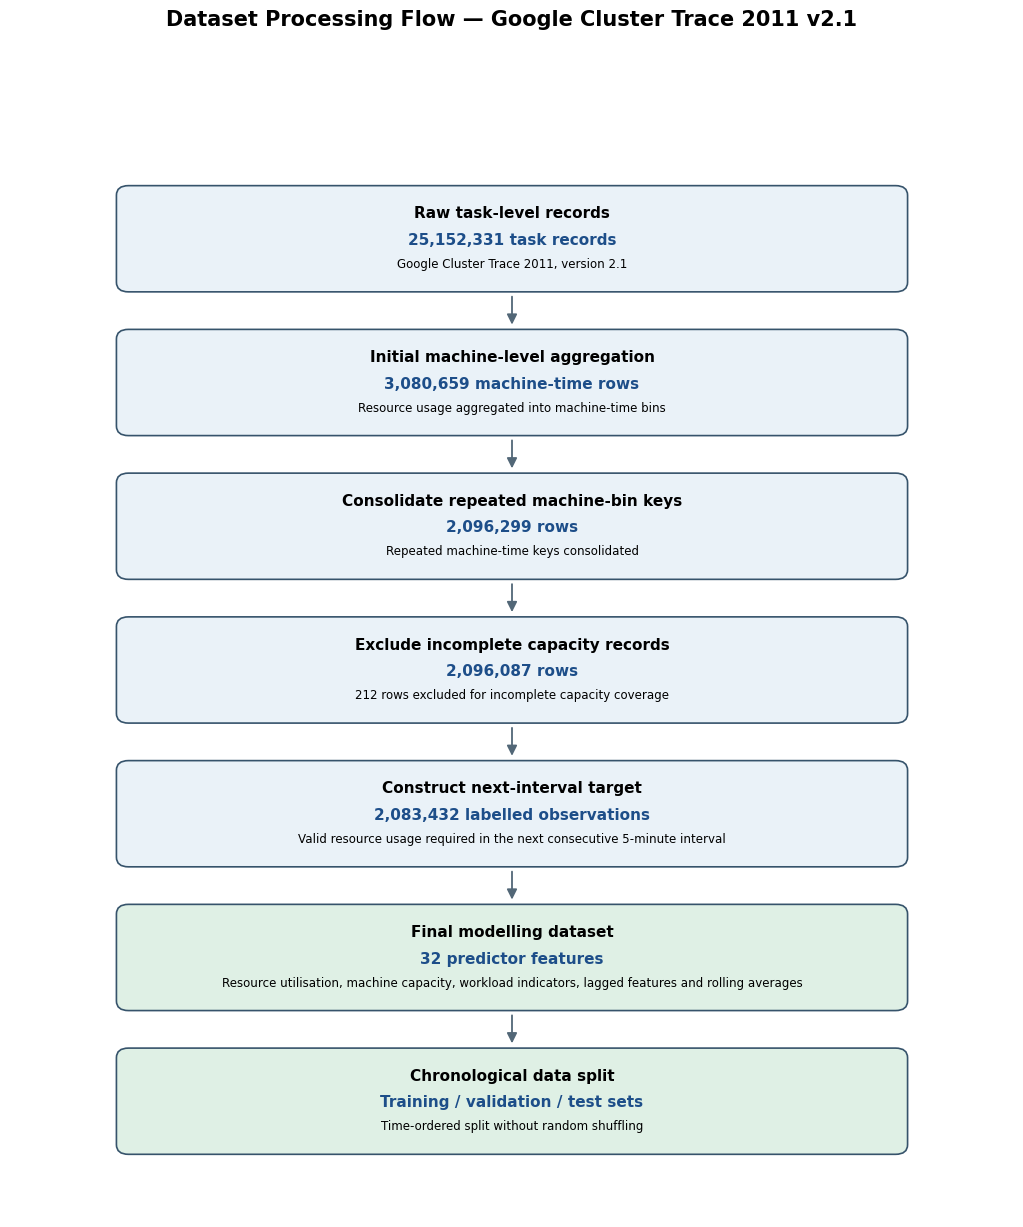

In [1]:
#Dataset-processing flow diagram

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 13))
ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.axis("off")

steps = [
    ("Raw task-level records",
     "25,152,331 task records",
     "Google Cluster Trace 2011, version 2.1"),

    ("Initial machine-level aggregation",
     "3,080,659 machine-time rows",
     "Resource usage aggregated into machine-time bins"),

    ("Consolidate repeated machine-bin keys",
     "2,096,299 rows",
     "Repeated machine-time keys consolidated"),

    ("Exclude incomplete capacity records",
     "2,096,087 rows",
     "212 rows excluded for incomplete capacity coverage"),

    ("Construct next-interval target",
     "2,083,432 labelled observations",
     "Valid resource usage required in the next consecutive 5-minute interval"),

    ("Final modelling dataset",
     "32 predictor features",
     "Resource utilisation, machine capacity, workload indicators, lagged features and rolling averages"),

    ("Chronological data split",
     "Training / validation / test sets",
     "Time-ordered split without random shuffling")
]

ys = [12.25, 10.45, 8.65, 6.85, 5.05, 3.25, 1.45]

for i, ((title, count, detail), y) in enumerate(zip(steps, ys)):
    color = "#DFF0E5" if i >= 5 else "#EAF2F8"

    box = FancyBboxPatch(
        (1.1, y - 0.625), 7.8, 1.25,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        linewidth=1.2,
        edgecolor="#36536B",
        facecolor=color
    )
    ax.add_patch(box)

    ax.text(5, y + 0.31, title,
            ha="center", va="center",
            fontsize=11, fontweight="bold")

    ax.text(5, y - 0.02, count,
            ha="center", va="center",
            fontsize=11, fontweight="bold",
            color="#1D4E89")

    ax.text(5, y - 0.32, detail,
            ha="center", va="center",
            fontsize=8.5, wrap=True)

    if i < len(steps) - 1:
        ax.add_patch(FancyArrowPatch(
            (5, y - 0.69),
            (5, ys[i + 1] + 0.69),
            arrowstyle="-|>",
            mutation_scale=15,
            linewidth=1.3,
            color="#526777"
        ))

fig.suptitle(
    "Dataset Processing Flow — Google Cluster Trace 2011 v2.1",
    fontsize=15,
    fontweight="bold",
    y=0.98
)


plt.tight_layout(rect=[0.03, 0.04, 0.97, 0.95])

# Save the figure at publication quality
plt.savefig(
    "Figure_1_Dataset_Processing_Flow.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


In [ ]:
#Split the labelled dataset chronologically

train_model_data = target_data[
    target_data["time_bin"].isin(train_bins)
].copy()

validation_model_data = target_data[
    target_data["time_bin"].isin(validation_bins)
].copy()

test_model_data = target_data[
    target_data["time_bin"].isin(test_bins)
].copy()

print("Labelled dataset split")
print("-" * 45)

for name, data in [
    ("Training", train_model_data),
    ("Validation", validation_model_data),
    ("Testing", test_model_data),
]:
    positive_count = int(data["overload_proxy_target"].sum())
    negative_count = len(data) - positive_count

    print(f"\n{name}:")
    print(f"  Records: {len(data):,}")
    print(f"  Time bins: {data['time_bin'].min()}–{data['time_bin'].max()}")
    print(f"  Normal: {negative_count:,} ({negative_count / len(data):.2%})")
    print(f"  High-resource: {positive_count:,} ({positive_count / len(data):.2%})")

# Verify time separation and row-count reconciliation
assert max(train_bins) < min(validation_bins)
assert max(validation_bins) < min(test_bins)

assert (
    len(train_model_data)
    + len(validation_model_data)
    + len(test_model_data)
    == len(target_data)
)

print("\nChronological separation and record-count checks passed.")
#(scikit-learn developers, n.d.; Lones, 2024; Sasse et al., 2025; Lones, 2024)

Labelled dataset split
---------------------------------------------

Training:
  Records: 1,459,599
  Time bins: 2–118
  Normal: 1,386,690 (95.00%)
  High-resource: 72,909 (5.00%)

Validation:
  Records: 311,907
  Time bins: 119–143
  Normal: 293,428 (94.08%)
  High-resource: 18,479 (5.92%)

Testing:
  Records: 311,926
  Time bins: 144–168
  Normal: 290,696 (93.19%)
  High-resource: 21,230 (6.81%)

Chronological separation and record-count checks passed.


In [ ]:
#Define model features and explicitly check for target leakage

candidate_features = [
    # Current-bin CPU and memory indicators
    "mean_cpu_usage_rate_duration_weighted_mean",
    "canonical_memory_usage_duration_weighted_mean",
    "assigned_memory_usage_duration_weighted_mean",
    "maximum_memory_usage_duration_weighted_mean",
    "maximum_cpu_usage_duration_weighted_mean",
    "mean_disk_io_time_duration_weighted_mean",
    "memory_capacity_relative_proxy",

    # Machine capacity information
    "cpu_capacity",
    "memory_capacity",

    # Current-bin workload and coverage information
    "task_interval_count",
    "observed_duration_seconds",
    "active_coverage_seconds",
    "coverage_fraction",
]

target_column = "overload_proxy_target"

# Verify all requested predictor columns exist
missing_features = [
    column for column in candidate_features
    if column not in target_data.columns
]

if missing_features:
    raise KeyError(f"Missing predictor columns: {missing_features}")

# Ensure that the target and future values are not predictor features
forbidden_features = {
    target_column,
    "next_time_bin",
    "next_cpu_usage_rate",
    "next_memory_proxy",
    "high_cpu_next_bin",
    "high_memory_next_bin",
    "has_valid_next_bin",
    "cpu_rate_bin_contribution",
    "time_bin_start_microseconds",
    "bin_start",
    "bin_end",
    "capacity_period_match_count",
}

leakage_features = set(candidate_features).intersection(forbidden_features)

if leakage_features:
    raise ValueError(f"Potential leakage features found: {sorted(leakage_features)}")

# Check missing and infinite predictor values in each split
for split_name, split_data in [
    ("Training", train_model_data),
    ("Validation", validation_model_data),
    ("Testing", test_model_data),
]:
    feature_frame = split_data[candidate_features]
    numeric_array = feature_frame.to_numpy(dtype=float)

    print(f"\n{split_name} feature checks")
    print(f"  Rows: {len(feature_frame):,}")
    print(f"  Missing predictor values: {int(feature_frame.isna().sum().sum()):,}")
    print(f"  Infinite predictor values: {int((~__import__('numpy').isfinite(numeric_array)).sum()):,}")

print("\nPredictor features:")
for feature in candidate_features:
    print(f"  - {feature}")

print(f"\nTarget column: {target_column}")
print("Explicit leakage checks passed.")
#(Lones, 2024; Sasse et al., 2025; Chandrashekar and Sahin, 2014)


Training feature checks
  Rows: 1,459,599
  Missing predictor values: 0
  Infinite predictor values: 0

Validation feature checks
  Rows: 311,907
  Missing predictor values: 0
  Infinite predictor values: 0

Testing feature checks
  Rows: 311,926
  Missing predictor values: 0
  Infinite predictor values: 0

Predictor features:
  - mean_cpu_usage_rate_duration_weighted_mean
  - canonical_memory_usage_duration_weighted_mean
  - assigned_memory_usage_duration_weighted_mean
  - maximum_memory_usage_duration_weighted_mean
  - maximum_cpu_usage_duration_weighted_mean
  - mean_disk_io_time_duration_weighted_mean
  - memory_capacity_relative_proxy
  - cpu_capacity
  - memory_capacity
  - task_interval_count
  - observed_duration_seconds
  - active_coverage_seconds
  - coverage_fraction

Target column: overload_proxy_target
Explicit leakage checks passed.


In [ ]:
#Check predictor variation before feature engineering

import numpy as np

feature_review = []

for column in candidate_features:
    series = train_model_data[column]

    feature_review.append({
        "feature": column,
        "unique_values": series.nunique(dropna=False),
        "missing_values": int(series.isna().sum()),
        "minimum": series.min(),
        "median": series.median(),
        "maximum": series.max(),
        "standard_deviation": series.std(),
    })

feature_review_df = pd.DataFrame(feature_review)

display(
    feature_review_df.round(6)
)

constant_features = feature_review_df.loc[
    feature_review_df["unique_values"] <= 1, "feature"
].tolist()

near_constant_features = feature_review_df.loc[
    feature_review_df["unique_values"] <= 2, "feature"
].tolist()

print("\nConstant features:", constant_features)
print("Features with at most two unique values:", near_constant_features)

print("\nCorrelation between numeric predictors:")
display(
    train_model_data[candidate_features]
    .corr()
    .round(3)
)

,feature,unique_values,missing_values,minimum,median,maximum,standard_deviation
0,mean_cpu_usage_rate_duration_weighted_mean,1443542,0,0.00000,0.014479,1.168693,0.011670
1,canonical_memory_usage_duration_weighted_mean,1417128,0,0.00000,0.018713,0.183685,0.012593
2,assigned_memory_usage_duration_weighted_mean,1230686,0,0.00000,0.024145,0.222335,0.015068
3,maximum_memory_usage_duration_weighted_mean,1417169,0,0.00000,0.019437,0.194895,0.012835
4,maximum_cpu_usage_duration_weighted_mean,1443042,0,0.00000,0.062925,67.400752,0.067343
5,mean_disk_io_time_duration_weighted_mean,1436209,0,0.00000,0.000605,0.252778,0.004569
6,memory_capacity_relative_proxy,1430668,0,0.00000,0.044443,0.614922,0.029694
7,cpu_capacity,3,0,0.25000,0.500000,1.000000,0.124872
8,memory_capacity,10,0,0.03085,0.499500,1.000000,0.201283
9,task_interval_count,69,0,1.00000,11.000000,324.000000,3.913398



Constant features: ['active_coverage_seconds', 'coverage_fraction']
Features with at most two unique values: ['active_coverage_seconds', 'coverage_fraction']

Correlation between numeric predictors:


,mean_cpu_usage_rate_duration_weighted_mean,canonical_memory_usage_duration_weighted_mean,assigned_memory_usage_duration_weighted_mean,maximum_memory_usage_duration_weighted_mean,maximum_cpu_usage_duration_weighted_mean,mean_disk_io_time_duration_weighted_mean,memory_capacity_relative_proxy,cpu_capacity,memory_capacity,task_interval_count,observed_duration_seconds,active_coverage_seconds,coverage_fraction
mean_cpu_usage_rate_duration_weighted_mean,1.000,0.321,0.384,0.357,0.407,0.313,0.153,0.088,0.221,-0.235,-0.277,NaN,NaN
canonical_memory_usage_duration_weighted_mean,0.321,1.000,0.973,0.996,0.232,0.077,0.697,0.202,0.399,-0.227,-0.242,NaN,NaN
assigned_memory_usage_duration_weighted_mean,0.384,0.973,1.000,0.977,0.250,0.108,0.679,0.194,0.402,-0.258,-0.280,NaN,NaN
maximum_memory_usage_duration_weighted_mean,0.357,0.996,0.977,1.000,0.246,0.096,0.680,0.202,0.414,-0.228,-0.245,NaN,NaN
maximum_cpu_usage_duration_weighted_mean,0.407,0.232,0.250,0.246,1.000,0.078,0.114,0.212,0.211,-0.057,-0.089,NaN,NaN
mean_disk_io_time_duration_weighted_mean,0.313,0.077,0.108,0.096,0.078,1.000,-0.018,-0.106,0.120,-0.032,-0.044,NaN,NaN
memory_capacity_relative_proxy,0.153,0.697,0.679,0.680,0.114,-0.018,1.000,-0.156,-0.257,-0.455,-0.497,NaN,NaN
cpu_capacity,0.088,0.202,0.194,0.202,0.212,-0.106,-0.156,1.000,0.687,0.340,0.397,NaN,NaN
memory_capacity,0.221,0.399,0.402,0.414,0.211,0.120,-0.257,0.687,1.000,0.317,0.362,NaN,NaN
task_interval_count,-0.235,-0.227,-0.258,-0.228,-0.057,-0.032,-0.455,0.340,0.317,1.000,0.848,NaN,NaN


In [ ]:
#Engineer lagged features and rolling averages by machine

BASE_RESOURCE_FEATURES = [
    "mean_cpu_usage_rate_duration_weighted_mean",
    "canonical_memory_usage_duration_weighted_mean",
    "assigned_memory_usage_duration_weighted_mean",
    "maximum_memory_usage_duration_weighted_mean",
    "maximum_cpu_usage_duration_weighted_mean",
    "mean_disk_io_time_duration_weighted_mean",
    "memory_capacity_relative_proxy",
]

STATIC_FEATURES = [
    "cpu_capacity",
    "memory_capacity",
]

WORKLOAD_FEATURES = [
    "task_interval_count",
    "observed_duration_seconds",
]

# Start from the complete machine-bin table, before removing rows
# that lack a valid future target.
feature_source = machine_bins_model.sort_values(
    ["machine_id", "time_bin"]
).copy()

grouped = feature_source.groupby("machine_id", sort=False)

# Add lag-1 and lag-2 features, but only when the source bin is
# the immediately preceding consecutive time bin.
for column in BASE_RESOURCE_FEATURES:
    feature_source[f"{column}_lag1"] = grouped[column].shift(1)
    feature_source[f"{column}_lag2"] = grouped[column].shift(2)

feature_source["previous_time_bin"] = grouped["time_bin"].shift(1)
feature_source["two_bins_back"] = grouped["time_bin"].shift(2)

consecutive_previous = (
    feature_source["previous_time_bin"]
    == feature_source["time_bin"] - 1
)

consecutive_two_back = (
    (feature_source["previous_time_bin"] == feature_source["time_bin"] - 1)
    & (feature_source["two_bins_back"] == feature_source["time_bin"] - 2)
)

# Invalidate lag values across gaps in a machine's time series.
for column in BASE_RESOURCE_FEATURES:
    feature_source.loc[
        ~consecutive_previous, f"{column}_lag1"
    ] = np.nan

    feature_source.loc[
        ~consecutive_two_back, f"{column}_lag2"
    ] = np.nan

# Three-bin rolling average: current bin plus the two preceding
# consecutive bins. If history is incomplete, retain the available
# current/lag values and calculate the mean from those available values.
for column in BASE_RESOURCE_FEATURES:
    feature_source[f"{column}_rolling3"] = feature_source[
        [column, f"{column}_lag1", f"{column}_lag2"]
    ].mean(axis=1)

# Build the final predictor list. The constant coverage features are omitted.
engineered_features = (
    BASE_RESOURCE_FEATURES
    + STATIC_FEATURES
    + WORKLOAD_FEATURES
    + [
        f"{column}_lag{lag}"
        for column in BASE_RESOURCE_FEATURES
        for lag in [1, 2]
    ]
    + [
        f"{column}_rolling3"
        for column in BASE_RESOURCE_FEATURES
    ]
)

# Attach only predictor columns to the labelled dataset.
feature_lookup = feature_source[
    ["machine_id", "time_bin"] + engineered_features
].copy()

target_data_engineered = target_data.drop(
    columns=[
        column for column in engineered_features
        if column in target_data.columns
    ],
    errors="ignore",
).merge(
    feature_lookup,
    on=["machine_id", "time_bin"],
    how="left",
    validate="one_to_one",
)

# Reapply the same chronological split boundaries.
train_model_data = target_data_engineered[
    target_data_engineered["time_bin"].isin(train_bins)
].copy()

validation_model_data = target_data_engineered[
    target_data_engineered["time_bin"].isin(validation_bins)
].copy()

test_model_data = target_data_engineered[
    target_data_engineered["time_bin"].isin(test_bins)
].copy()

print("Feature engineering summary")
print("-" * 45)
print(f"Base resource features: {len(BASE_RESOURCE_FEATURES)}")
print(f"Lagged features: {len(BASE_RESOURCE_FEATURES) * 2}")
print(f"Rolling-average features: {len(BASE_RESOURCE_FEATURES)}")
print(f"Total predictor features: {len(engineered_features)}")

print("\nRows retained:")
print(f"Training:   {len(train_model_data):,}")
print(f"Validation: {len(validation_model_data):,}")
print(f"Testing:    {len(test_model_data):,}")

print("\nMissing engineered values by split:")
for split_name, split_data in [
    ("Training", train_model_data),
    ("Validation", validation_model_data),
    ("Testing", test_model_data),
]:
    missing_count = int(split_data[engineered_features].isna().sum().sum())
    print(f"{split_name}: {missing_count:,}")

print("\nSample engineered features:")
display(
    train_model_data[
        ["machine_id", "time_bin", target_column]
        + BASE_RESOURCE_FEATURES[:2]
        + [
            f"{BASE_RESOURCE_FEATURES[0]}_lag1",
            f"{BASE_RESOURCE_FEATURES[0]}_lag2",
            f"{BASE_RESOURCE_FEATURES[0]}_rolling3",
        ]
    ].head(10).round(6)
)

print("\nFeature engineering completed.")
#(Wang et al., 2022; Devi and Valli, 2023; Gao et al., 2020; Lones, 2024; Sasse et al., 2025)

Feature engineering summary
---------------------------------------------
Base resource features: 7
Lagged features: 14
Rolling-average features: 7
Total predictor features: 32

Rows retained:
Training:   1,459,599
Validation: 311,907
Testing:    311,926

Missing engineered values by split:
Training: 264,397
Validation: 777
Testing: 525

Sample engineered features:


,machine_id,time_bin,overload_proxy_target,mean_cpu_usage_rate_duration_weighted_mean,canonical_memory_usage_duration_weighted_mean,mean_cpu_usage_rate_duration_weighted_mean_lag1,mean_cpu_usage_rate_duration_weighted_mean_lag2,mean_cpu_usage_rate_duration_weighted_mean_rolling3
0,5,2,0,0.007077,0.006389,NaN,NaN,0.007077
1,5,3,0,0.007390,0.006373,0.007077,NaN,0.007234
2,5,4,0,0.006373,0.006253,0.007390,0.007077,0.006947
3,5,5,0,0.007315,0.006258,0.006373,0.007390,0.007026
4,5,6,0,0.006974,0.006189,0.007315,0.006373,0.006887
5,5,7,0,0.006899,0.006294,0.006974,0.007315,0.007063
6,5,8,0,0.006853,0.006375,0.006899,0.006974,0.006909
7,5,9,0,0.003540,0.006223,0.006853,0.006899,0.005764
8,5,10,0,0.002985,0.006255,0.003540,0.006853,0.004459
9,5,11,0,0.003258,0.006364,0.002985,0.003540,0.003261



Feature engineering completed.


In [ ]:
#Diagnose missing values in engineered predictors

lagged_features = [
    f"{column}_lag{lag}"
    for column in BASE_RESOURCE_FEATURES
    for lag in [1, 2]
]

rolling_features = [
    f"{column}_rolling3"
    for column in BASE_RESOURCE_FEATURES
]

print("Missing values by feature")
print("-" * 50)

missing_summary = pd.DataFrame({
    "training_missing": train_model_data[engineered_features].isna().sum(),
    "validation_missing": validation_model_data[engineered_features].isna().sum(),
    "testing_missing": test_model_data[engineered_features].isna().sum(),
})

missing_summary["training_missing_pct"] = (
    missing_summary["training_missing"] / len(train_model_data) * 100
).round(3)

display(missing_summary.sort_values(
    "training_missing", ascending=False
))

# Examine how many previous consecutive bins are available per record.
history_check = feature_source[
    ["machine_id", "time_bin", "previous_time_bin", "two_bins_back"]
].copy()

history_check["has_lag1_history"] = (
    history_check["previous_time_bin"] == history_check["time_bin"] - 1
)

history_check["has_lag2_history"] = (
    (history_check["previous_time_bin"] == history_check["time_bin"] - 1)
    & (history_check["two_bins_back"] == history_check["time_bin"] - 2)
)

history_check["history_category"] = np.select(
    [
        ~history_check["has_lag1_history"],
        history_check["has_lag1_history"] & ~history_check["has_lag2_history"],
        history_check["has_lag2_history"],
    ],
    [
        "No previous consecutive bin",
        "One previous consecutive bin",
        "Two previous consecutive bins",
    ],
    default="Other",
)

print("\nAvailable consecutive history across all machine-bin records:")
display(
    history_check["history_category"]
    .value_counts()
    .to_frame("record_count")
    .assign(
        percentage=lambda df: (
            df["record_count"] / len(history_check) * 100
        ).round(3)
    )
)

print("\nRolling feature missing-value check:")
print(
    "Missing rolling-average cells:",
    int(train_model_data[rolling_features].isna().sum().sum()),
)
#(Ehrlinger and Wob, 2022; Fernandes et al., 2023; Wang et al., 2022; Lones, 2024)

Missing values by feature
--------------------------------------------------


,training_missing,validation_missing,testing_missing,training_missing_pct
assigned_memory_usage_duration_weighted_mean_lag2,25180,74,50,1.725
memory_capacity_relative_proxy_lag2,25180,74,50,1.725
maximum_memory_usage_duration_weighted_mean_lag2,25180,74,50,1.725
canonical_memory_usage_duration_weighted_mean_lag2,25180,74,50,1.725
mean_cpu_usage_rate_duration_weighted_mean_lag2,25180,74,50,1.725
maximum_cpu_usage_duration_weighted_mean_lag2,25180,74,50,1.725
mean_disk_io_time_duration_weighted_mean_lag2,25180,74,50,1.725
memory_capacity_relative_proxy_lag1,12591,37,25,0.863
mean_cpu_usage_rate_duration_weighted_mean_lag1,12591,37,25,0.863
canonical_memory_usage_duration_weighted_mean_lag1,12591,37,25,0.863



Available consecutive history across all machine-bin records:


,record_count,percentage
history_category,,
Two previous consecutive bins,2070779,98.793
No previous consecutive bin,12655,0.604
One previous consecutive bin,12653,0.604



Rolling feature missing-value check:
Missing rolling-average cells: 0


In [ ]:
#Prepare feature matrices and inspect training-only imputation values

from sklearn.impute import SimpleImputer

target_column = "overload_proxy_target"

# Confirm the final predictor list excludes constant coverage columns
assert "active_coverage_seconds" not in engineered_features
assert "coverage_fraction" not in engineered_features

# Create predictor matrices and target vectors
X_train = train_model_data[engineered_features].copy()
y_train = train_model_data[target_column].astype("int8").copy()

X_validation = validation_model_data[engineered_features].copy()
y_validation = validation_model_data[target_column].astype("int8").copy()

X_test = test_model_data[engineered_features].copy()
y_test = test_model_data[target_column].astype("int8").copy()

# Fit the imputer using training data only
imputer = SimpleImputer(strategy="median")
X_train_imputed_array = imputer.fit_transform(X_train)

# Apply the same fitted imputer to validation and test data
X_validation_imputed_array = imputer.transform(X_validation)
X_test_imputed_array = imputer.transform(X_test)

# Restore DataFrame structure and feature names
X_train_imputed = pd.DataFrame(
    X_train_imputed_array,
    columns=engineered_features,
    index=X_train.index,
)

X_validation_imputed = pd.DataFrame(
    X_validation_imputed_array,
    columns=engineered_features,
    index=X_validation.index,
)

X_test_imputed = pd.DataFrame(
    X_test_imputed_array,
    columns=engineered_features,
    index=X_test.index,
)

print("Feature matrix shapes")
print("-" * 40)
print("Training:", X_train_imputed.shape)
print("Validation:", X_validation_imputed.shape)
print("Testing:", X_test_imputed.shape)

print("\nMissing values after imputation")
print("Training:", int(X_train_imputed.isna().sum().sum()))
print("Validation:", int(X_validation_imputed.isna().sum().sum()))
print("Testing:", int(X_test_imputed.isna().sum().sum()))

print("\nTraining-only medians for lagged features:")
display(
    pd.DataFrame({
        "feature": lagged_features,
        "training_median": [
            X_train[column].median() for column in lagged_features
        ],
    }).round(6)
)

print("\nTarget distribution:")
print("Training positive rate:", f"{y_train.mean():.2%}")
print("Validation positive rate:", f"{y_validation.mean():.2%}")
print("Testing positive rate:", f"{y_test.mean():.2%}")

assert X_train_imputed.shape[1] == len(engineered_features)
assert X_validation_imputed.shape[1] == len(engineered_features)
assert X_test_imputed.shape[1] == len(engineered_features)

assert X_train_imputed.isna().sum().sum() == 0
assert X_validation_imputed.isna().sum().sum() == 0
assert X_test_imputed.isna().sum().sum() == 0

print("\nImputation and matrix checks passed.")


Feature matrix shapes
----------------------------------------
Training: (1459599, 32)
Validation: (311907, 32)
Testing: (311926, 32)

Missing values after imputation
Training: 0
Validation: 0
Testing: 0

Training-only medians for lagged features:


,feature,training_median
0,mean_cpu_usage_rate_duration_weighted_mean_lag1,0.014474
1,mean_cpu_usage_rate_duration_weighted_mean_lag2,0.014466
2,canonical_memory_usage_duration_weighted_mean_...,0.018722
3,canonical_memory_usage_duration_weighted_mean_...,0.018731
4,assigned_memory_usage_duration_weighted_mean_lag1,0.024155
5,assigned_memory_usage_duration_weighted_mean_lag2,0.024165
6,maximum_memory_usage_duration_weighted_mean_lag1,0.019444
7,maximum_memory_usage_duration_weighted_mean_lag2,0.019452
8,maximum_cpu_usage_duration_weighted_mean_lag1,0.062968
9,maximum_cpu_usage_duration_weighted_mean_lag2,0.062987



Target distribution:
Training positive rate: 5.00%
Validation positive rate: 5.92%
Testing positive rate: 6.81%

Imputation and matrix checks passed.


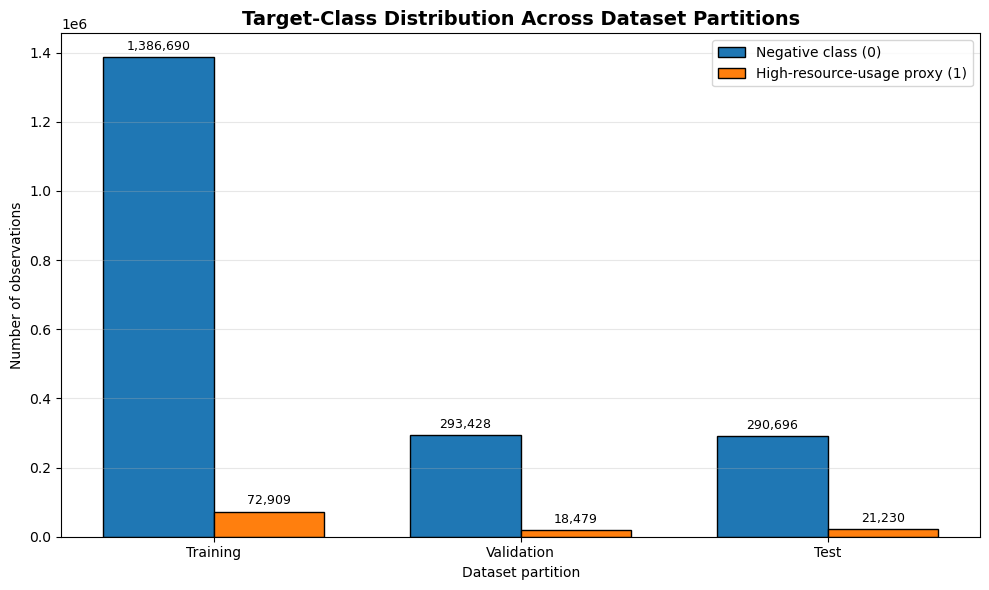

In [ ]:
# Target-Class Distribution

import numpy as np
import matplotlib.pyplot as plt

partitions = ["Training", "Validation", "Test"]

negative_counts = [1386690, 293428, 290696]
positive_counts = [72909, 18479, 21230]

x = np.arange(len(partitions))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 6))

negative_bars = ax.bar(
    x - width / 2,
    negative_counts,
    width,
    label="Negative class (0)",
    edgecolor="black"
)

positive_bars = ax.bar(
    x + width / 2,
    positive_counts,
    width,
    label="High-resource-usage proxy (1)",
    edgecolor="black"
)


# Display counts with thousands separators
ax.bar_label(
    negative_bars,
    labels=[f"{v:,}" for v in negative_counts],
    padding=3,
    fontsize=9
)

ax.bar_label(
    positive_bars,
    labels=[f"{v:,}" for v in positive_counts],
    padding=3,
    fontsize=9
)


ax.set_title(
    "Target-Class Distribution Across Dataset Partitions",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Dataset partition")
ax.set_ylabel("Number of observations")
ax.set_xticks(x)
ax.set_xticklabels(partitions)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "Figure_2_Target_Class_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:
#Configure chronological cross-validation

from sklearn.model_selection import TimeSeriesSplit

# Use the original training features and labels.
# Do not use the validation or test sets for cross-validation.
X_tuning = X_train.copy()
y_tuning = y_train.copy()

# Create five expanding-window chronological folds.
tscv = TimeSeriesSplit(n_splits=5)

print("Chronological cross-validation configuration")
print("-" * 50)
print("Training feature shape:", X_tuning.shape)
print("Training target shape:", y_tuning.shape)
print("Number of folds:", tscv.n_splits)

# Check the chronological order of the folds.
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_tuning), start=1
):
    print(f"\nFold {fold}")
    print(f"Training records:   {len(train_idx):,}")
    print(f"Validation records: {len(val_idx):,}")
    print(
        f"Training row indices: {train_idx[0]:,}–{train_idx[-1]:,}"
    )
    print(
        f"Validation row indices: {val_idx[0]:,}–{val_idx[-1]:,}"
    )

    assert train_idx[-1] < val_idx[0], (
        "Error: training data must precede validation data."
    )

print("\nAll folds preserve chronological row order.")
#(scikit-learn developers, n.d.; Devi and Valli, 2023; Lones, 2024; Sasse et al., 2025)


Chronological cross-validation configuration
--------------------------------------------------
Training feature shape: (1459599, 32)
Training target shape: (1459599,)
Number of folds: 5

Fold 1
Training records:   243,269
Validation records: 243,266
Training row indices: 0–243,268
Validation row indices: 243,269–486,534

Fold 2
Training records:   486,535
Validation records: 243,266
Training row indices: 0–486,534
Validation row indices: 486,535–729,800

Fold 3
Training records:   729,801
Validation records: 243,266
Training row indices: 0–729,800
Validation row indices: 729,801–973,066

Fold 4
Training records:   973,067
Validation records: 243,266
Training row indices: 0–973,066
Validation row indices: 973,067–1,216,332

Fold 5
Training records:   1,216,333
Validation records: 243,266
Training row indices: 0–1,216,332
Validation row indices: 1,216,333–1,459,598

All folds preserve chronological row order.


In [ ]:
#Identify the time-bin column for cross-validation

print("Available columns in the training data:")
print(train_model_data.columns.tolist())

print("\nAvailable columns in the engineered target data:")
print(target_data_engineered.columns.tolist())

print("\nTraining data index information:")
print("Index type:", type(train_model_data.index).__name__)
print("Index name:", train_model_data.index.name)
print("Index sample:", train_model_data.index[:5].tolist())


Available columns in the training data:
['machine_id', 'time_bin', 'cpu_rate_bin_contribution', 'time_bin_start_microseconds', 'mean_cpu_usage_rate_weighted_sum', 'canonical_memory_usage_weighted_sum', 'assigned_memory_usage_weighted_sum', 'maximum_memory_usage_weighted_sum', 'maximum_cpu_usage_weighted_sum', 'mean_disk_io_time_weighted_sum', 'active_coverage_seconds', 'coverage_fraction', 'coverage_category', 'overlapping_capacity_seconds', 'has_full_capacity_coverage', 'bin_start', 'bin_end', 'capacity_period_match_count', 'next_time_bin', 'next_cpu_usage_rate', 'next_memory_proxy', 'has_valid_next_bin', 'high_cpu_next_bin', 'high_memory_next_bin', 'overload_proxy_target', 'mean_cpu_usage_rate_duration_weighted_mean', 'canonical_memory_usage_duration_weighted_mean', 'assigned_memory_usage_duration_weighted_mean', 'maximum_memory_usage_duration_weighted_mean', 'maximum_cpu_usage_duration_weighted_mean', 'mean_disk_io_time_duration_weighted_mean', 'memory_capacity_relative_proxy', 'cpu

In [ ]:
#Create time-bin-aware chronological cross-validation

import numpy as np
from sklearn.model_selection import TimeSeriesSplit

# Extract the training rows and their corresponding time bins.
# The feature matrix and target must retain the same row order.
X_tuning = X_train.copy()
y_tuning = np.asarray(y_train).reshape(-1)

training_time_bins = train_model_data["time_bin"].to_numpy()

# Verify that all arrays refer to the same rows.
assert len(X_tuning) == len(y_tuning) == len(training_time_bins), (
    "Feature, target, and time-bin lengths do not match."
)

# Obtain the ordered unique time bins.
unique_time_bins = np.sort(np.unique(training_time_bins))

# Split the unique time bins, not individual machine records.
tscv = TimeSeriesSplit(n_splits=5)

print("Time-bin-aware chronological cross-validation")
print("=" * 55)
print("Training records:", f"{len(X_tuning):,}")
print("Unique time bins:", len(unique_time_bins))
print("Number of folds:", tscv.n_splits)

# Build row indices for each fold.
time_bin_folds = []

for fold, (train_bin_idx, val_bin_idx) in enumerate(
    tscv.split(unique_time_bins), start=1
):
    fold_train_bins = unique_time_bins[train_bin_idx]
    fold_val_bins = unique_time_bins[val_bin_idx]

    # Keep every row belonging to a time bin together.
    train_idx = np.flatnonzero(
        np.isin(training_time_bins, fold_train_bins)
    )
    val_idx = np.flatnonzero(
        np.isin(training_time_bins, fold_val_bins)
    )

    # Confirm the training period precedes the validation period.
    assert fold_train_bins.max() < fold_val_bins.min()

    # Confirm no time bins overlap across the two sets.
    assert set(fold_train_bins).isdisjoint(set(fold_val_bins))

    time_bin_folds.append((train_idx, val_idx))

    print(f"\nFold {fold}")
    print("Training time bins:",
          f"{fold_train_bins.min()}–{fold_train_bins.max()}")
    print("Validation time bins:",
          f"{fold_val_bins.min()}–{fold_val_bins.max()}")
    print("Training records:", f"{len(train_idx):,}")
    print("Validation records:", f"{len(val_idx):,}")

print("\nAll folds keep time bins together and preserve chronology.")


Time-bin-aware chronological cross-validation
Training records: 1,459,599
Unique time bins: 117
Number of folds: 5

Fold 1
Training time bins: 2–23
Validation time bins: 24–42
Training records: 274,391
Validation records: 236,959

Fold 2
Training time bins: 2–42
Validation time bins: 43–61
Training records: 511,350
Validation records: 237,079

Fold 3
Training time bins: 2–61
Validation time bins: 62–80
Training records: 748,429
Validation records: 237,071

Fold 4
Training time bins: 2–80
Validation time bins: 81–99
Training records: 985,500
Validation records: 237,008

Fold 5
Training time bins: 2–99
Validation time bins: 100–118
Training records: 1,222,508
Validation records: 237,091

All folds keep time bins together and preserve chronology.


In [ ]:
#Random Forest hyperparameter tuning

import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Pipeline ensures imputation is fitted independently within each CV fold.
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Small parameter grid to limit computational cost.
rf_param_grid = {
    "classifier__n_estimators": [100],
    "classifier__max_depth": [15, 20],
    "classifier__min_samples_leaf": [5, 10]
}

rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=time_bin_folds,
    n_jobs=1,
    verbose=2,
    refit=True,
    return_train_score=False
)

print("Starting Random Forest hyperparameter tuning...")
print("Parameter combinations:", len(rf_param_grid["classifier__n_estimators"])
      * len(rf_param_grid["classifier__max_depth"])
      * len(rf_param_grid["classifier__min_samples_leaf"]))
print("Cross-validation folds:", len(time_bin_folds))
print("Total model fits:", len(time_bin_folds) * 4)

rf_grid_search.fit(X_tuning, y_tuning)

print("\nRandom Forest tuning complete.")
print("Best parameters:")
print(rf_grid_search.best_params_)
print(f"Best mean cross-validation F1-score: "
      f"{rf_grid_search.best_score_:.4f}")
#(Breiman, 2001; Breskuviene and Dzemyda, 2024; Gaudreault and Branco, 2024; scikit-learn developers, n.d.; Lones, 2024)

Starting Random Forest hyperparameter tuning...
Parameter combinations: 4
Cross-validation folds: 5
Total model fits: 20
Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=5, classifier__n_estimators=100; total time=  23.5s
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=5, classifier__n_estimators=100; total time=  49.8s
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=5, classifier__n_estimators=100; total time= 1.3min
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=5, classifier__n_estimators=100; total time= 1.8min
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=5, classifier__n_estimators=100; total time= 2.2min
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=10, classifier__n_estimators=100; total time=  23.2s
[CV] END classifier__max_depth=15, classifier__min_samples_leaf=10, classifier__n_estimators=100; total time=  48.4s
[CV] 

In [ ]:
#Compare Random Forest hyperparameter combinations

import pandas as pd
from IPython.display import display as show_table

rf_cv_results = pd.DataFrame(rf_grid_search.cv_results_)

rf_results_summary = rf_cv_results[
    [
        "param_classifier__n_estimators",
        "param_classifier__max_depth",
        "param_classifier__min_samples_leaf",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].copy()

rf_results_summary = rf_results_summary.rename(
    columns={
        "param_classifier__n_estimators": "Number of Trees",
        "param_classifier__max_depth": "Maximum Depth",
        "param_classifier__min_samples_leaf": "Minimum Samples per Leaf",
        "mean_test_score": "Mean CV F1-Score",
        "std_test_score": "F1-Score Standard Deviation",
        "rank_test_score": "Rank"
    }
)

rf_results_summary = rf_results_summary.sort_values("Rank")

show_table(rf_results_summary.round(4))

,Number of Trees,Maximum Depth,Minimum Samples per Leaf,Mean CV F1-Score,F1-Score Standard Deviation,Rank
2,100,20,5,0.7968,0.0233,1
3,100,20,10,0.7807,0.0246,2
0,100,15,5,0.7667,0.0214,3
1,100,15,10,0.7590,0.0219,4


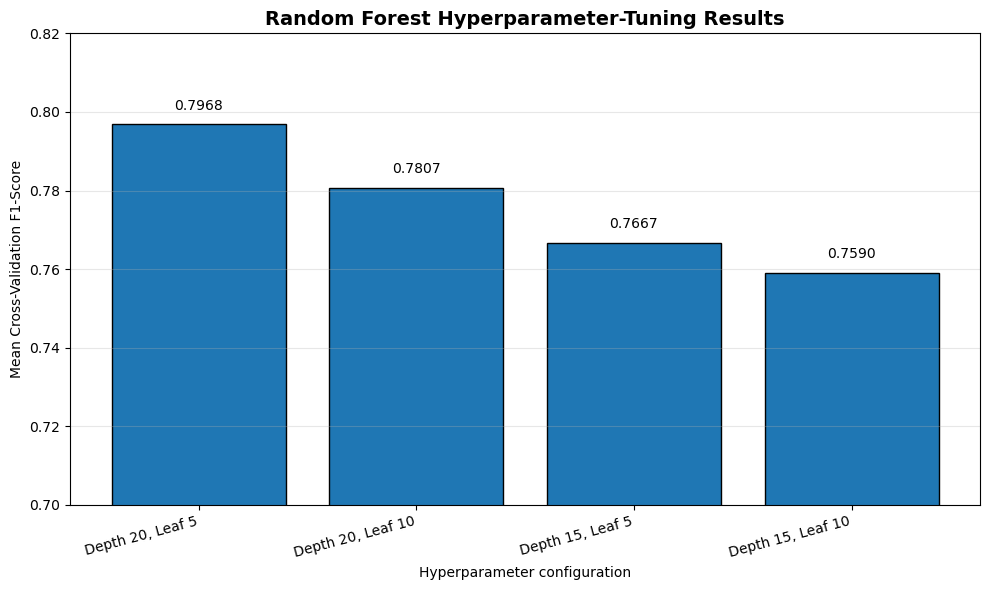

In [ ]:
#Random Forest Hyperparameter-Tuning Results

import matplotlib.pyplot as plt

configurations = [
    "Depth 20, Leaf 5",
    "Depth 20, Leaf 10",
    "Depth 15, Leaf 5",
    "Depth 15, Leaf 10"
]

cv_f1_scores = [
    0.7968,
    0.7807,
    0.7667,
    0.7590
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    configurations,
    cv_f1_scores,
    edgecolor="black"
)

for bar, score in zip(bars, cv_f1_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.003,
        f"{score:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title(
    "Random Forest Hyperparameter-Tuning Results",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Hyperparameter configuration")
plt.ylabel("Mean Cross-Validation F1-Score")
plt.ylim(0.70, 0.82)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Figure_3_Random_Forest_Tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
#(Breiman, 2001; scikit-learn developers, n.d.; Gaudreault and Branco, 2024; Rainio et al., 2024)

In [ ]:
#Retrieve the best Random Forest model

best_random_forest_model = rf_grid_search.best_estimator_

print("Best Random Forest model retrieved successfully.")
print("\nBest parameters:")
print(rf_grid_search.best_params_)

print(
    f"\nBest mean cross-validation F1-score: "
    f"{rf_grid_search.best_score_:.4f}"
)

print("\nBest model pipeline:")
print(best_random_forest_model)
#(Breiman, 2001; scikit-learn developers, n.d.; Lones, 2024)

Best Random Forest model retrieved successfully.

Best parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}

Best mean cross-validation F1-score: 0.7968

Best model pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=20,
                                        min_samples_leaf=5, n_jobs=-1,
                                        random_state=42))])


In [ ]:
#Evaluate the tuned Random Forest against the Dummy baseline

import time
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Train the Dummy baseline

dummy_model = DummyClassifier(strategy="most_frequent")

start_time = time.time()
dummy_model.fit(X_train_imputed, y_train)
dummy_training_seconds = time.time() - start_time

start_time = time.time()
dummy_predictions = dummy_model.predict(X_validation_imputed)
dummy_prediction_seconds = time.time() - start_time

dummy_probabilities = dummy_model.predict_proba(
    X_validation_imputed
)[:, 1]

# Retrieve the tuned Random Forest

# This pipeline was already fitted by GridSearchCV.
# It includes the training-fold-fitted median imputer.
best_random_forest_model = rf_grid_search.best_estimator_

# Use the original validation features.
# The pipeline applies its fitted imputer automatically.
start_time = time.time()
rf_validation_predictions = best_random_forest_model.predict(
    X_validation
)
rf_prediction_seconds = time.time() - start_time

start_time = time.time()
rf_validation_probabilities = best_random_forest_model.predict_proba(
    X_validation
)[:, 1]
rf_probability_seconds = time.time() - start_time

# Calculate evaluation metrics

def calculate_classification_metrics(
    y_true, predictions, probabilities
):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC (average precision)": average_precision_score(
            y_true, probabilities
        )
    }

validation_results = pd.DataFrame({
    "Dummy baseline": calculate_classification_metrics(
        y_validation,
        dummy_predictions,
        dummy_probabilities
    ),
    "Tuned Random Forest": calculate_classification_metrics(
        y_validation,
        rf_validation_predictions,
        rf_validation_probabilities
    )
}).T

print("Validation performance")
show_table(validation_results.round(4))

# Compare prediction times

timing_results = pd.DataFrame({
    "Model": ["Dummy baseline", "Tuned Random Forest"],
    "Prediction time (seconds)": [
        dummy_prediction_seconds,
        rf_prediction_seconds
    ],
    "Probability calculation time (seconds)": [
        0.0,
        rf_probability_seconds
    ]
})

print("\nValidation prediction times")
show_table(timing_results.round(3))

print("\nTuned Random Forest classification report")
print(
    classification_report(
        y_validation,
        rf_validation_predictions,
        labels=[0, 1],
        target_names=["Normal", "High-resource"],
        zero_division=0
    )
)

print("\nTuned Random Forest confusion matrix")
show_table(pd.DataFrame(
    confusion_matrix(
        y_validation,
        rf_validation_predictions,
        labels=[0, 1]
    ),
    index=["Actual normal", "Actual high-resource"],
    columns=["Predicted normal", "Predicted high-resource"]
))

print("\nBest Random Forest parameters:")
print(rf_grid_search.best_params_)

print(
    f"Mean cross-validation F1-score: "
    f"{rf_grid_search.best_score_:.4f}"
)
#(Breiman, 2001; Chicco and Jurman, 2020; Saito and Rehmsmeier, 2015; Richardson et al., 2024; Gaudreault and Branco, 2024; Rainio et al., 2024)

Validation performance


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC (average precision)
Dummy baseline,0.9408,0.0000,0.0000,0.0000,0.5000,0.0592
Tuned Random Forest,0.9675,0.6725,0.8803,0.7625,0.9872,0.8734



Validation prediction times


,Model,Prediction time (seconds),Probability calculation time (seconds)
0,Dummy baseline,0.003,0.000
1,Tuned Random Forest,0.475,0.522



Tuned Random Forest classification report
               precision    recall  f1-score   support

       Normal       0.99      0.97      0.98    293428
High-resource       0.67      0.88      0.76     18479

     accuracy                           0.97    311907
    macro avg       0.83      0.93      0.87    311907
 weighted avg       0.97      0.97      0.97    311907


Tuned Random Forest confusion matrix


,Predicted normal,Predicted high-resource
Actual normal,285507,7921
Actual high-resource,2212,16267



Best Random Forest parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Mean cross-validation F1-score: 0.7968


In [ ]:
#Tune and evaluate Logistic Regression using TimeSeriesSplit

import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Build the preprocessing and model pipeline

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ))
])

# Define the hyperparameter search

logistic_param_grid = {
    "classifier__C": [0.1, 1.0, 10.0]
}

# Tune using the existing time-bin folds

logistic_grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring="f1",
    cv=time_bin_folds,
    n_jobs=1,
    verbose=2,
    refit=True,
    return_train_score=True
)

print("Starting Logistic Regression GridSearchCV...")

start_time = time.time()

logistic_grid_search.fit(X_train, y_train)

logistic_tuning_time = time.time() - start_time

# GridSearchCV refits the best pipeline on all training data.
logistic_regression_model = logistic_grid_search.best_estimator_

print("\nLogistic Regression tuning completed.")
print(f"Total tuning and refitting time: {logistic_tuning_time:.2f} seconds")

print("\nBest Logistic Regression parameters:")
print(logistic_grid_search.best_params_)

print(
    "Best mean cross-validation F1-score: "
    f"{logistic_grid_search.best_score_:.4f}"
)

# Review cross-validation results

logistic_cv_results = pd.DataFrame(
    logistic_grid_search.cv_results_
)[[
    "param_classifier__C",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].sort_values("rank_test_score")

logistic_cv_results = logistic_cv_results.rename(columns={
    "param_classifier__C": "C",
    "mean_test_score": "Mean CV F1-score",
    "std_test_score": "CV F1 standard deviation",
    "rank_test_score": "Rank"
})

print("\nLogistic Regression cross-validation results:")
show_table(logistic_cv_results.round(4))

# Evaluate the tuned model on validation data

start_time = time.time()

logistic_validation_predictions = logistic_regression_model.predict(
    X_validation
)

logistic_prediction_time = time.time() - start_time

logistic_validation_probabilities = (
    logistic_regression_model.predict_proba(X_validation)[:, 1]
)

# Calculate validation metrics

logistic_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(
        y_validation, logistic_validation_predictions
    ),
    "Precision": precision_score(
        y_validation, logistic_validation_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, logistic_validation_predictions,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, logistic_validation_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, logistic_validation_probabilities
    ),
    "PR-AUC (average precision)": average_precision_score(
        y_validation, logistic_validation_probabilities
    ),
    "Tuning and refitting time (seconds)": logistic_tuning_time,
    "Prediction time (seconds)": logistic_prediction_time
}

print("\nTuned Logistic Regression validation performance:")
show_table(pd.DataFrame([logistic_results]).round(4))

# Classification report

print("\nTuned Logistic Regression classification report:")

print(classification_report(
    y_validation,
    logistic_validation_predictions,
    labels=[0, 1],
    target_names=["Normal", "High-resource"],
    zero_division=0
))

# Confusion matrix

print("\nTuned Logistic Regression confusion matrix:")

show_table(pd.DataFrame(
    confusion_matrix(
        y_validation,
        logistic_validation_predictions,
        labels=[0, 1]
    ),
    index=["Actual normal", "Actual high-resource"],
    columns=["Predicted normal", "Predicted high-resource"]
))
#(Alshammari et al., 2026; James et al., 2021; Breskuviene and Dzemyda, 2024; Gaudreault and Branco, 2024; Rainio et al., 2024; scikit-learn developers, n.d.)

Starting Logistic Regression GridSearchCV...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV] END ..................................classifier__C=0.1; total time=   1.5s
[CV] END ..................................classifier__C=0.1; total time=   2.6s
[CV] END ..................................classifier__C=0.1; total time=   4.4s
[CV] END ..................................classifier__C=0.1; total time=   6.0s
[CV] END ..................................classifier__C=0.1; total time=   7.2s
[CV] END ..................................classifier__C=1.0; total time=   1.5s
[CV] END ..................................classifier__C=1.0; total time=   2.6s
[CV] END ..................................classifier__C=1.0; total time=   4.8s
[CV] END ..................................classifier__C=1.0; total time=   6.2s
[CV] END ..................................classifier__C=1.0; total time=   8.1s
[CV] END .................................classifier__C=10.0; total time=   1.7s
[CV]

,C,Mean CV F1-score,CV F1 standard deviation,Rank
2,10.0,0.6226,0.0284,1
1,1.0,0.6191,0.0262,2
0,0.1,0.6045,0.0208,3



Tuned Logistic Regression validation performance:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC (average precision),Tuning and refitting time (seconds),Prediction time (seconds)
0,Tuned Logistic Regression,0.9247,0.4381,0.9621,0.6021,0.9846,0.8359,85.6945,0.1188



Tuned Logistic Regression classification report:
               precision    recall  f1-score   support

       Normal       1.00      0.92      0.96    293428
High-resource       0.44      0.96      0.60     18479

     accuracy                           0.92    311907
    macro avg       0.72      0.94      0.78    311907
 weighted avg       0.96      0.92      0.94    311907


Tuned Logistic Regression confusion matrix:


,Predicted normal,Predicted high-resource
Actual normal,270630,22798
Actual high-resource,701,17778


In [ ]:
#Tune and evaluate Linear SVM using TimeSeriesSplit

import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Build the preprocessing and SVM pipeline

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("classifier", LinearSVC(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# Define the hyperparameter search

svm_param_grid = {
    "classifier__C": [0.1, 1.0, 10.0]
}

# Tune using the existing time-bin folds

svm_grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1",
    cv=time_bin_folds,
    n_jobs=1,
    verbose=2,
    refit=True,
    return_train_score=True
)

print("Starting Linear SVM GridSearchCV...")

start_time = time.time()

svm_grid_search.fit(X_train, y_train)

svm_tuning_time = time.time() - start_time

# GridSearchCV refits the best pipeline on all training data.
svm_model = svm_grid_search.best_estimator_

print("\nLinear SVM tuning completed.")
print(f"Total tuning and refitting time: {svm_tuning_time:.2f} seconds")

print("\nBest Linear SVM parameters:")
print(svm_grid_search.best_params_)

print(
    "Best mean cross-validation F1-score: "
    f"{svm_grid_search.best_score_:.4f}"
)

# Review cross-validation results

svm_cv_results = pd.DataFrame(
    svm_grid_search.cv_results_
)[[
    "param_classifier__C",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].sort_values("rank_test_score")

svm_cv_results = svm_cv_results.rename(columns={
    "param_classifier__C": "C",
    "mean_test_score": "Mean CV F1-score",
    "std_test_score": "CV F1 standard deviation",
    "rank_test_score": "Rank"
})

print("\nLinear SVM cross-validation results:")
show_table(svm_cv_results.round(4))

# Evaluate the tuned model on validation data

start_time = time.time()

svm_validation_predictions = svm_model.predict(X_validation)

svm_validation_scores = svm_model.decision_function(X_validation)

svm_prediction_time = time.time() - start_time

# Calculate validation metrics

svm_results = {
    "Model": "Tuned Linear SVM",
    "Accuracy": accuracy_score(
        y_validation, svm_validation_predictions
    ),
    "Precision": precision_score(
        y_validation, svm_validation_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_validation, svm_validation_predictions,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_validation, svm_validation_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_validation, svm_validation_scores
    ),
    "PR-AUC (average precision)": average_precision_score(
        y_validation, svm_validation_scores
    ),
    "Tuning and refitting time (seconds)": svm_tuning_time,
    "Prediction time (seconds)": svm_prediction_time
}

print("\nTuned Linear SVM validation performance:")
show_table(pd.DataFrame([svm_results]).round(4))

# Classification report

print("\nTuned Linear SVM classification report:")

print(classification_report(
    y_validation,
    svm_validation_predictions,
    labels=[0, 1],
    target_names=["Normal", "High-resource"],
    zero_division=0
))

# Confusion matrix

print("\nTuned Linear SVM confusion matrix:")

show_table(pd.DataFrame(
    confusion_matrix(
        y_validation,
        svm_validation_predictions,
        labels=[0, 1]
    ),
    index=["Actual normal", "Actual high-resource"],
    columns=["Predicted normal", "Predicted high-resource"]
))
#(Alshammari et al., 2026; James et al., 2021; scikit-learn developers, n.d.; Breskuviene and Dzemyda, 2024; Gaudreault and Branco, 2024; Saito and Rehmsmeier, 2015; Rainio et al., 2024)

Starting Linear SVM GridSearchCV...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
[CV] END ..................................classifier__C=0.1; total time=   2.3s
[CV] END ..................................classifier__C=0.1; total time=   4.6s
[CV] END ..................................classifier__C=0.1; total time=   6.7s
[CV] END ..................................classifier__C=0.1; total time=   8.2s
[CV] END ..................................classifier__C=0.1; total time=  10.3s
[CV] END ..................................classifier__C=1.0; total time=   2.7s
[CV] END ..................................classifier__C=1.0; total time=   5.3s
[CV] END ..................................classifier__C=1.0; total time=   8.2s
[CV] END ..................................classifier__C=1.0; total time=   9.5s
[CV] END ..................................classifier__C=1.0; total time=  11.4s
[CV] END .................................classifier__C=10.0; total time=   3.9s
[CV] END ....

,C,Mean CV F1-score,CV F1 standard deviation,Rank
2,10.0,0.6183,0.0269,1
1,1.0,0.6178,0.0270,2
0,0.1,0.6145,0.0253,3



Tuned Linear SVM validation performance:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC (average precision),Tuning and refitting time (seconds),Prediction time (seconds)
0,Tuned Linear SVM,0.9258,0.4416,0.9575,0.6044,0.985,0.8451,136.8048,0.2291



Tuned Linear SVM classification report:
               precision    recall  f1-score   support

       Normal       1.00      0.92      0.96    293428
High-resource       0.44      0.96      0.60     18479

     accuracy                           0.93    311907
    macro avg       0.72      0.94      0.78    311907
 weighted avg       0.96      0.93      0.94    311907


Tuned Linear SVM confusion matrix:


,Predicted normal,Predicted high-resource
Actual normal,271055,22373
Actual high-resource,785,17694


In [ ]:
#Check TensorFlow availability

try:
    import tensorflow as tf

    print("TensorFlow is available.")
    print("TensorFlow version:", tf.__version__)
    print("Available GPU devices:", tf.config.list_physical_devices("GPU"))

except ImportError as error:
    print("TensorFlow is not available in this environment.")
    print("Details:", error)

TensorFlow is available.
TensorFlow version: 2.21.0
Available GPU devices: []


In [ ]:
#Prepare chronological sequences for the LSTM

import numpy as np
import pandas as pd

SEQUENCE_LENGTH = 3
LSTM_FEATURES = engineered_features.copy()
LSTM_TARGET = "overload_proxy_target"

# Get engineered features and merge with target labels
lstm_data = feature_lookup[
    ["machine_id", "time_bin"] + LSTM_FEATURES
].merge(
    target_data_engineered[
        ["machine_id", "time_bin", LSTM_TARGET]
    ],
    on=["machine_id", "time_bin"],
    how="inner",
    validate="one_to_one"
)

lstm_data = lstm_data.sort_values(
    ["machine_id", "time_bin"]
).reset_index(drop=True)

# Chronological split boundaries
TRAIN_END_BIN = 118
VALIDATION_END_BIN = 143

X_lstm_train, y_lstm_train = [], []
X_lstm_validation, y_lstm_validation = [], []
X_lstm_test, y_lstm_test = [], []

# Build sequences separately for each machine
for machine_id, group in lstm_data.groupby("machine_id", sort=False):
    group = group.sort_values("time_bin").reset_index(drop=True)

    feature_values = group[LSTM_FEATURES].to_numpy(dtype=np.float32)
    time_bins = group["time_bin"].to_numpy()
    labels = group[LSTM_TARGET].to_numpy(dtype=np.int8)

    for end_idx in range(SEQUENCE_LENGTH - 1, len(group)):
        start_idx = end_idx - SEQUENCE_LENGTH + 1
        sequence_bins = time_bins[start_idx:end_idx + 1]

        # Require three consecutive time bins
        if not np.all(np.diff(sequence_bins) == 1):
            continue

        sequence = feature_values[start_idx:end_idx + 1]
        target = labels[end_idx]
        target_bin = time_bins[end_idx]

        if target_bin <= TRAIN_END_BIN:
            X_lstm_train.append(sequence)
            y_lstm_train.append(target)

        elif target_bin <= VALIDATION_END_BIN:
            X_lstm_validation.append(sequence)
            y_lstm_validation.append(target)

        else:
            X_lstm_test.append(sequence)
            y_lstm_test.append(target)

# Convert lists to NumPy arrays
X_lstm_train = np.asarray(X_lstm_train, dtype=np.float32)
y_lstm_train = np.asarray(y_lstm_train, dtype=np.int8)

X_lstm_validation = np.asarray(X_lstm_validation, dtype=np.float32)
y_lstm_validation = np.asarray(y_lstm_validation, dtype=np.int8)

X_lstm_test = np.asarray(X_lstm_test, dtype=np.float32)
y_lstm_test = np.asarray(y_lstm_test, dtype=np.int8)

print("LSTM sequence preparation completed.")
print("Sequence length:", SEQUENCE_LENGTH)
print("Features per timestep:", len(LSTM_FEATURES))

print("\nTraining sequences:", X_lstm_train.shape)
print("Training labels:", y_lstm_train.shape)

print("\nValidation sequences:", X_lstm_validation.shape)
print("Validation labels:", y_lstm_validation.shape)

print("\nTest sequences:", X_lstm_test.shape)
print("Test labels:", y_lstm_test.shape)

if len(y_lstm_train):
    print("\nTraining positive-class rate:", round(float(y_lstm_train.mean()), 4))
if len(y_lstm_validation):
    print("Validation positive-class rate:", round(float(y_lstm_validation.mean()), 4))
if len(y_lstm_test):
    print("Test positive-class rate:", round(float(y_lstm_test.mean()), 4))
#(Hochreiter and Schmidhuber, 1997; Wang et al., 2022; Devi and Valli, 2023; Gao et al., 2020; Lones, 2024; Sasse et al., 2025)

LSTM sequence preparation completed.
Sequence length: 3
Features per timestep: 32

Training sequences: (1434419, 3, 32)
Training labels: (1434419,)

Validation sequences: (311833, 3, 32)
Validation labels: (311833,)

Test sequences: (311876, 3, 32)
Test labels: (311876,)

Training positive-class rate: 0.0499
Validation positive-class rate: 0.0592
Test positive-class rate: 0.068


In [ ]:
#Check missing and infinite values in LSTM sequences

import numpy as np
import pandas as pd

sequence_sets = {
    "Training": X_lstm_train,
    "Validation": X_lstm_validation,
    "Test": X_lstm_test
}

for name, X in sequence_sets.items():
    missing_count = np.isnan(X).sum()
    infinite_count = np.isinf(X).sum()

    print(f"{name} sequences:")
    print(f"  Missing values: {missing_count:,}")
    print(f"  Infinite values: {infinite_count:,}")
    print(f"  Total feature values: {X.size:,}")
    print()
#(Ehrlinger and Wob, 2022; Fernandes et al., 2023; Lones, 2024; Heil et al., 2021)

Training sequences:
  Missing values: 352,352
  Infinite values: 0
  Total feature values: 137,704,224

Validation sequences:
  Missing values: 1,043
  Infinite values: 0
  Total feature values: 29,935,968

Test sequences:
  Missing values: 777
  Infinite values: 0
  Total feature values: 29,940,096



In [ ]:
#Impute and scale LSTM sequences without data leakage

import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler

# Reshape 3D sequences into 2D arrays for preprocessing
n_features = X_lstm_train.shape[2]

X_train_2d = X_lstm_train.reshape(-1, n_features)
X_validation_2d = X_lstm_validation.reshape(-1, n_features)
X_test_2d = X_lstm_test.reshape(-1, n_features)

# Fit median imputation on training data only
lstm_imputer = SimpleImputer(strategy="median")

X_train_imputed_2d = lstm_imputer.fit_transform(X_train_2d)
X_validation_imputed_2d = lstm_imputer.transform(X_validation_2d)
X_test_imputed_2d = lstm_imputer.transform(X_test_2d)

# Fit MinMax scaling on training data only
lstm_scaler = MinMaxScaler()

X_train_scaled_2d = lstm_scaler.fit_transform(X_train_imputed_2d)
X_validation_scaled_2d = lstm_scaler.transform(X_validation_imputed_2d)
X_test_scaled_2d = lstm_scaler.transform(X_test_imputed_2d)

# Restore the required 3D LSTM input shape
X_lstm_train_scaled = X_train_scaled_2d.reshape(
    X_lstm_train.shape
).astype(np.float32)

X_lstm_validation_scaled = X_validation_scaled_2d.reshape(
    X_lstm_validation.shape
).astype(np.float32)

X_lstm_test_scaled = X_test_scaled_2d.reshape(
    X_lstm_test.shape
).astype(np.float32)

# Verify the preprocessing results
for name, X in {
    "Training": X_lstm_train_scaled,
    "Validation": X_lstm_validation_scaled,
    "Test": X_lstm_test_scaled
}.items():
    print(
        f"{name}: shape={X.shape}, "
        f"missing={np.isnan(X).sum():,}, "
        f"infinite={np.isinf(X).sum():,}, "
        f"minimum={X.min():.4f}, maximum={X.max():.4f}"
    )
#(Fernandes et al., 2023; Ehrlinger and Wob, 2022; Lones, 2024; Sasse et al., 2025; scikit-learn developers, n.d.)

Training: shape=(1434419, 3, 32), missing=0, infinite=0, minimum=0.0000, maximum=1.0000
Validation: shape=(311833, 3, 32), missing=0, infinite=0, minimum=0.0000, maximum=1.1306
Test: shape=(311876, 3, 32), missing=0, infinite=0, minimum=0.0000, maximum=1.0186


In [ ]:
#Define the LSTM classification model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Ensure reproducibility
tf.keras.utils.set_random_seed(42)

# Define the model architecture
lstm_model = Sequential([
    Input(shape=(X_lstm_train_scaled.shape[1],
                 X_lstm_train_scaled.shape[2])),

    LSTM(32, return_sequences=False),

    Dropout(0.3),

    Dense(16, activation="relu"),

    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

# Compile the model
lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        )
    ]
)

# Display model architecture and parameter count
lstm_model.summary()
#(Hochreiter and Schmidhuber, 1997; James et al., 2021; Simaiya et al., 2024; Gaudreault and Branco, 2024; Saito and Rehmsmeier, 2015; Rainio et al., 2024; Heil et al., 2021)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,865 (34.63 KB)

 Trainable params: 8,865 (34.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Train the LSTM model with class weighting and early stopping

import time
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Calculate class weights from training labels only
classes = np.unique(y_lstm_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_lstm_train
)

class_weights = {
    int(class_label): float(weight)
    for class_label, weight in zip(classes, class_weights_array)
}

print("Class weights:", class_weights)

# Stop if validation loss does not improve for 3 epochs
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Train the model
lstm_start_time = time.time()

lstm_history = lstm_model.fit(
    X_lstm_train_scaled,
    y_lstm_train,
    validation_data=(
        X_lstm_validation_scaled,
        y_lstm_validation
    ),
    epochs=15,
    batch_size=512,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

lstm_training_time = time.time() - lstm_start_time

print(f"\nLSTM training time: {lstm_training_time:.2f} seconds")
print(f"Epochs completed: {len(lstm_history.history['loss'])}")
print(f"Best validation loss: {min(lstm_history.history['val_loss']):.4f}")

Class weights: {0: 0.5262555636920756, 1: 10.021791378467128}
Epoch 1/15
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.8987 - loss: 0.2270 - pr_auc: 0.6866 - precision: 0.3213 - recall: 0.9258 - roc_auc: 0.9682 - val_accuracy: 0.8738 - val_loss: 0.3017 - val_pr_auc: 0.7980 - val_precision: 0.3148 - val_recall: 0.9611 - val_roc_auc: 0.9766 - learning_rate: 0.0010
Epoch 2/15
  38/2802 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9242 - loss: 0.1683 - pr_auc: 0.7489 - precision: 0.3820 - recall: 0.9441 - roc_auc: 0.9809 

c:\Users\ksomp\anaconda3\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


2802/2802 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9317 - loss: 0.1628 - pr_auc: 0.7848 - precision: 0.4186 - recall: 0.9496 - roc_auc: 0.9827 - val_accuracy: 0.9056 - val_loss: 0.2362 - val_pr_auc: 0.8320 - val_precision: 0.3830 - val_recall: 0.9712 - val_roc_auc: 0.9850 - learning_rate: 0.0010
Epoch 3/15
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9389 - loss: 0.1441 - pr_auc: 0.8083 - precision: 0.4474 - recall: 0.9570 - roc_auc: 0.9861 - val_accuracy: 0.8988 - val_loss: 0.2551 - val_pr_auc: 0.8198 - val_precision: 0.3669 - val_recall: 0.9767 - val_roc_auc: 0.9855 - learning_rate: 0.0010
Epoch 4/15
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9416 - loss: 0.1384 - pr_auc: 0.8127 - precision: 0.4593 - recall: 0.9592 - roc_auc: 0.9870
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9416 - loss: 0.1384 - pr_auc: 0.8127 - precision: 0.4593 - recall: 0.9592 - roc_auc: 0.9

In [ ]:
#Evaluate LSTM validation performance

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict positive-class probabilities
lstm_validation_probabilities = lstm_model.predict(
    X_lstm_validation_scaled,
    batch_size=512,
    verbose=1
).ravel()

# Convert probabilities to class predictions
lstm_validation_predictions = (
    lstm_validation_probabilities >= 0.5
).astype(np.int8)

# Calculate evaluation metrics
lstm_validation_metrics = {
    "Accuracy": accuracy_score(
        y_lstm_validation, lstm_validation_predictions
    ),
    "Precision": precision_score(
        y_lstm_validation, lstm_validation_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_lstm_validation, lstm_validation_predictions,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_lstm_validation, lstm_validation_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_lstm_validation, lstm_validation_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_lstm_validation, lstm_validation_probabilities
    )
}

print("LSTM Validation Metrics (threshold = 0.5)")
for metric, value in lstm_validation_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_lstm_validation, lstm_validation_predictions
))

print("\nClassification Report:")
print(classification_report(
    y_lstm_validation,
    lstm_validation_predictions,
    target_names=["Normal", "High resource usage"],
    zero_division=0
))

610/610 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
LSTM Validation Metrics (threshold = 0.5)
Accuracy: 0.9412
Precision: 0.5021
Recall: 0.9541
F1-score: 0.6579
ROC-AUC: 0.9871
PR-AUC: 0.8524

Confusion Matrix:
[[275892  17475]
 [   847  17619]]

Classification Report:
                     precision    recall  f1-score   support

             Normal       1.00      0.94      0.97    293367
High resource usage       0.50      0.95      0.66     18466

           accuracy                           0.94    311833
          macro avg       0.75      0.95      0.81    311833
       weighted avg       0.97      0.94      0.95    311833



In [ ]:
#LSTM Hyperparameter Tuning

import time
import numpy as np
import pandas as pd
import tensorflow as tf

from IPython.display import display as show_table

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# Define Hyperparameter Configurations

lstm_configs = [
    {"units": 32, "learning_rate": 0.001},
    {"units": 32, "learning_rate": 0.0005},
    {"units": 64, "learning_rate": 0.001},
    {"units": 64, "learning_rate": 0.0005}
]


# Initialise Tuning Variables

lstm_tuning_results = []

best_lstm_f1 = -1.0
best_lstm_model = None
best_lstm_config = None


# Train and Evaluate Each Configuration

for config in lstm_configs:

    print("\nTesting configuration:", config)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(
            X_lstm_train_scaled.shape[1],
            X_lstm_train_scaled.shape[2]
        )),
        LSTM(config["units"]),
        Dropout(0.3),
        Dense(16, activation="relu"),
        Dropout(0.2),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="binary_crossentropy"
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=0
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=0
    )

    start_time = time.time()

    model.fit(
        X_lstm_train_scaled,
        y_lstm_train,
        validation_data=(
            X_lstm_validation_scaled,
            y_lstm_validation
        ),
        epochs=15,
        batch_size=512,
        class_weight=class_weights,
        callbacks=[
            early_stopping,
            reduce_lr
        ],
        verbose=0
    )

    training_time = time.time() - start_time

    # Generate validation probabilities
    probabilities = model.predict(
        X_lstm_validation_scaled,
        batch_size=512,
        verbose=0
    ).ravel()

    # Convert probabilities to class predictions
    predictions = (probabilities >= 0.5).astype(np.int8)

    # Calculate validation metrics
    precision = precision_score(
        y_lstm_validation,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_lstm_validation,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_lstm_validation,
        predictions,
        zero_division=0
    )

    pr_auc = average_precision_score(
        y_lstm_validation,
        probabilities
    )

    # Store results
    lstm_tuning_results.append({
        "LSTM units": config["units"],
        "Learning rate": config["learning_rate"],
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "PR-AUC": pr_auc,
        "Training time (seconds)": training_time
    })

    print(
        f"Validation Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1-score: {f1:.4f} | "
        f"PR-AUC: {pr_auc:.4f} | "
        f"Time: {training_time:.1f}s"
    )

    # Keep the model with the highest validation F1-score
    if f1 > best_lstm_f1:
        best_lstm_f1 = f1
        best_lstm_model = model
        best_lstm_config = config.copy()


# Display and Rank Tuning Results

lstm_tuning_table = pd.DataFrame(lstm_tuning_results)

lstm_tuning_table = lstm_tuning_table.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print("\nLSTM Hyperparameter Tuning Results:")

show_table(lstm_tuning_table.round(4))


# Display the Best Configuration

print("\nBest LSTM configuration:", best_lstm_config)

print(
    f"Best validation F1-score: {best_lstm_f1:.4f}"
)

print("\nBest LSTM model is stored in 'best_lstm_model'.")



Testing configuration: {'units': 32, 'learning_rate': 0.001}



c:\Users\ksomp\anaconda3\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


Validation Precision: 0.5021 | Recall: 0.9541 | F1-score: 0.6579 | PR-AUC: 0.8524 | Time: 118.4s

Testing configuration: {'units': 32, 'learning_rate': 0.0005}


c:\Users\ksomp\anaconda3\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


Validation Precision: 0.5014 | Recall: 0.9533 | F1-score: 0.6571 | PR-AUC: 0.8506 | Time: 125.9s

Testing configuration: {'units': 64, 'learning_rate': 0.001}


c:\Users\ksomp\anaconda3\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


Validation Precision: 0.5042 | Recall: 0.9547 | F1-score: 0.6599 | PR-AUC: 0.8581 | Time: 206.8s

Testing configuration: {'units': 64, 'learning_rate': 0.0005}


c:\Users\ksomp\anaconda3\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.array(x)


Validation Precision: 0.4985 | Recall: 0.9556 | F1-score: 0.6552 | PR-AUC: 0.8578 | Time: 226.6s

LSTM Hyperparameter Tuning Results:


,LSTM units,Learning rate,Precision,Recall,F1-score,PR-AUC,Training time (seconds)
0,64,0.0010,0.5042,0.9547,0.6599,0.8581,206.7908
1,32,0.0010,0.5021,0.9541,0.6579,0.8524,118.4015
2,32,0.0005,0.5014,0.9533,0.6571,0.8506,125.9089
3,64,0.0005,0.4985,0.9556,0.6552,0.8578,226.5610



Best LSTM configuration: {'units': 64, 'learning_rate': 0.001}
Best validation F1-score: 0.6599

Best LSTM model is stored in 'best_lstm_model'.


In [ ]:
#Evaluate the tuned LSTM on the held-out test set

import time
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Confirm the required variables exist
assert best_lstm_model is not None, (
    "The tuned LSTM model is missing. Run Cell 147A first."
)
assert len(X_lstm_test_scaled) == len(y_lstm_test), (
    "Test sequences and labels have different lengths."
)

print("Selected LSTM configuration:", best_lstm_config)
print("Test sequences:", X_lstm_test_scaled.shape)
print("Test labels:", y_lstm_test.shape)

# Warm up prediction so initial setup overhead is not included
_ = best_lstm_model.predict(
    X_lstm_test_scaled[:512],
    batch_size=512,
    verbose=0
)

# Measure prediction time on the complete test set
start_time = time.perf_counter()

tuned_lstm_test_probabilities = best_lstm_model.predict(
    X_lstm_test_scaled,
    batch_size=512,
    verbose=0
).ravel()

tuned_lstm_prediction_time = time.perf_counter() - start_time

# Use the predefined threshold of 0.5
tuned_lstm_test_predictions = (
    tuned_lstm_test_probabilities >= 0.5
).astype(np.int8)

# Calculate test metrics
tuned_lstm_test_metrics = {
    "Model": "LSTM",
    "Accuracy": accuracy_score(
        y_lstm_test, tuned_lstm_test_predictions
    ),
    "Precision": precision_score(
        y_lstm_test, tuned_lstm_test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_lstm_test, tuned_lstm_test_predictions,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_lstm_test, tuned_lstm_test_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_lstm_test, tuned_lstm_test_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_lstm_test, tuned_lstm_test_probabilities
    ),
    "Prediction time (seconds)": tuned_lstm_prediction_time
}

print("\nTuned LSTM — held-out test results")
for metric, value in tuned_lstm_test_metrics.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{metric}: {value:.4f}")

print(
    "\nPrediction time per 1,000 sequences: "
    f"{tuned_lstm_prediction_time / len(y_lstm_test) * 1000:.4f} seconds"
)

print("\nConfusion matrix:")
print(confusion_matrix(
    y_lstm_test,
    tuned_lstm_test_predictions,
    labels=[0, 1]
))

print("\nClassification report:")
print(classification_report(
    y_lstm_test,
    tuned_lstm_test_predictions,
    labels=[0, 1],
    target_names=["Normal", "High resource usage"],
    zero_division=0
))


Selected LSTM configuration: {'units': 64, 'learning_rate': 0.001}
Test sequences: (311876, 3, 32)
Test labels: (311876,)

Tuned LSTM — held-out test results
Accuracy: 0.9476
Precision: 0.5679
Recall: 0.9604
F1-score: 0.7137
ROC-AUC: 0.9901
PR-AUC: 0.8938
Prediction time (seconds): 1.6128

Prediction time per 1,000 sequences: 0.0052 seconds

Confusion matrix:
[[275145  15509]
 [   841  20381]]

Classification report:
                     precision    recall  f1-score   support

             Normal       1.00      0.95      0.97    290654
High resource usage       0.57      0.96      0.71     21222

           accuracy                           0.95    311876
          macro avg       0.78      0.95      0.84    311876
       weighted avg       0.97      0.95      0.95    311876



In [ ]:
#Final LSTM evaluation on the test set

import time
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Generate test probabilities and measure prediction time
test_start_time = time.time()

lstm_test_probabilities = lstm_model.predict(
    X_lstm_test_scaled,
    batch_size=512,
    verbose=1
).ravel()

lstm_prediction_time = time.time() - test_start_time

# Apply the predefined classification threshold
lstm_test_predictions = (
    lstm_test_probabilities >= 0.5
).astype(np.int8)

# Calculate test metrics
lstm_test_metrics = {
    "Accuracy": accuracy_score(
        y_lstm_test, lstm_test_predictions
    ),
    "Precision": precision_score(
        y_lstm_test, lstm_test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_lstm_test, lstm_test_predictions,
        zero_division=0
    ),
    "F1-score": f1_score(
        y_lstm_test, lstm_test_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_lstm_test, lstm_test_probabilities
    ),
    "PR-AUC": average_precision_score(
        y_lstm_test, lstm_test_probabilities
    )
}

print("LSTM Test Metrics (threshold = 0.5)")
for metric, value in lstm_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print(f"\nTotal prediction time: {lstm_prediction_time:.2f} seconds")
print(
    "Prediction time per 1,000 sequences: "
    f"{lstm_prediction_time / len(y_lstm_test) * 1000:.4f} seconds"
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_lstm_test, lstm_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_lstm_test,
    lstm_test_predictions,
    labels=[0, 1],
    target_names=["Normal", "High resource usage"],
    zero_division=0
))

610/610 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
LSTM Test Metrics (threshold = 0.5)
Accuracy: 0.9462
Precision: 0.5611
Recall: 0.9611
F1-score: 0.7085
ROC-AUC: 0.9898
PR-AUC: 0.8912

Total prediction time: 1.00 seconds
Prediction time per 1,000 sequences: 0.0032 seconds

Confusion Matrix:
[[274700  15954]
 [   826  20396]]

Classification Report:
                     precision    recall  f1-score   support

             Normal       1.00      0.95      0.97    290654
High resource usage       0.56      0.96      0.71     21222

           accuracy                           0.95    311876
          macro avg       0.78      0.95      0.84    311876
       weighted avg       0.97      0.95      0.95    311876



In [ ]:
#Evaluate Tuned Classical Classifiers on Test Set

import time
import pandas as pd

from IPython.display import display as show_table

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)


# Define Evaluation Function

def evaluate_test_model(model, X, y, model_name):

    # Measure prediction time
    start_time = time.time()
    predictions = model.predict(X)
    prediction_seconds = time.time() - start_time

    # Obtain scores for ROC-AUC and PR-AUC
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X)[:, 1]
    else:
        scores = model.decision_function(X)

    # Calculate evaluation metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y, scores),
        "PR-AUC": average_precision_score(y, scores),
        "Prediction time (seconds)": prediction_seconds,
    }

    # Display confusion matrix
    print(f"\n{model_name} Confusion Matrix:")
    print(confusion_matrix(y, predictions))

    return results


# Evaluate Tuned Random Forest

rf_test_metrics = evaluate_test_model(
    best_random_forest_model,
    X_test,
    y_test,
    "Tuned Random Forest",
)


# Evaluate Tuned Logistic Regression

logistic_test_metrics = evaluate_test_model(
    logistic_grid_search.best_estimator_,
    X_test,
    y_test,
    "Tuned Logistic Regression",
)


# Evaluate Tuned Linear SVM

svm_test_metrics = evaluate_test_model(
    svm_model,
    X_test,
    y_test,
    "Tuned Linear SVM",
)


# Compile and Display Test Results

classical_test_results = pd.DataFrame([
    rf_test_metrics,
    logistic_test_metrics,
    svm_test_metrics,
])

print("\nClassical Model Test Results:")

show_table(classical_test_results.round(4))



Tuned Random Forest Confusion Matrix:
[[284599   6097]
 [  2465  18765]]

Tuned Logistic Regression Confusion Matrix:
[[269646  21050]
 [   541  20689]]

Tuned Linear SVM Confusion Matrix:
[[268552  22144]
 [   509  20721]]

Classical Model Test Results:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Prediction time (seconds)
0,Tuned Random Forest,0.9726,0.7548,0.8839,0.8142,0.9898,0.9009,0.8229
1,Tuned Logistic Regression,0.9308,0.4957,0.9745,0.6571,0.9867,0.8483,0.1390
2,Tuned Linear SVM,0.9274,0.4834,0.9760,0.6466,0.9881,0.8676,0.1143


In [ ]:
# Verify Tuned Model Test Results

required_results = {
    "Random Forest": "rf_test_metrics",
    "Logistic Regression": "logistic_test_metrics",
    "Linear SVM": "svm_test_metrics",
}

for model_name, variable_name in required_results.items():
    if variable_name not in globals():
        print(f"MISSING: {model_name} — {variable_name}")
    else:
        print(f"\n{model_name}")
        print(globals()[variable_name])

print("\nTuned LSTM")
print(tuned_lstm_test_metrics)
#(Heil et al., 2021; Lones, 2024)


Random Forest
{'Model': 'Tuned Random Forest', 'Accuracy': 0.972551182011118, 'Precision': 0.7547663100313732, 'Recall': 0.8838907206782854, 'F1-score': 0.8142410830512887, 'ROC-AUC': 0.9897805714253047, 'PR-AUC': 0.9008595581331963, 'Prediction time (seconds)': 0.8228721618652344}

Logistic Regression
{'Model': 'Tuned Logistic Regression', 'Accuracy': 0.9307816597526336, 'Precision': 0.4956755073192937, 'Recall': 0.9745171926519077, 'F1-score': 0.6571169940764503, 'ROC-AUC': 0.9867316983913516, 'PR-AUC': 0.8483236591627165, 'Prediction time (seconds)': 0.1389777660369873}

Linear SVM
{'Model': 'Tuned Linear SVM', 'Accuracy': 0.9273770060847765, 'Precision': 0.483401376414324, 'Recall': 0.9760244936410739, 'F1-score': 0.6465714954364615, 'ROC-AUC': 0.988122794603783, 'PR-AUC': 0.8675937083308923, 'Prediction time (seconds)': 0.11432552337646484}

Tuned LSTM
{'Model': 'LSTM', 'Accuracy': 0.9475753183957727, 'Precision': 0.567874059626637, 'Recall': 0.9603713127886155, 'F1-score': 0.713

In [ ]:
# Final Comparison of Tuned Models

import pandas as pd
from IPython.display import display as show_table

# Combine test metrics from all four tuned models
final_test_results = pd.DataFrame([
    rf_test_metrics,
    logistic_test_metrics,
    svm_test_metrics,
    tuned_lstm_test_metrics,
])

# Arrange models by F1-score, highest first
final_test_results = final_test_results.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

# Display rounded results
print("Final Comparison of Tuned Models on the Held-Out Test Set")

show_table(final_test_results.round(4))
#(Rainio et al., 2024; Gaudreault and Branco, 2024; Saito and Rehmsmeier, 2015; Chicco and Jurman, 2020; Heil et al., 2021)

Final Comparison of Tuned Models on the Held-Out Test Set


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Prediction time (seconds)
0,Tuned Random Forest,0.9726,0.7548,0.8839,0.8142,0.9898,0.9009,0.8229
1,LSTM,0.9476,0.5679,0.9604,0.7137,0.9901,0.8938,1.6128
2,Tuned Logistic Regression,0.9308,0.4957,0.9745,0.6571,0.9867,0.8483,0.1390
3,Tuned Linear SVM,0.9274,0.4834,0.9760,0.6466,0.9881,0.8676,0.1143


In [ ]:
#Evaluation Visualisations: Prepare Test Predictions

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# Random Forest — Tuned Model

rf_test_predictions = best_random_forest_model.predict(X_test)

rf_test_probabilities = best_random_forest_model.predict_proba(
    X_test
)[:, 1]


# Logistic Regression — Tuned Model

logistic_test_predictions = logistic_grid_search.best_estimator_.predict(
    X_test
)

logistic_test_probabilities = (
    logistic_grid_search.best_estimator_.predict_proba(X_test)[:, 1]
)


# Linear SVM — Tuned Model

svm_test_predictions = svm_model.predict(X_test)

# LinearSVC does not provide predict_proba by default.
# Decision scores can be used for ROC and precision-recall curves.
svm_test_scores = svm_model.decision_function(X_test)



# LSTM — Reuse Tuned Model Test Predictions

lstm_test_predictions = np.asarray(
    tuned_lstm_test_predictions
).reshape(-1)

lstm_test_probabilities = np.asarray(
    tuned_lstm_test_probabilities
).reshape(-1)


# Prepare True Labels

y_test_array = np.asarray(y_test).reshape(-1)
y_lstm_test_array = np.asarray(y_lstm_test).reshape(-1)


# Check Prediction and Label Lengths

print("Test prediction preparation completed.\n")

print("Random Forest:")
print("  True labels:", len(y_test_array))
print("  Predictions:", len(rf_test_predictions))
print("  Probabilities:", len(rf_test_probabilities))

print("\nLogistic Regression:")
print("  True labels:", len(y_test_array))
print("  Predictions:", len(logistic_test_predictions))
print("  Probabilities:", len(logistic_test_probabilities))

print("\nLinear SVM:")
print("  True labels:", len(y_test_array))
print("  Predictions:", len(svm_test_predictions))
print("  Decision scores:", len(svm_test_scores))

print("\nLSTM:")
print("  True labels:", len(y_lstm_test_array))
print("  Predictions:", len(lstm_test_predictions))
print("  Probabilities:", len(lstm_test_probabilities))


# Validate Array Lengths

assert len(y_test_array) == len(rf_test_predictions)
assert len(y_test_array) == len(rf_test_probabilities)

assert len(y_test_array) == len(logistic_test_predictions)
assert len(y_test_array) == len(logistic_test_probabilities)

assert len(y_test_array) == len(svm_test_predictions)
assert len(y_test_array) == len(svm_test_scores)

assert len(y_lstm_test_array) == len(lstm_test_predictions)
assert len(y_lstm_test_array) == len(lstm_test_probabilities)

print("\nAll prediction and label lengths are consistent.")


Test prediction preparation completed.

Random Forest:
  True labels: 311926
  Predictions: 311926
  Probabilities: 311926

Logistic Regression:
  True labels: 311926
  Predictions: 311926
  Probabilities: 311926

Linear SVM:
  True labels: 311926
  Predictions: 311926
  Decision scores: 311926

LSTM:
  True labels: 311876
  Predictions: 311876
  Probabilities: 311876

All prediction and label lengths are consistent.


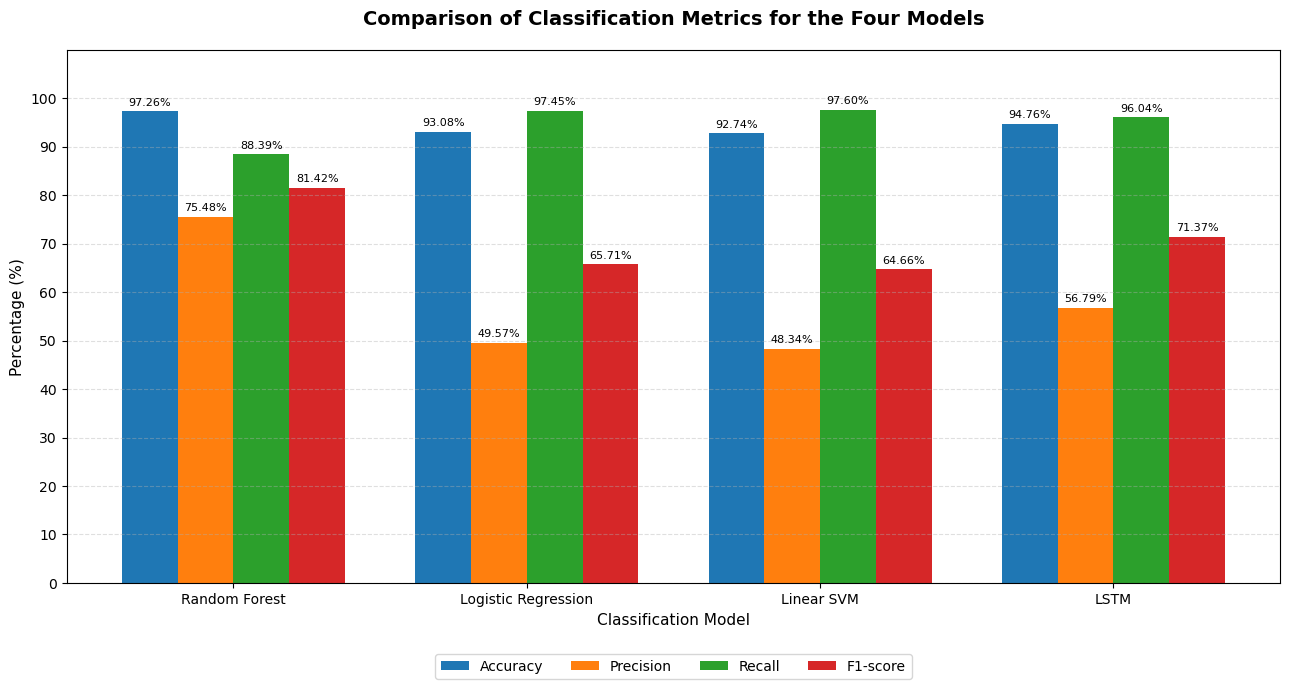

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Comparison of Classification Metrics

models = [
    "Random Forest",
    "Logistic Regression",
    "Linear SVM",
    "LSTM"
]

accuracy = [97.26, 93.08, 92.74, 94.76]
precision = [75.48, 49.57, 48.34, 56.79]
recall = [88.39, 97.45, 97.60, 96.04]
f1_score = [81.42, 65.71, 64.66, 71.37]

x = np.arange(len(models))
width = 0.19

fig, ax = plt.subplots(figsize=(13, 7))

bars1 = ax.bar(
    x - 1.5 * width, accuracy, width,
    label="Accuracy"
)
bars2 = ax.bar(
    x - 0.5 * width, precision, width,
    label="Precision"
)
bars3 = ax.bar(
    x + 0.5 * width, recall, width,
    label="Recall"
)
bars4 = ax.bar(
    x + 1.5 * width, f1_score, width,
    label="F1-score"
)

# Add percentage labels above the bars
for bars in [bars1, bars2, bars3, bars4]:
    ax.bar_label(
        bars,
        fmt="%.2f%%",
        padding=3,
        fontsize=8
    )

ax.set_title(
    "Comparison of Classification Metrics for the Four Models",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Classification Model", fontsize=11)
ax.set_ylabel("Percentage (%)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=0)

ax.set_ylim(0, 110)
ax.set_yticks(np.arange(0, 101, 10))
ax.grid(axis="y", linestyle="--", alpha=0.4)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=True
)

plt.tight_layout()

# Save the figure for your research report
plt.savefig(
    "Figure_4_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
#(Rainio et al., 2024; Gaudreault and Branco, 2024; Saito and Rehmsmeier, 2015; Chicco and Jurman, 2020)

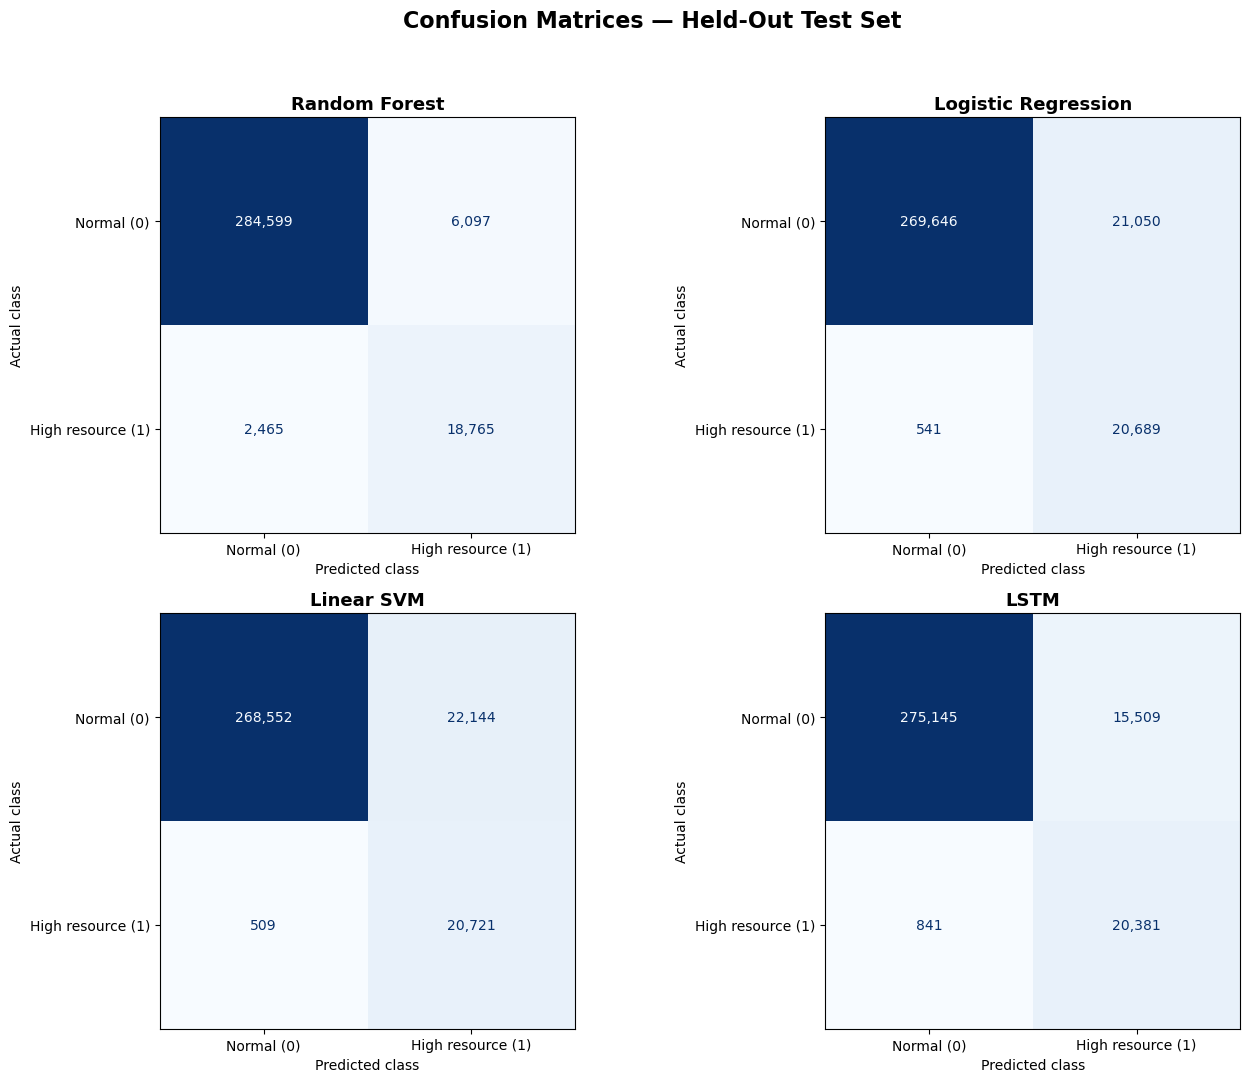

In [ ]:

# Evaluation Visualisation Confusion Matrices

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define each model and its corresponding test labels.
models_for_confusion = [
    (
        "Random Forest",
        y_test_array,
        rf_test_predictions
    ),
    (
        "Logistic Regression",
        y_test_array,
        logistic_test_predictions
    ),
    (
        "Linear SVM",
        y_test_array,
        svm_test_predictions
    ),
    (
        "LSTM",
        y_lstm_test_array,
        lstm_test_predictions
    )
]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for ax, (model_name, y_true, y_pred) in zip(
    axes, models_for_confusion
):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal (0)", "High resource (1)"]
    )

    cm_display.plot(
        ax=ax,
        cmap="Blues",
        values_format=",d",
        colorbar=False
    )

    ax.set_title(model_name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

fig.suptitle(
    "Confusion Matrices — Held-Out Test Set",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


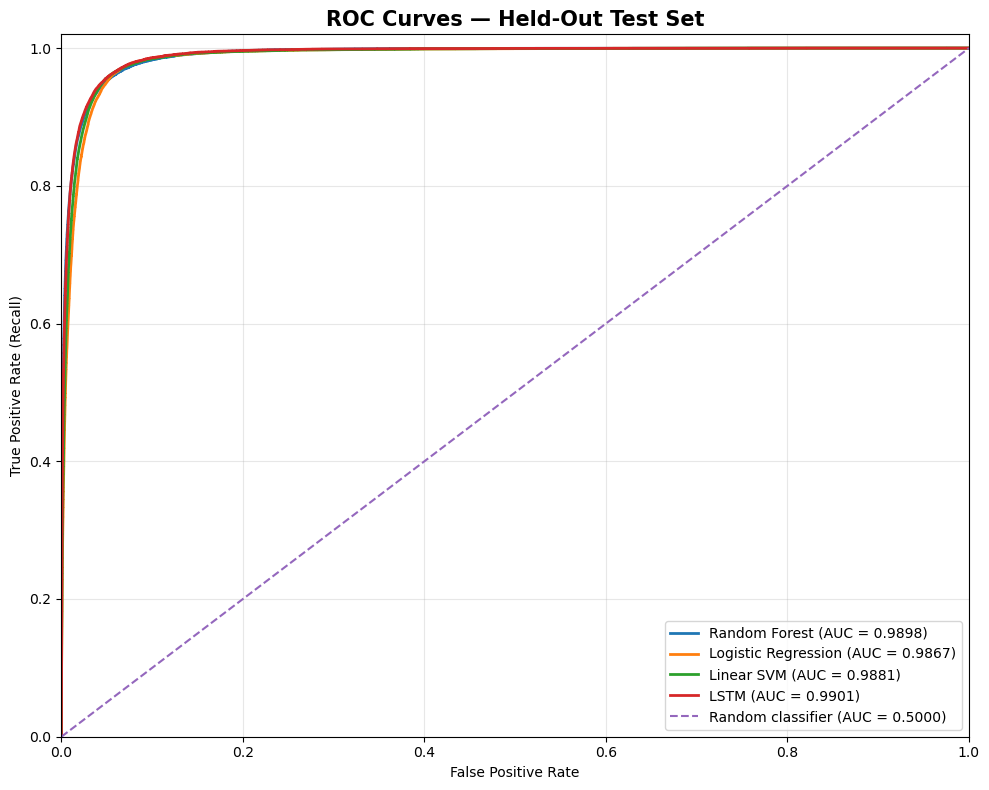

In [ ]:
#Evaluation Visualisation ROC Curves

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Model names, true labels, and continuous prediction scores.
# LinearSVC uses decision scores rather than probabilities.
roc_models = [
    (
        "Random Forest",
        y_test_array,
        rf_test_probabilities
    ),
    (
        "Logistic Regression",
        y_test_array,
        logistic_test_probabilities
    ),
    (
        "Linear SVM",
        y_test_array,
        svm_test_scores
    ),
    (
        "LSTM",
        y_lstm_test_array,
        lstm_test_probabilities
    )
]

plt.figure(figsize=(10, 8))

for model_name, y_true, y_scores in roc_models:
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )

# Reference line for random classification.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier (AUC = 0.5000)"
)

plt.title(
    "ROC Curves — Held-Out Test Set",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


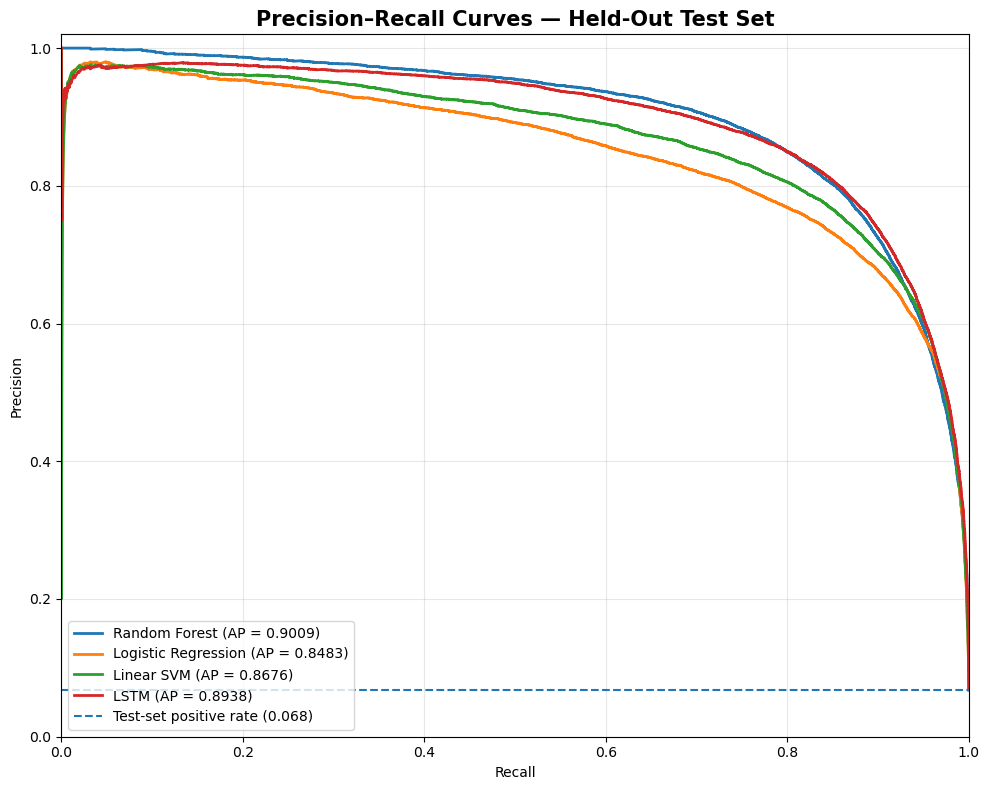

In [ ]:
# Evaluation Visualisation Precision-Recall Curves

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Model names, true labels, and continuous prediction scores.
pr_models = [
    (
        "Random Forest",
        y_test_array,
        rf_test_probabilities
    ),
    (
        "Logistic Regression",
        y_test_array,
        logistic_test_probabilities
    ),
    (
        "Linear SVM",
        y_test_array,
        svm_test_scores
    ),
    (
        "LSTM",
        y_lstm_test_array,
        lstm_test_probabilities
    )
]

plt.figure(figsize=(10, 8))

for model_name, y_true, y_scores in pr_models:
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        y_scores
    )

    avg_precision = average_precision_score(
        y_true,
        y_scores
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (AP = {avg_precision:.4f})"
    )


plt.axhline(
    y_test_array.mean(),
    linestyle="--",
    linewidth=1.5,
    label=f"Test-set positive rate ({y_test_array.mean():.3f})"
)

plt.title(
    "Precision–Recall Curves — Held-Out Test Set",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


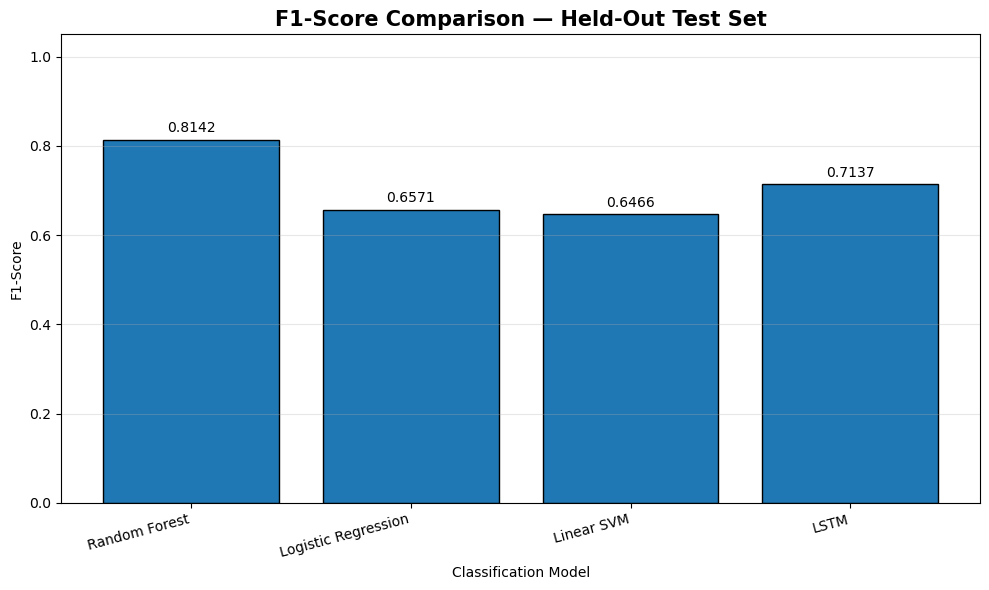

In [ ]:
# Evaluation Visualisation F1-Score Comparison

import matplotlib.pyplot as plt

# Use the final held-out test metrics.
model_names = [
    "Random Forest",
    "Logistic Regression",
    "Linear SVM",
    "LSTM"
]

f1_scores = [
    rf_test_metrics["F1-score"],
    logistic_test_metrics["F1-score"],
    svm_test_metrics["F1-score"],
    tuned_lstm_test_metrics["F1-score"]
]

# Create the comparison chart.
plt.figure(figsize=(10, 6))

bars = plt.bar(
    model_names,
    f1_scores,
    edgecolor="black"
)

# Display the F1-score above each bar.
for bar, score in zip(bars, f1_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{score:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title(
    "F1-Score Comparison — Held-Out Test Set",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Classification Model")
plt.ylabel("F1-Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


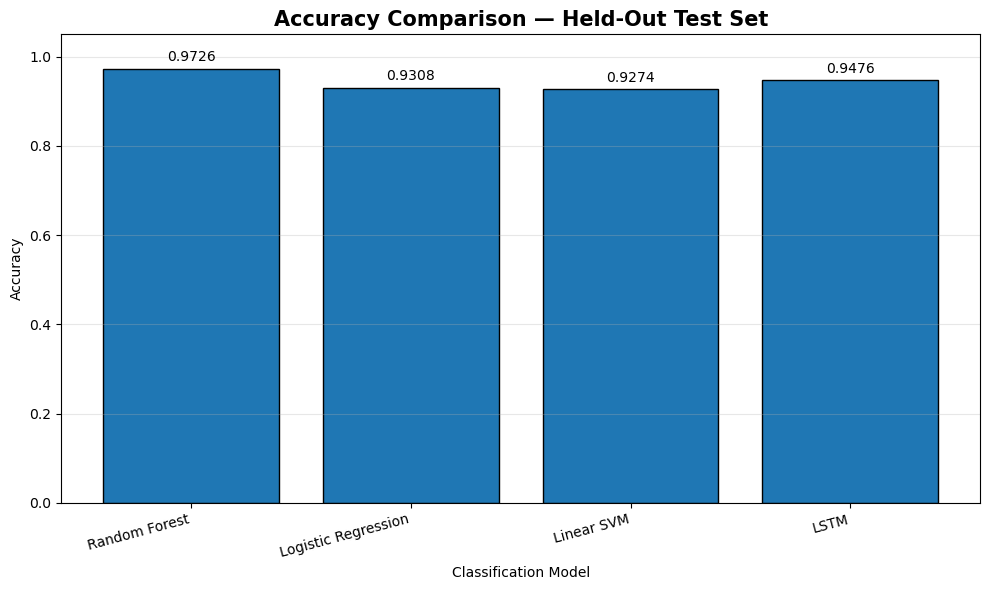

In [ ]:
#Evaluation Visualisation Accuracy Comparison

import matplotlib.pyplot as plt

# Retrieve accuracy scores from the current test metrics.
model_names = [
    "Random Forest",
    "Logistic Regression",
    "Linear SVM",
    "LSTM"
]

accuracy_scores = [
    rf_test_metrics["Accuracy"],
    logistic_test_metrics["Accuracy"],
    svm_test_metrics["Accuracy"],
    tuned_lstm_test_metrics["Accuracy"]
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    model_names,
    accuracy_scores,
    edgecolor="black"
)

# Add accuracy labels above each bar.
for bar, score in zip(bars, accuracy_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{score:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title(
    "Accuracy Comparison — Held-Out Test Set",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Classification Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


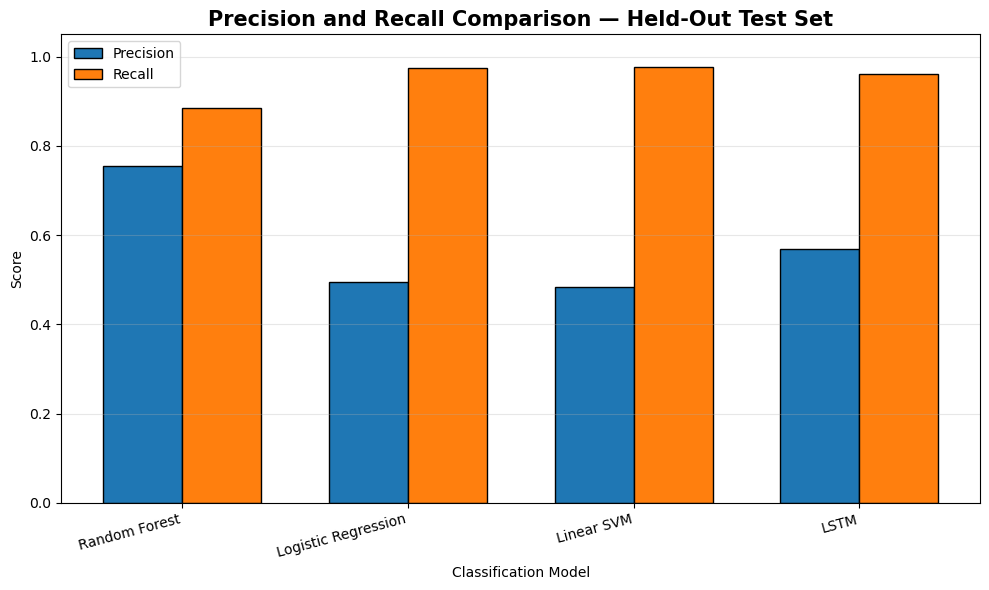

In [ ]:
#Evaluation Visualisation Precision and Recall Comparison

import numpy as np
import matplotlib.pyplot as plt

model_names = [
    "Random Forest",
    "Logistic Regression",
    "Linear SVM",
    "LSTM"
]

precision_scores = [
    rf_test_metrics["Precision"],
    logistic_test_metrics["Precision"],
    svm_test_metrics["Precision"],
    tuned_lstm_test_metrics["Precision"]
]

recall_scores = [
    rf_test_metrics["Recall"],
    logistic_test_metrics["Recall"],
    svm_test_metrics["Recall"],
    tuned_lstm_test_metrics["Recall"]
]

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width / 2,
    precision_scores,
    width,
    label="Precision",
    edgecolor="black"
)

ax.bar(
    x + width / 2,
    recall_scores,
    width,
    label="Recall",
    edgecolor="black"
)

ax.set_title(
    "Precision and Recall Comparison — Held-Out Test Set",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Classification Model")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


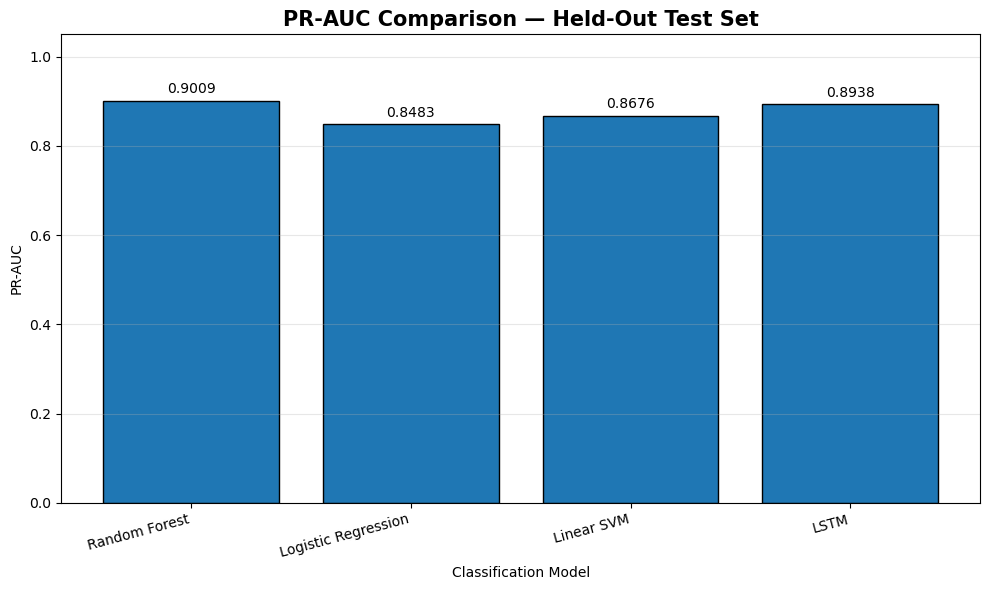

In [ ]:
# Evaluation Visualisation PR-AUC Comparison

import matplotlib.pyplot as plt

model_names = [
    "Random Forest",
    "Logistic Regression",
    "Linear SVM",
    "LSTM"
]

pr_auc_scores = [
    rf_test_metrics["PR-AUC"],
    logistic_test_metrics["PR-AUC"],
    svm_test_metrics["PR-AUC"],
    tuned_lstm_test_metrics["PR-AUC"]
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    model_names,
    pr_auc_scores,
    edgecolor="black"
)

for bar, score in zip(bars, pr_auc_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{score:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title(
    "PR-AUC Comparison — Held-Out Test Set",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Classification Model")
plt.ylabel("PR-AUC")
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
#Final Evaluation Metrics Consistency Check

import pandas as pd

final_metrics_check = pd.DataFrame([
    rf_test_metrics,
    logistic_test_metrics,
    svm_test_metrics,
    tuned_lstm_test_metrics
])

columns_to_check = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]

final_metrics_check = final_metrics_check[columns_to_check]

display(final_metrics_check.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Tuned Random Forest,0.9726,0.7548,0.8839,0.8142,0.9898,0.9009
1,Tuned Logistic Regression,0.9308,0.4957,0.9745,0.6571,0.9867,0.8483
2,Tuned Linear SVM,0.9274,0.4834,0.9760,0.6466,0.9881,0.8676
3,LSTM,0.9476,0.5679,0.9604,0.7137,0.9901,0.8938
